# Rosafe

*Same rain, different road.* **Veritas AI International High School Hackathon 2026, Climate track.**

For each of 855 Dallas-Fort Worth roads (state highways, toll roads and the busiest city streets) and each day, this
notebook predicts a **danger score**: how many crashes to expect compared with that road's normal day (1.0 is normal,
1.4 is 40% more). It uses the day's weather, the weeks of weather before it and how the road is built. An iPhone app
(built separately) reads the scores and chimes when you drive toward a road that is among the riskiest that day.

**Who it is for:** a DFW driver on a rainy day, deciding whether to slow down, leave earlier or take another road.
**What goes in:** daily weather at DFW Airport and each road's build. **What comes out:** a score per road per day,
and an alert list. **The test:** models train on 2021 to 2022, every choice is made on 2023, and 2024 is a final exam
opened once (step 14). Every result is compared with the simple guess "every day is normal".

### Results at a glance: the 2024 final exam (a year the model never saw), with the 2023 practice year in brackets

* **Does today's weather predict crashes?** On the four surface groups, Model A's miss is **4.3% lower** than "every
  day is normal"'s, real in 972 of 1,000 redraws (2023: 3.8%, 997). How much of it is rain: a one-line rain rule against
  the bar +0.9%, not real (773/1,000; 2023: +3.0%, real); Model A against that rule +3.5%, real (982/1,000; 2023: +0.9%,
  802/1,000, not real). So in 2024, unlike 2023, the other weather columns added a real gain beyond whether it rained.
* **Did we tune too hard on 2023?** (Test 10) Passed: 2024's Model A gain is in the same direction and at least half
  of 2023's (+4.3% against +3.8%).
* **Road by road**, Model D against "every day is normal" on the 38 busy roads: +1.0%, real (953/1,000; 2023: +0.9%,
  real); it beats the bar on 8 of the 10 busiest (2023: 6; the pass line was 7).
* **Which busy roads get worst in rain:** rank match +0.52 (2023: +0.45), against +0.47 for each road's earlier
  rain-day record (2023: +0.47). The model was higher in 772 of 1,000 redraws, so not clearly better (2023: 385).
* **The alert the app ships** warns only on days with rain or ice, picked on 2023 (where most of the model's edge was
  rain) from several versions, before 2024 was opened. Its flagged road-days ran **31.0% above normal** (2023: +43.1%),
  still well above +8.2% for "warn on every road whenever it rains" (2023: +16.8%), in a year whose road-days ran -2.2%
  against normal overall (2023: +0.1%). On the busy roads it was right 20.9% of the time and caught 23.2% of bad days
  (2023: 25.7% and 17.3%). The plan's own alert test (Test 6, on its first rule): failed (2023: failed).
* **Did weather history, surface or road build help, day by day?** No real gain: weather history -0.6% and surface
  +0.8% on rain days (350 and 685 of 1,000), road build +0.3% (948 of 1,000; real needs 950) (2023: nothing we could
  tell apart from luck).
* **Research claims, 2021 to 2024:** surface held (on the six roads with both surfaces, asphalt over concrete jumps
  more than concrete on a first rain); first rain and heat did not (2021 to 2023: surface held, first rain and heat
  did not). In 2024 alone, none of the three held.
* **Where it fails** (step 15): Wed Jan 17, 2024, a dry day just after the mid-January freeze, is one of the 5 worst
  days on the busy roads: they ran 1.22 against a predicted 0.66. Probably leftover ice, as on Feb 3, 2023: people
  went back out while ice was still on the roads, and the daily weather record shows only a dry day. The model
  predicted below normal, and the app warns only on days with rain or ice, so it stayed quiet.

### Contents
1. Three claims written before any result · 2. Data and checks · 3. Roads (855 in three layers) · 4. Weather (37
columns) · 5. The normal and the danger score · 6. Road shapes for the map · 7. App files, demo routes, hand checks
· 8. Model table, simple guesses, how we score · 9. Models A to C · 10. Model D, every road · 11. Honesty tests and the
claims · 12. The alert rule and the 2023 file · 13. Road-chemistry layer (decision model) · 14. The 2024 final exam
· 15. Where it fails · 16. Figures

## Step 1. Three claims, written before looking at any crash-versus-weather result

These come from earlier research, not from our data. They were written down before anything in this
notebook compared crashes with rain, so nothing here is tuned to the answer.

1. **First rain.** Rain after 7 or more dry days brings a bigger jump in crashes than rain the day after rain.
   Background: UC Berkeley, 2003, https://newsarchive.berkeley.edu/news/media/releases/2003/10/31_rain.shtml
2. **Surface.** We check whether that first-rain jump differs between asphalt-over-concrete and plain concrete
   stretches of the six roads that have long stretches of both (IH 30, IH 635, IH 20, IH 35E, IH 35W, SL 12).
   No direction is claimed.
3. **Heat.** Summer rain after 3 or more hot days is worse on asphalt-type surfaces than on concrete.
   Background: Texas A&M Transportation Institute, https://tti.tamu.edu/2013/08/06/get-a-grip
   (link note added Nov 15: that page has moved to https://pavements.tti.tamu.edu/2013/08/06/get-a-grip-new-fine-pfc-offsets-bleeding-flushing-on-roadways/)

Each claim is checked on 2021 to 2024, with 2024 shown alone next to it. A claim holds if the gap has the
stated direction in 950 of 1,000 redraws of whole weeks. The answer is "held", "did not hold" or
"too few days to tell".

*Note added Nov 14, ~11:45 PM, after a cold audit and before 2024 was opened:* the claims above are unchanged, but
the tests became stricter. Claim 2 now measures each surface's first-rain jump against its own dry days and,
since it claims no direction, needs 975 of 1,000 on either side. Claim 3 is now tested as a heat effect (the
hot-then-rain jump over other summer rain, asphalt-type minus concrete). Step 11 shows the old numbers next to the new ones.

## Step 2. Get the data and check it

**Crashes:** Texas Department of Transportation, Crash Records Information System (CRIS), 2020 to 2024, accessed
Nov 14, 2026 through TxDOT's public map layer "TXDOT Statewide Bicyclist Involved Crashes"
(https://www.arcgis.com/home/item.html?id=93b84dccf1ec4440b1475c4290ac21ff). Despite its title the layer holds every
crash. We checked its yearly death counts against TxDOT's published totals (2023 matches exactly, 2022 and 2024 are
within 10). TxDOT's terms do not allow passing the raw file on, so this notebook downloads it when it runs, the file
is kept out of the repo, and the notebook never shows more than 5 raw rows.

**Weather:** NOAA's daily record (GHCN-Daily) for DFW Airport, station USW00003927, read straight from NOAA
(https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/USW00003927.csv). These are
measured values, not a weather model.

In [1]:
import os
import subprocess
import sys
import urllib.request

import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 160, "display.max_columns", 40)

# The saved outputs came from the versions pinned in requirements.txt. Other versions run fine, but scikit-learn's
# gradient boosting can shift Model D's numbers a little (with scikit-learn 1.6.1 every verdict stayed the same).
import matplotlib
import sklearn
print(f"Python {sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}, "
      f"scikit-learn {sklearn.__version__}, matplotlib {matplotlib.__version__}")

CRASH_FILE = "dfw_crashes_2020_2024.csv.gz"
SCRIPT = "get_dfw_crashes.py"
SCRIPT_URL = "https://raw.githubusercontent.com/jacob-gorny/rosafe/main/notebook/get_dfw_crashes.py"
NOAA_URL = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/USW00003927.csv"

# Running outside the repo (for example in Google Colab)? Fetch the repo, which holds the helper module, the background
# sheets and the folders this notebook writes to, and work from its notebook folder. No crash data is in the repo.
REPO_URL = "https://github.com/jacob-gorny/rosafe.git"
if not (os.path.exists("chemistry_layer.py") and os.path.isdir(os.path.join("..", "docs"))):
    if not os.path.isdir("rosafe"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    os.chdir(os.path.join("rosafe", "notebook"))
    print("Working in", os.getcwd())

if not os.path.exists(CRASH_FILE):
    if not os.path.exists(SCRIPT):
        urllib.request.urlretrieve(SCRIPT_URL, SCRIPT)
    print("Downloading crashes from TxDOT (a few minutes)...")
    subprocess.run([sys.executable, SCRIPT], check=True)

crashes = pd.read_csv(CRASH_FILE, low_memory=False)
crashes["date"] = pd.to_datetime(crashes["crash_date"])
crashes["year"] = crashes["date"].dt.year

by_year = crashes.groupby("year").size()
surfaced = crashes["surf_type_id"].notna()
assert len(crashes) == 679_621, len(crashes)
assert by_year.tolist() == [123_267, 142_028, 140_634, 140_541, 133_151], by_year.tolist()
assert (crashes["onsys_fl"] == 1).sum() == 356_024
assert surfaced.sum() == 329_253
assert crashes[surfaced].groupby("year").size().tolist() == [59_078, 69_481, 67_094, 68_034, 65_566]
assert crashes["date"].nunique() == 1_827
assert crashes["crash_time"].isna().sum() == 0
no_position = (crashes["latitude"].isna() | crashes["longitude"].isna()).mean()
assert 0.06 < no_position < 0.08, no_position
print(f"{len(crashes):,} crashes, {crashes['date'].nunique():,} days, {no_position:.1%} without a map position")
print(by_year.to_string())

Python 3.12.13, pandas 3.1.1, numpy 2.5.4, scikit-learn 1.9.1, matplotlib 3.11.2


679,621 crashes, 1,827 days, 7.2% without a map position
year
2020    123267
2021    142028
2022    140634
2023    140541
2024    133151


## Step 3. Roads

A state road's name comes from TxDOT's highway fields (IH 35E, SH 289); toll roads and city streets come from the
street name. We score 855 roads in three layers,
chosen on 2021 to 2023 crash counts only, so 2024 plays no part in which roads are in:

* **State roads:** one road plus one surface group (concrete, asphalt over concrete, asphalt, surface-treated).
  These carry surface, lanes and daily traffic. Surface codes 1, 2, 3, 4 and 7 were decoded by matching 308 crashes
  against the City of Lewisville's labelled crash layer (zero mismatches). Codes 5, 6 and 10 follow TxDOT's standard
  list and were not cross-checked.
* **Toll roads:** TxDOT road class 6, grouped by toll road. Almost none of their crashes carry surface, lanes or
  traffic (3%, mostly on the IH 35E and IH 635 toll lanes), so the model treats them as unknown.
* **City streets:** city streets and county roads, keyed by street name and city. Only road class and speed limit.
  The 589 scored streets carry about half (54%) of city-street crashes in 2021 to 2023, so this is not every DFW street.

A road needs at least 50 crashes in 2021 to 2023 (about one every three weeks) to be scored. Below that, its
normal comes from a handful of crashes and its map line would sit too close to single crash locations.
Road class 9 (probably parking-lot crashes, filed under the nearest street) is left out.

**Note:** the road list and the busy/quiet split use crash counts from 2021 to 2023, so the practice year (2023)
helps choose its own sample. Our plan (CLAUDE.md) allows choices on 2023, and the final test year (2024) plays no part in
choosing roads. Whether this nudges the 2023 numbers up or down is untested; 2024 is free of it.

In [2]:
SURFACE_GROUP = {1: "concrete", 2: "concrete", 3: "concrete", 7: "asphalt_over_concrete",
                 4: "asphalt", 5: "asphalt", 6: "asphalt", 10: "surface_treated"}
ROAD_CLASS = {1: "interstate", 2: "us_state_highway", 3: "farm_to_market", 4: "county_road",
              5: "city_street", 6: "tollway"}
MIN_CRASHES = 50
SELECT_YEARS = (2021, 2023)

nbr = crashes["hwy_nbr"].astype("Int64").astype(str).replace("<NA>", "")
crashes["road"] = (crashes["hwy_sys"].fillna("").astype(str).str.strip() + " " + nbr
                   + crashes["hwy_sfx"].fillna("").astype(str).str.strip()).str.strip()
crashes["surface"] = crashes["surf_type_id"].map(SURFACE_GROUP)


def toll_name(row):
    """One name per toll road, merging TxDOT's spellings."""
    if row["onsys_fl"] == 1:
        road = row["road"]
        if road in ("SH 190", "SH 161"):
            return "President George Bush Turnpike"
        if road == "SH 121" and row["county"] in ("Collin", "Denton"):
            return "Sam Rayburn Tollway"
        if road == "SH 360":
            return "360 Tollway"
        return f"{road} toll lanes"
    s = str(row["street_name"])
    for key, name in [("DALLAS NORTH", "Dallas North Tollway"), ("DALLAS PKWY", "Dallas North Tollway"),
                      ("GEORGE BUSH", "President George Bush Turnpike"), ("CHISHOLM", "Chisholm Trail Parkway"),
                      ("SAM RAYBURN", "Sam Rayburn Tollway"), ("360 T", "360 Tollway"),
                      ("LYNDON B JOHNSON", "IH 635 toll lanes"), ("121 EXPRESS", "SH 121 toll lanes")]:
        if key in s:
            return name
    return None if s in ("UNKNOWN", "nan") else s.title()


layer = pd.Series(pd.NA, index=crashes.index, dtype="object")
unit = pd.Series(pd.NA, index=crashes.index, dtype="object")

is_state = (crashes["onsys_fl"] == 1) & (crashes["road_cls_id"] != 6) & crashes["surface"].notna()
layer[is_state] = "state"
unit[is_state] = crashes.loc[is_state, "road"] + " | " + crashes.loc[is_state, "surface"]

is_toll = crashes["road_cls_id"] == 6
names = crashes[is_toll].apply(toll_name, axis=1)
layer[is_toll & names.reindex(crashes.index).notna()] = "toll"
unit[is_toll] = ("TOLL | " + names.fillna("")).where(names.notna())

is_city = (crashes["onsys_fl"] == 0) & crashes["road_cls_id"].isin([4, 5]) & crashes["street_name"].notna()
layer[is_city] = "city"
city_key = crashes.loc[is_city, "city_id"].astype("Int64").astype(str)
outside = city_key == "9999"                       # TxDOT's code for "outside any city": add the county
city_key[outside] = "9999-" + crashes.loc[is_city, "cnty_id"][outside].astype("Int64").astype(str)
unit[is_city] = "CITY | " + crashes.loc[is_city, "street_name"].str.strip() + " | " + city_key

crashes["layer"], crashes["unit"] = layer, unit.where(layer.notna())

sel = crashes[crashes["year"].between(*SELECT_YEARS) & crashes["unit"].notna()]
counts = sel.groupby("unit").size()
keep = counts[counts >= MIN_CRASHES].index
DAYS_SELECT = (pd.Timestamp(f"{SELECT_YEARS[1]}-12-31") - pd.Timestamp(f"{SELECT_YEARS[0]}-01-01")).days + 1


def mode(s):
    s = s.dropna()
    return s.mode().iloc[0] if len(s) else np.nan


def median_known(s, bad=(-1, 0)):
    s = s[~s.isin(bad)].dropna()
    return float(s.median()) if len(s) else np.nan


def display_name(r):
    if r["layer"] == "toll":
        return r["unit"].split(" | ")[1]
    if r["layer"] == "city":
        return r["unit"].split(" | ")[1].title()
    sys_, num = r["road_name"].split(" ", 1)
    pretty = {"IH": "I-", "US": "US ", "SH": "SH ", "SL": "Loop ", "FM": "FM ", "SS": "Spur ", "BI": "Business I-",
              "BU": "Business US ", "BS": "Business SH ", "PA": "Park Road ", "RM": "RM "}.get(sys_, sys_ + " ")
    return pretty + num


g = sel[sel["unit"].isin(keep)].groupby("unit")
roads = pd.DataFrame({
    "layer": g["layer"].first(),
    "road_name": g["road"].first(),
    "surface": g["surface"].first(),
    "road_class": g["road_cls_id"].agg(mode).map(ROAD_CLASS),
    "func_sys": g["func_sys_id"].agg(mode),
    "speed_limit": g["crash_speed_limit"].agg(median_known),
    "lanes": g["nbr_of_lane"].agg(median_known),
    "daily_traffic": g["adt_curnt_amt"].agg(median_known),
    "crashes_2021_2023": g.size(),
}).reset_index()
roads["per_day"] = roads["crashes_2021_2023"] / DAYS_SELECT
roads["busy"] = roads["per_day"] >= 1
roads.loc[roads["layer"] != "state", ["surface", "lanes", "daily_traffic"]] = np.nan
roads.loc[roads["layer"] != "state", "func_sys"] = np.nan
roads["display_name"] = roads.apply(display_name, axis=1)
roads = roads.sort_values(["layer", "per_day"], ascending=[True, False]).reset_index(drop=True)

summary = roads.groupby("layer").agg(roads=("unit", "size"), busy=("busy", "sum"),
                                     crashes_per_day=("per_day", "sum")).round(1)
print(summary.to_string())
print(f"\nAll layers: {len(roads):,} roads")
for lyr in ["state", "toll", "city"]:
    covered = roads.loc[roads.layer == lyr, "crashes_2021_2023"].sum() / (sel["layer"] == lyr).sum()
    print(f"  {lyr:5s} roads cover {covered:.0%} of that layer's crashes in 2021 to 2023")
print("\nBusiest 10:")
print(roads.sort_values("per_day", ascending=False).head(10)[["display_name", "layer", "surface", "per_day"]]
      .round(1).to_string(index=False))
print("\nToll roads:")
print(roads[roads.layer == "toll"][["display_name", "per_day"]].round(2).to_string(index=False))

       roads  busy  crashes_per_day
layer                              
city     589     0             81.2
state    258    35            182.3
toll       8     3              8.6

All layers: 855 roads
  state roads cover 98% of that layer's crashes in 2021 to 2023
  toll  roads cover 95% of that layer's crashes in 2021 to 2023
  city  roads cover 54% of that layer's crashes in 2021 to 2023

Busiest 10:
        display_name layer               surface  per_day
               I-35E state asphalt_over_concrete     17.0
               US 75 state              concrete      9.9
                I-30 state              concrete      9.2
                I-20 state asphalt_over_concrete      9.2
               I-635 state              concrete      8.5
                I-30 state asphalt_over_concrete      6.1
               I-35W state              concrete      5.2
              SH 183 state asphalt_over_concrete      5.0
Dallas North Tollway  toll                   NaN      4.1
            

### Two daily tables from one function

One row per unit per day, 2020 to 2024, with a 0 on days with no crashes. 2020 stays in the tables only so
early-2021 rows can look back 8 weeks. Models never train on 2020, because COVID changed traffic.
The surface table counts every crash with a surface code, including about 1,000 on toll lanes that also have one
(so its totals match the planning numbers); the road table puts toll lanes in the toll layer instead.

In [3]:
ALL_DAYS = pd.date_range("2020-01-01", "2024-12-31", freq="D")
assert len(ALL_DAYS) == 1_827


def daily_table(df, key, units):
    """Crashes per unit per day, with every day present (0 when nothing happened)."""
    c = df[df[key].isin(units)].groupby([key, "date"]).size()
    full = pd.MultiIndex.from_product([sorted(units), ALL_DAYS], names=["unit", "date"])
    return c.reindex(full, fill_value=0).rename("crashes").reset_index()


surface_daily = daily_table(crashes[crashes["surface"].notna()], "surface", crashes["surface"].dropna().unique())
road_daily = daily_table(crashes, "unit", roads["unit"])

assert len(surface_daily) == 4 * 1_827 == 7_308
assert len(road_daily) == len(roads) * 1_827
assert surface_daily["crashes"].sum() == crashes["surface"].notna().sum()
per_day = surface_daily.groupby("unit")["crashes"].mean().round(1)
print("Surface table, crashes per day 2020 to 2024:", per_day.to_dict())
print(f"Road table: {len(road_daily):,} rows ({len(roads):,} roads x 1,827 days)")

Surface table, crashes per day 2020 to 2024: {'asphalt': 27.7, 'asphalt_over_concrete': 65.2, 'concrete': 82.9, 'surface_treated': 4.5}
Road table: 1,562,085 rows (855 roads x 1,827 days)


## Step 4. Weather

Every column NOAA filled for DFW Airport in 2020 to 2024, except the rarely filled peak-gust time. A rain day is at
least 0.3 mm (0.01 inch).
A hot day is 95 F (35 C) or more. History columns look only at days before today, except that two of them (dry days
and hot days before today's rain) are filled in only when it rains today.

We do not use the crash file's own weather or wet-road fields: an officer fills those in after the crash,
so they would leak the answer.

**One honest assumption:** "today's weather" here is the whole day as NOAA measured it (total rain, high, low,
any thunder or fog), including hours after some crashes happened. That stands in for a perfect morning forecast.
A live version would use the forecast instead and would do worse, by an amount we have not measured: knowing only
yesterday's weather, Model A's edge falls from 3.8% to 0.4% (step 11). This is listed in the README's limits.
The ice flag counts hail and small hail only on cold days (low at or below 2 C); warm spring hail is a storm.

In [4]:
w = pd.read_csv(NOAA_URL, low_memory=False)
w["date"] = pd.to_datetime(w["DATE"])
w = w[w["date"].between("2020-01-01", "2024-12-31")].set_index("date").sort_index()
assert len(w) == 1_827 and w.index.equals(ALL_DAYS)

wx = pd.DataFrame(index=w.index)
wx["rain_mm"] = w["PRCP"] / 10
wx["snow_mm"] = w["SNOW"]
wx["snow_depth_mm"] = w["SNWD"]
wx["high_c"] = w["TMAX"] / 10
wx["low_c"] = w["TMIN"] / 10
wx["dew_point_c"] = w["ADPT"] / 10
wx["wet_bulb_c"] = w["AWBT"] / 10
wx["humidity_avg"] = w["RHAV"]
wx["humidity_min"] = w["RHMN"]
wx["humidity_max"] = w["RHMX"]
wx["pressure_sea_hpa"] = w["ASLP"] / 10
wx["pressure_station_hpa"] = w["ASTP"] / 10
wx["wind_avg_ms"] = w["AWND"] / 10
wx["gust_2min_ms"] = w["WSF2"] / 10
wx["gust_5sec_ms"] = w["WSF5"] / 10
for col, name in [("WDF2", "dir_2min"), ("WDF5", "dir_5sec")]:
    rad = np.deg2rad(w[col])
    wx[f"{name}_sin"], wx[f"{name}_cos"] = np.sin(rad), np.cos(rad)

flag = lambda c: w[c].notna().astype(int)
wx["fog"] = flag("WT01")
wx["heavy_fog"] = flag("WT02")
wx["thunder"] = flag("WT03")
wx["haze"] = (flag("WT08") | flag("WT07")).astype(int)
wx["sleet"] = flag("WT04")
wx["hail"] = flag("WT05")
wx["glaze"] = flag("WT06")

wx["rained"] = (wx["rain_mm"] >= 0.3).astype(int)
wx["hot"] = (wx["high_c"] >= 35.0).astype(int)
wx["freezing"] = (((wx["rained"] == 1) | (wx["snow_mm"] > 0)) & (wx["low_c"] <= 0)).astype(int)
cold = wx["low_c"] <= 2.0                          # warm-season hail and small hail are storms, not ice
wx["ice"] = (wx["glaze"].astype(bool) | wx["freezing"].astype(bool) | (wx["snow_mm"] > 0)
             | ((wx["sleet"].astype(bool) | wx["hail"].astype(bool) | flag("WT09").astype(bool)) & cold)).astype(int)

# Weather history: days before today (dry days and hot days before today's rain are filled in only on rain days). Rain
# history counts from 2019-01 so early-2020 values are real.
w_hist = pd.read_csv(NOAA_URL, low_memory=False, usecols=["DATE", "PRCP", "TMAX"])
w_hist["date"] = pd.to_datetime(w_hist["DATE"])
w_hist = w_hist[w_hist["date"].between("2019-01-01", "2024-12-31")].set_index("date").sort_index()
rained_h = (w_hist["PRCP"] / 10 >= 0.3).astype(int)
hot_h = (w_hist["TMAX"] / 10 >= 35.0).astype(int)

last_rain = pd.Series(np.where(rained_h == 1, np.arange(len(rained_h)), np.nan), index=rained_h.index)
last_rain_before = last_rain.shift(1).ffill()
days_since = (np.arange(len(rained_h)) - last_rain_before).rename("days_since_rain")
wx["days_since_rain"] = days_since.reindex(wx.index)
wx["rain_last_7_mm"] = (w_hist["PRCP"] / 10).shift(1).rolling(7).sum().reindex(wx.index)
wx["hot_days_last_7"] = hot_h.shift(1).rolling(7).sum().reindex(wx.index)
wx["dry_days_before_rain"] = np.where(wx["rained"] == 1, wx["days_since_rain"] - 1, 0)
wx["hot_days_before_rain"] = np.where(wx["rained"] == 1, wx["hot_days_last_7"], 0)
wx["ice_last_3"] = wx["ice"].shift(1).rolling(3, min_periods=1).max().fillna(0)

# A few days are blank in the humidity, pressure and wind columns. Carry the day before forward
# (never the day after, so no future weather leaks in).
missing = wx.isna().sum()
print("Blank days filled from the day before:", missing[missing > 0].to_dict())
assert missing.max() <= 15, missing.max()
wx = wx.ffill()
assert wx.isna().sum().sum() == 0, wx.columns[wx.isna().any()].tolist()

# Holidays: US federal holidays plus the day after Thanksgiving.
from pandas.tseries.holiday import USFederalHolidayCalendar
hol = USFederalHolidayCalendar().holidays("2020-01-01", "2024-12-31")
thanksgiving = [d for d in hol if d.month == 11 and d.day >= 22]
wx["holiday"] = wx.index.isin(hol.union(pd.DatetimeIndex(thanksgiving) + pd.Timedelta(days=1))).astype(int)

# Checks against the numbers worked out in planning.
yr = wx.index.year
r21 = wx[(yr >= 2021)]
assert wx["rained"].sum() == 405
assert r21["rained"].sum() == 311
assert ((r21["rained"] == 1) & (r21["dry_days_before_rain"] >= 7)).sum() == 50
assert ((r21["rained"] == 1) & (r21["days_since_rain"] == 1)).sum() == 132
summer = r21[r21.index.month.isin(range(5, 10)) & (r21["rained"] == 1)]
assert len(summer) == 118 and (summer["hot_days_last_7"] >= 3).sum() == 45
y24 = wx[yr == 2024]
assert y24["rained"].sum() == 92
assert ((y24["rained"] == 1) & (y24["dry_days_before_rain"] >= 7)).sum() == 10
assert ((y24["rained"] == 1) & (y24["hot_days_last_7"] >= 3)).sum() == 13
assert wx["hot"].sum() == 334
assert wx.groupby(yr)["freezing"].sum().tolist() == [3, 4, 7, 4, 5]

print(f"{wx.shape[1]} weather columns for {len(wx):,} days")
print(wx.groupby(yr)[["rained", "thunder", "fog", "heavy_fog", "haze", "ice", "hot", "holiday"]].sum().to_string())

Blank days filled from the day before: {'dew_point_c': 8, 'wet_bulb_c': 8, 'humidity_avg': 7, 'humidity_min': 7, 'humidity_max': 7, 'pressure_sea_hpa': 8, 'pressure_station_hpa': 8, 'wind_avg_ms': 1, 'gust_2min_ms': 1, 'gust_5sec_ms': 4, 'dir_2min_sin': 1, 'dir_2min_cos': 1, 'dir_5sec_sin': 4, 'dir_5sec_cos': 4}
37 weather columns for 1,827 days
      rained  thunder  fog  heavy_fog  haze  ice  hot  holiday
date                                                          
2020      94       62  118          8    22    3   42       11
2021      87       61   99         11    37    8   48       13
2022      61       46   76          9    25   10   88       11
2023      71       61   83          5    32    4   89       12
2024      92       62  103         10    46    5   67       12


## Step 5. The normal and the danger score

**Danger score = crashes on that road that day ÷ its normal.** 1.0 is a normal day.

On a test day, the normal has to come only from earlier days, or it would leak the answer. Two kinds:

* **Busy roads and the surface groups (1 or more crashes a day):** the road's own average over the previous
  8 weeks, times a weekday factor (Fridays run higher than Sundays) learned from the training years.
  Eight weeks follows the seasons and any slow drift in traffic.
* **Quiet roads (under 1 a day):** 8 weeks of a quiet road is only a handful of crashes, so its own recent
  average is mostly noise. Instead, a **pooled** normal: the road's training-years average, times its layer's weekday factor,
  times its layer's 8-week trend (all state, toll or city crashes over the last 8 weeks against their
  training-years average). The road sets its level, and the whole layer sets the season and the weekday.

We also score the simpler **fixed normal** (training-years weekday average, no 8-week part) and keep whichever
makes 2023 scores swing less around 1.0 (measured as the average gap between a day's score and 1.0): a better
normal leaves less unexplained up-and-down. We run that check
twice: with normals learned on 2021 to 2022, and with normals learned on 2021 alone (two years stale).

**What we kept, and why** (numbers printed below): the four surface groups keep the 8-week normal
(0.237 against 0.244). Busy roads keep the **fixed** normal (0.579 against 0.592). For a road with 1 to 17
crashes a day, an 8-week average is noisy enough that it hurts more than following the seasons helps. The fixed
normal still wins when it is two years old (0.580 against 0.597). Quiet roads keep the pooled normal, which wins when stale
(0.504 against 0.511) and ties when fresh (0.500 against 0.496). The differences are small: no choice here
makes or breaks the model.

Practice split: train 2021 to 2022, choose on 2023. 2024 is cut off here and only comes back in step 14.

In [5]:
QUIET_CUTOFF = 1.0      # crashes a day; below this a road uses the pooled normal
LOOKBACK = 56           # 8 weeks
PRACTICE = dict(train_years=(2021, 2022), end="2023-12-31")


def add_score(daily, train_years, end, group_of=None, quiet=None, main="rolling"):
    """Add weekday_factor, the normals and the danger score. On test days only earlier days feed the normal; training
    rows use the training years' averages.
    main: which normal busy units use ("rolling" or "fixed"). Quiet units use the pooled normal."""
    d = daily[daily["date"] <= end].sort_values(["unit", "date"]).copy()
    d["weekday"] = d["date"].dt.day_of_week
    train = d[d["date"].dt.year.between(*train_years)]

    unit_mean = train.groupby("unit")["crashes"].mean()
    wd = train.groupby(["unit", "weekday"])["crashes"].mean().div(unit_mean, level="unit").rename("wd_unit")
    d = d.join(wd, on=["unit", "weekday"])
    d["train_mean"] = d["unit"].map(unit_mean)

    past = d.groupby("unit")["crashes"].transform(lambda s: s.shift(1).rolling(LOOKBACK).mean())
    d["normal_rolling"] = past * d["wd_unit"]
    d["normal_fixed"] = d["train_mean"] * d["wd_unit"]
    d["normal"] = d["normal_" + main]

    if group_of is not None:
        d["group"] = d["unit"].map(group_of)
        g_day = d.groupby(["group", "date"])["crashes"].sum().rename("g_crashes").reset_index()
        g_day["weekday"] = g_day["date"].dt.day_of_week
        g_train = g_day[g_day["date"].dt.year.between(*train_years)]
        g_mean = g_train.groupby("group")["g_crashes"].mean()
        g_wd = g_train.groupby(["group", "weekday"])["g_crashes"].mean().div(g_mean, level="group").rename("wd_group")
        g_day = g_day.sort_values(["group", "date"])
        g_day["trend"] = (g_day.groupby("group")["g_crashes"].transform(lambda s: s.shift(1).rolling(LOOKBACK).mean())
                          / g_day["group"].map(g_mean))
        d = d.join(g_wd, on=["group", "weekday"]).merge(g_day[["group", "date", "trend"]], on=["group", "date"])
        d["normal_pooled"] = d["train_mean"] * d["wd_group"] * d["trend"]
        q = d["unit"].map(quiet).astype(bool)
        d.loc[q, "normal"] = d.loc[q, "normal_pooled"]

    d["score"] = d["crashes"] / d["normal"]
    return d.sort_values(["unit", "date"]).reset_index(drop=True)


quiet = roads.set_index("unit")["per_day"] < QUIET_CUTOFF
layer_of = roads.set_index("unit")["layer"]
road_scored = add_score(road_daily, group_of=layer_of, quiet=quiet, **PRACTICE)
surface_scored = add_score(surface_daily, **PRACTICE)

for name, d in [("road", road_scored), ("surface", surface_scored)]:
    live = d[d["date"].dt.year >= 2021]
    assert (live["normal"] > 0).all(), f"{name}: normal <= 0 on {(live['normal'] <= 0).sum()} rows"
    assert live["normal"].notna().all()
assert road_scored["date"].max() == pd.Timestamp("2023-12-31"), "2024 must not be in the practice frame"
assert len(road_scored) == len(roads) * (1_827 - 366)

train_rows = lambda d: d[d["date"].dt.year.between(*PRACTICE["train_years"])]
surf_mean = train_rows(surface_scored).groupby("unit")["score"].mean()
busy_units = roads.loc[roads["busy"], "unit"]
assert len(busy_units) == 38 and (roads["busy"] & (roads["layer"] == "state")).sum() == 35, "busy counts changed: update the text"
tr_rs = train_rows(road_scored)
busy_mean = tr_rs[tr_rs["unit"].isin(busy_units)].groupby("unit")["score"].mean()
tr_quiet = tr_rs[~tr_rs["unit"].isin(busy_units)]
quiet_mean = tr_quiet.groupby(tr_quiet["unit"].map(layer_of))["score"].mean()
print("Mean score on training years (should sit near 1.0)")
print("  surface groups:", surf_mean.round(3).to_dict())
print(f"  busy roads: {busy_mean.min():.3f} to {busy_mean.max():.3f}")
print("  quiet roads by layer:", quiet_mean.round(3).to_dict())
assert surf_mean.between(0.95, 1.05).all(), surf_mean
assert busy_mean.between(0.9, 1.1).all(), busy_mean.sort_values()
assert quiet_mean.between(0.9, 1.1).all(), quiet_mean

# Which normal? Mean distance of the 2023 score from 1.0 (lower = the normal explains more).
y23 = lambda d: d[d["date"].dt.year == 2023]
rows = []
for label, d, units in [("surface groups", surface_scored, None), ("busy roads", road_scored, busy_units)]:
    s = y23(d) if units is None else y23(d)[y23(d)["unit"].isin(units)]
    rows.append({"units": label, "rolling 8 weeks": (s["crashes"] / s["normal_rolling"] - 1).abs().mean(),
                 "fixed": (s["crashes"] / s["normal_fixed"] - 1).abs().mean()})
qs = y23(road_scored)[~y23(road_scored)["unit"].isin(busy_units)]
qg = qs.groupby([qs["unit"].map(layer_of), "date"])[["crashes", "normal_pooled", "normal_fixed"]].sum()
rows.append({"units": "quiet roads, summed by layer and day", "pooled + trend": (qg["crashes"] / qg["normal_pooled"] - 1).abs().mean(),
             "fixed": (qg["crashes"] / qg["normal_fixed"] - 1).abs().mean()})
normal_choice = pd.DataFrame(rows).set_index("units").round(3)
print("\nHow far 2023 scores swing from 1.0 under each normal (lower is better):")
print(normal_choice.to_string())

# Drift check: a fixed normal only knows its training years. Train it on 2021 alone and score 2023,
# two years later, the same gap the app will face. Nothing here touches 2024.
old_road = add_score(road_daily, train_years=(2021, 2021), end="2023-12-31", group_of=layer_of, quiet=quiet)
old_surf = add_score(surface_daily, train_years=(2021, 2021), end="2023-12-31")
drift = []
for label, d, units in [("surface groups", old_surf, None), ("busy roads", old_road, busy_units)]:
    s = y23(d) if units is None else y23(d)[y23(d)["unit"].isin(units)]
    drift.append({"units": label, "rolling 8 weeks": (s["crashes"] / s["normal_rolling"] - 1).abs().mean(),
                  "fixed": (s["crashes"] / s["normal_fixed"] - 1).abs().mean()})
qs = y23(old_road)[~y23(old_road)["unit"].isin(busy_units)]
qg = qs.groupby([qs["unit"].map(layer_of), "date"])[["crashes", "normal_pooled", "normal_fixed"]].sum()
drift.append({"units": "quiet roads, summed by layer and day", "pooled + trend": (qg["crashes"] / qg["normal_pooled"] - 1).abs().mean(),
              "fixed": (qg["crashes"] / qg["normal_fixed"] - 1).abs().mean()})
print("\nSame check with normals learned on 2021 only (two years stale):")
print(pd.DataFrame(drift).set_index("units").round(3).to_string())

# The choice, from the two tables above: surface groups keep the rolling normal, busy roads the fixed one,
# quiet roads the pooled one. Rebuild the road table with that choice.
NORMAL_FOR = {"surface groups": "rolling", "busy roads": "fixed", "quiet roads": "pooled + trend"}
road_scored = add_score(road_daily, group_of=layer_of, quiet=quiet, main="fixed", **PRACTICE)
live = road_scored[road_scored["date"].dt.year >= 2021]
assert (live["normal"] > 0).all() and live["normal"].notna().all()
tr_rs = train_rows(road_scored)
busy_mean = tr_rs[tr_rs["unit"].isin(busy_units)].groupby("unit")["score"].mean()
assert busy_mean.between(0.9, 1.1).all(), busy_mean.sort_values()
print("\nNormal used:", NORMAL_FOR)
oos = y23(road_scored)
print("For information, mean 2023 score (out of sample; drifts from 1.0 if 2023 ran busier or quieter than 2021-22):",
      {"busy roads": round(oos[oos["unit"].isin(busy_units)]["score"].mean(), 3),
       "quiet roads": round(oos[~oos["unit"].isin(busy_units)]["score"].mean(), 3),
       "surface groups": round(y23(surface_scored)["score"].mean(), 3)})

Mean score on training years (should sit near 1.0)
  surface groups: {'asphalt': 1.004, 'asphalt_over_concrete': 0.996, 'concrete': 1.001, 'surface_treated': 1.016}
  busy roads: 0.990 to 1.031
  quiet roads by layer: {'city': 1.003, 'state': 0.995, 'toll': 1.02}

How far 2023 scores swing from 1.0 under each normal (lower is better):
                                      rolling 8 weeks  fixed  pooled + trend
units                                                                       
surface groups                                  0.237  0.244             NaN
busy roads                                      0.592  0.579             NaN
quiet roads, summed by layer and day              NaN  0.496             0.5



Same check with normals learned on 2021 only (two years stale):
                                      rolling 8 weeks  fixed  pooled + trend
units                                                                       
surface groups                                  0.239  0.245             NaN
busy roads                                      0.597  0.580             NaN
quiet roads, summed by layer and day              NaN  0.511           0.504



Normal used: {'surface groups': 'rolling', 'busy roads': 'fixed', 'quiet roads': 'pooled + trend'}
For information, mean 2023 score (out of sample; drifts from 1.0 if 2023 ran busier or quieter than 2021-22): {'busy roads': np.float64(0.993), 'quiet roads': np.float64(1.055), 'surface groups': np.float64(1.003)}


## Step 6. Road shapes for the map

The app needs a line for each road. We build it from crash positions, but **never show a single crash**:
every point on a line is the average position of at least 5 crashes (after dropping strays more than 300 m from
the group's middle), rounded to about 10 m. An average of 5 or more positions is not any one crash's location.

* **State roads** have `dfo`, the distance along the road in miles, which runs continuously across county lines.
  Crashes go into half-mile bins along it; bins with 5 or more crashes become points, in road order. A gap over
  1.5 miles starts a new line.
* **Toll roads and city streets** go into map cells about 400 m across instead (city streets have no `dfo`, and many
  toll-road crashes lack it, including every one on the Dallas North Tollway and Chisholm Trail Parkway). Cells with
  5 or more crashes become points, chained nearest-neighbour from one end. A jump over 1.2 km starts a new line.

Positions come from 2020 to 2023 only, so 2024 plays no part in which roads get drawn.

In [6]:
import json
import re

DATA_DIR = os.path.join("..", "data")
os.makedirs(DATA_DIR, exist_ok=True)
MIN_PER_POINT = 5
LON_RANGE, LAT_RANGE = (-98.3, -95.8), (32.0, 33.6)


def slug(text):
    return re.sub(r"-+", "-", re.sub(r"[^a-z0-9_]+", "-", str(text).lower())).strip("-")


def road_id(unit):
    """Stable ids for the app: state-ih30-concrete, toll-dallas-north-tollway, city-coit-rd-107."""
    parts = unit.split(" | ")
    if parts[0] == "TOLL":
        return "toll-" + slug(parts[1])
    if parts[0] == "CITY":
        return "city-" + slug(parts[1]) + "-" + parts[2]
    return "state-" + slug(parts[0].replace(" ", "")) + "-" + parts[1]


def km(a, b):
    """Rough distance in km between [lon, lat] points (fine at DFW's latitude)."""
    return np.hypot((a[..., 0] - b[..., 0]) * 93.5, (a[..., 1] - b[..., 1]) * 111.0)


def chain(points, max_jump_km):
    """Order points nearest-neighbour from one end; split where the next point is too far."""
    pts = np.asarray(points)
    if len(pts) < 2:
        return []
    centred = pts - pts.mean(axis=0)
    axis = np.linalg.svd(centred, full_matrices=False)[2][0]
    order, left = [int(np.argmin(centred @ axis))], set(range(len(pts)))
    left.discard(order[0])
    lines, line = [], [order[0]]
    while left:
        idx = np.fromiter(left, int)
        dist = km(pts[idx], pts[line[-1]])
        nxt = int(idx[np.argmin(dist)])
        if dist.min() > max_jump_km:
            lines.append(line)
            line = []
        line.append(nxt)
        left.discard(nxt)
    lines.append(line)
    return [[tuple(np.round(pts[i], 4)) for i in ln] for ln in lines if len(ln) >= 2]


def averaged_points(frame, key):
    """One point per group: the average of its crash positions after dropping strays more than 300 m from the
    group's middle, kept only if at least MIN_PER_POINT crashes remain. Rounded to 4 decimals (about 10 m)."""
    out = []
    for k, g in frame.groupby(key):
        xy = g[["longitude", "latitude"]].to_numpy()
        if len(xy) < MIN_PER_POINT:
            continue
        keep = xy[km(xy, np.median(xy, axis=0)) <= 0.3]
        if len(keep) >= MIN_PER_POINT:
            out.append((k, round(float(keep[:, 0].mean()), 4), round(float(keep[:, 1].mean()), 4), len(keep)))
    return pd.DataFrame(out, columns=[key, "lon", "lat", "n"]).set_index(key) if out else pd.DataFrame(columns=["lon", "lat", "n"])


pos = crashes[crashes["unit"].isin(roads["unit"]) & (crashes["year"] <= 2023)
              & crashes["longitude"].between(*LON_RANGE) & crashes["latitude"].between(*LAT_RANGE)]
shapes, point_counts = {}, []
for unit, grp in pos.groupby("unit"):
    lyr = layer_of[unit]
    if lyr == "state":
        g = grp.dropna(subset=["dfo"]).assign(bin=lambda x: (x["dfo"] // 0.5).astype(int))
        b = averaged_points(g, "bin").sort_index()
        point_counts += b["n"].tolist()
        lines, line, prev = [], [], None
        for bin_, r in b.iterrows():
            if prev is not None and (bin_ - prev) * 0.5 > 1.5:
                lines.append(line)
                line = []
            line.append((r["lon"], r["lat"]))
            prev = bin_
        lines.append(line)
        lines = [ln for ln in lines if len(ln) >= 2]
    else:
        cell = grp.assign(cell=(grp["longitude"] / 0.004).round().astype(int).astype(str) + "_"
                          + (grp["latitude"] / 0.004).round().astype(int).astype(str))
        c = averaged_points(cell, "cell")
        point_counts += c["n"].tolist()
        lines = chain(c[["lon", "lat"]].to_numpy(dtype=float), max_jump_km=1.2)
    if lines:
        shapes[unit] = lines

roads["id"] = roads["unit"].map(road_id)
roads["has_shape"] = roads["unit"].isin(shapes)
assert roads["id"].is_unique and roads["id"].str.fullmatch(r"[a-z0-9_-]+").all()
assert min(point_counts) >= MIN_PER_POINT
all_pts = np.array([p for lines in shapes.values() for ln in lines for p in ln])
assert all_pts[:, 0].min() >= LON_RANGE[0] and all_pts[:, 0].max() <= LON_RANGE[1]
assert all_pts[:, 1].min() >= LAT_RANGE[0] and all_pts[:, 1].max() <= LAT_RANGE[1]
shape_share = roads.groupby("layer")["has_shape"].agg(["sum", "size", "mean"]).round(3)
print("Roads with a drawable shape, by layer:\n", shape_share.to_string())
print(f"Busy roads with a shape: {roads.loc[roads.busy, 'has_shape'].mean():.0%}")
assert roads.loc[roads["busy"], "has_shape"].mean() >= 0.95
print(f"{len(all_pts):,} map points, each the average position of {MIN_PER_POINT} to {max(point_counts):,} crashes")


def clean(v):
    return None if pd.isna(v) else (int(v) if float(v).is_integer() else round(float(v), 1))


app_roads = roads[roads["has_shape"]].copy()
features = []
for r in app_roads.itertuples():
    features.append({"type": "Feature",
                     "geometry": {"type": "MultiLineString", "coordinates": [[list(p) for p in ln] for ln in shapes[r.unit]]},
                     "properties": {"id": r.id, "layer": r.layer, "display_name": r.display_name,
                                    "road": r.road_name if r.layer == "state" else r.display_name,
                                    "surface": None if pd.isna(r.surface) else r.surface,
                                    "road_class": None if pd.isna(r.road_class) else r.road_class,
                                    "speed_limit": clean(r.speed_limit), "lanes": clean(r.lanes),
                                    "daily_traffic": clean(r.daily_traffic), "busy": bool(r.busy),
                                    "checked": "measured" if r.busy else "estimated"}})
with open(os.path.join(DATA_DIR, "roads.geojson"), "w") as f:
    json.dump({"type": "FeatureCollection", "features": features}, f, separators=(",", ":"))
print(f"Wrote data/roads.geojson: {len(features)} roads, {os.path.getsize(os.path.join(DATA_DIR, 'roads.geojson')) / 1e6:.2f} MB")

Roads with a drawable shape, by layer:
        sum  size   mean
layer                  
city   587   589  0.997
state  255   258  0.988
toll     8     8  1.000
Busy roads with a shape: 100%
10,776 map points, each the average position of 5 to 763 crashes
Wrote data/roads.geojson: 850 roads, 0.47 MB


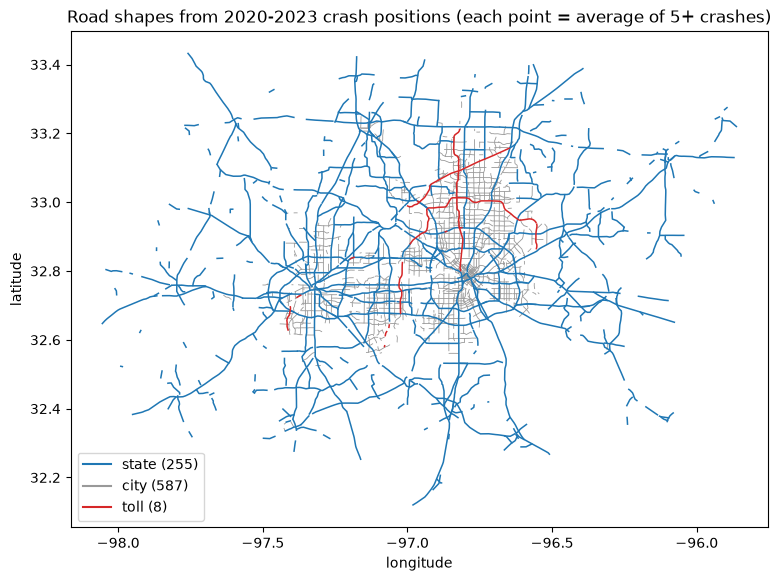

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 8))
colours = {"state": "#1f77b4", "city": "#999999", "toll": "#d62728"}
for lyr in ["city", "state", "toll"]:
    for unit in app_roads.loc[app_roads.layer == lyr, "unit"]:
        for ln in shapes[unit]:
            xs, ys = zip(*ln)
            ax.plot(xs, ys, color=colours[lyr], lw=0.6 if lyr == "city" else 1.1)
for lyr, c in colours.items():
    ax.plot([], [], color=c, label=f"{lyr} ({(app_roads.layer == lyr).sum()})")
ax.set_aspect(1 / np.cos(np.deg2rad(32.8)))
ax.set_title("Road shapes from 2020-2023 crash positions (each point = average of 5+ crashes)")
ax.legend(loc="lower left")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
plt.savefig(os.path.join("..", "docs", "road_shapes.png"), dpi=110, bbox_inches="tight")
plt.show()

## Step 7. Files for the app: the scores format, a made-up sample, demo routes

The app reads scores in one fixed format (`docs/app-data-contract.md`). The same writer makes the made-up
sample now and the real 2023 and 2024 files later. "What really happened" is written only as a coarse level
(`actual_level`, 0 to 4: below normal ... far higher than normal) and only for the 5 roads averaging 8+ crashes a day: a daily number,
or any road with few crashes, would let someone work out how many crashes happened, and TxDOT's terms rule that out.

In [8]:
APP_IDS = app_roads["id"].tolist()
APP_UNITS = app_roads["unit"].tolist()
BUSY_IDS = set(app_roads.loc[app_roads["busy"], "id"])
# "What really happened" is published only as a coarse level, and only for roads averaging 8+ crashes a day, so a
# level always spans several possible crash counts and no daily count can be read back out (TxDOT's terms).
HEADLINE_IDS = set(app_roads.loc[app_roads["per_day"] >= 8, "id"])
LEVEL_EDGES = [0.85, 1.15, 1.4, 1.8]
LEVEL_NAMES = ["below normal", "about normal", "higher than normal", "much higher than normal", "far higher than normal"]
print(f"Roads that get a 'what really happened' level: {len(HEADLINE_IDS)}")


def day_reasons(row):
    """Up to 3 short phrases for 'why it's flagged', most important first."""
    out = []
    if row["ice"]:
        out.append("Ice on the roads")
    if row["rained"] and row["dry_days_before_rain"] >= 7:
        out.append(f"First rain after {int(row['dry_days_before_rain'])} dry days")
    if row["rained"] and row["hot_days_before_rain"] >= 3:
        out.append(f"Rain after {int(row['hot_days_before_rain'])} hot days")
    if row["rain_mm"] >= 12.7:
        out.append(f"Heavy rain ({row['rain_mm']:.0f} mm)")
    elif row["rained"]:
        out.append(f"Rain ({row['rain_mm']:.1f} mm)")
    if row["thunder"]:
        out.append("Thunderstorms")
    if row["heavy_fog"]:
        out.append("Heavy fog")
    elif row["fog"]:
        out.append("Fog")
    if row["holiday"]:
        out.append("Holiday")
    return out[:3]


ALERT_TOP_SHARE = 0.15   # the alert rule: also among the worst 15% of roads that day (step 12 shows why)
ALERT_WEATHER_ONLY = True  # and only on days with rain or ice (chosen on 2023, before 2024; step 12)


def weather_day(w):
    """Rain (0.3 mm or more) or ice that day: the only days the app alerts on."""
    return bool(w["rained"] or w["ice"])


def pick_alerts(pr, threshold, top_share):
    """Indexes of roads to alert: at or above the line, and among the worst top_share of roads that day.
    Ties broken by position, so the app can reproduce it exactly."""
    k = int(top_share * len(pr))
    above = sorted((i for i, x in enumerate(pr) if x >= threshold), key=lambda i: (-pr[i], i))
    return sorted(above[:k])


APP_POS = {u: i for i, u in enumerate(APP_UNITS)}


def shipped_mask(frame, col, threshold, top_share, weather_only=False):
    """Exactly the app's rule, as a mask over frame rows: pick_alerts on 2-decimal predictions in app order (ties by
    position), day by day. top_share=1.0 is the plain line with no cap. weather_only skips days with no rain
    and no ice."""
    alerted = set()
    for day, g in frame[frame["unit"].isin(APP_POS)].groupby("date"):
        if weather_only and not weather_day(wx.loc[day]):
            continue
        pr = [0.0] * len(APP_UNITS)
        for u, v in zip(g["unit"], g[col]):
            pr[APP_POS[u]] = round(float(v), 2)
        alerted.update((day, APP_UNITS[i]) for i in pick_alerts(pr, round(float(threshold), 2), top_share))
    return np.array([(d, u) in alerted for d, u in zip(frame["date"], frame["unit"])])


def write_scores_file(path, year, model, preds, actual, threshold, made_up, top_share):
    """preds: DataFrame (index = dates, columns = app road ids). actual: real scores (same shape) or None; only
    HEADLINE_IDS are written, as a level 0-4, never as a number."""
    assert list(preds.columns) == APP_IDS
    threshold = round(float(threshold), 2)     # the app sees the rounded value, so alerts use it too
    days = []
    for day, p in preds.iterrows():
        w = wx.loc[day]
        pr = [round(float(x), 2) for x in p.to_numpy()]
        act = {} if actual is None else {k: int(np.searchsorted(LEVEL_EDGES, float(v), side="right"))
                                         for k, v in actual.loc[day].items() if k in HEADLINE_IDS and pd.notna(v)}
        days.append({"date": day.strftime("%Y-%m-%d"),
                     "weather": {"rain_mm": round(float(w["rain_mm"]), 1), "days_since_rain": int(w["days_since_rain"]),
                                 "high_f": int(round(w["high_c"] * 9 / 5 + 32)), "low_f": int(round(w["low_c"] * 9 / 5 + 32)),
                                 "thunder": bool(w["thunder"]), "fog": bool(w["fog"]),
                                 "ice": bool(w["ice"]), "freezing": bool(w["freezing"])},
                     "reasons": day_reasons(w), "rare": bool(w["ice"] or w["freezing"]),
                     "pred": pr, "alert": pick_alerts(pr, threshold, top_share) if weather_day(w) or not ALERT_WEATHER_ONLY else [],
                     "actual_level": act})
    with open(path, "w") as f:
        json.dump({"version": 1, "year": year, "model": model, "made_up": made_up,
                   "alert_threshold": threshold, "alert_top_share": top_share, "alert_weather_only": ALERT_WEATHER_ONLY,
                   "actual_level_names": LEVEL_NAMES,
                   "road_ids": APP_IDS, "days": days},
                  f, separators=(",", ":"))
    return days


# Made-up sample: the 14 days of 2023 with the most rain days, real weather, invented scores.
w23 = wx[wx.index.year == 2023]
start = w23["rained"].rolling(14).sum().idxmax() - pd.Timedelta(days=13)
sample_days = pd.date_range(start, periods=14, freq="D")
noise = rng.normal(0, 0.08, size=(14, len(APP_IDS)))
road_tilt = rng.normal(0, 0.1, size=len(APP_IDS))
fake = 1 + 0.4 * wx.loc[sample_days, "rained"].to_numpy()[:, None] * (1 + road_tilt) + noise
sample_preds = pd.DataFrame(np.clip(fake, 0.5, None), index=sample_days, columns=APP_IDS)
SAMPLE_THRESHOLD = float(np.quantile(sample_preds.to_numpy(), 0.9))   # top 10%, like the real files
sample = write_scores_file(os.path.join(DATA_DIR, "sample.json"), 2023, "made-up", sample_preds, None,
                           SAMPLE_THRESHOLD, made_up=True, top_share=ALERT_TOP_SHARE)
print(f"Wrote data/sample.json: {sample_days[0].date()} to {sample_days[-1].date()}, "
      f"{sum(len(d['alert']) for d in sample)} made-up alerts")

Roads that get a 'what really happened' level: 5
Wrote data/sample.json: 2023-02-24 to 2023-03-09, 1016 made-up alerts


### Demo drive routes

Five drives along real road shapes for the app's simulated drive, one point every 5 seconds at 65 mph.
The builder is defined here; step 12 writes the routes on real 2023 days (four on a rain day, passing roads the
model really flagged; route 5 on a dry day with nothing flagged).

In [9]:
STEP_M = 65 * 1609.344 / 3600 * 5   # metres in 5 seconds at 65 mph (about 145 m)


def resample(line, step_m):
    """Points every step_m metres along a [lon, lat] polyline."""
    pts = np.asarray(line, float)
    seg = km(pts[1:], pts[:-1]) * 1000
    dist = np.concatenate([[0], np.cumsum(seg)])
    at = np.arange(0, dist[-1], step_m)
    return np.column_stack([np.interp(at, dist, pts[:, 0]), np.interp(at, dist, pts[:, 1])])


def gpx_track(name, desc, pts, start_utc):
    times = [start_utc + pd.Timedelta(seconds=5 * i) for i in range(len(pts))]
    body = "".join(f'<trkpt lat="{lat:.5f}" lon="{lon:.5f}"><time>{t.strftime("%Y-%m-%dT%H:%M:%SZ")}</time></trkpt>'
                   for (lon, lat), t in zip(pts, times))
    return f"<trk><name>{name}</name><desc>{desc}</desc><trkseg>{body}</trkseg></trk>"


def flagged_near(pts, day, days_list, radius_km=0.8):
    """Display names of roads flagged on `day` (in a scores file's day list) that the drive passes within radius_km."""
    d = next(x for x in days_list if x["date"] == day.strftime("%Y-%m-%d"))
    names = []
    for i in d["alert"]:
        unit = APP_UNITS[i]
        road_pts = np.array([p for ln in shapes[unit] for p in ln])
        if km(road_pts[:, None, :], pts[None, :, :]).min() <= radius_km:
            names.append(app_roads.loc[app_roads["unit"] == unit, "display_name"].iloc[0])
    return sorted(set(names))


longest = lambda unit: max(shapes[unit], key=lambda ln: km(np.asarray(ln[1:]), np.asarray(ln[:-1])).sum())


def write_routes(days_list, rain_day, dry_day, label):
    """Four drives on rain_day along busy state and toll roads that pass flagged roads, and one on dry_day.
    Returns each drive's (road name, points), so a later year can check which drives pass its flagged roads."""
    picks = [u for u in app_roads.sort_values("per_day", ascending=False)["unit"] if layer_of[u] in ("state", "toll")]
    tracks, used, drives = [], set(), []
    for unit in picks:
        if len(tracks) == 4:
            break
        name = app_roads.loc[app_roads.unit == unit, "display_name"].iloc[0]
        line = longest(unit)
        if name in used or km(np.asarray(line[1:]), np.asarray(line[:-1])).sum() < 8:
            continue
        pts = resample(line, STEP_M)[:240]     # at most 20 minutes of driving
        near = flagged_near(pts, rain_day, days_list)
        if not near:
            continue
        used.add(name)
        drives.append((name, pts))
        shown = ", ".join(near[:6]) + (f" and {len(near) - 6} more" if len(near) > 6 else "")
        tracks.append(gpx_track(f"route-{len(tracks) + 1}", f"{rain_day.date()} ({label}); drives {name}; "
                                f"passes flagged: {shown}", pts, rain_day + pd.Timedelta(hours=13)))
    quiet_unit = next(u for u in picks if app_roads.loc[app_roads.unit == u, "display_name"].iloc[0] not in used)
    qpts = resample(longest(quiet_unit), STEP_M)[:240]
    assert not flagged_near(qpts, dry_day, days_list), "the quiet route must pass no flagged road"
    qname = app_roads.loc[app_roads.unit == quiet_unit, "display_name"].iloc[0]
    tracks.append(gpx_track("route-5", f"{dry_day.date()} ({label}, dry, nothing flagged); drives {qname}",
                            qpts, dry_day + pd.Timedelta(hours=13)))
    assert len(tracks) == 5
    gpx = ('<?xml version="1.0" encoding="UTF-8"?>\n<gpx version="1.1" creator="Same Rain, Different Road" '
           'xmlns="http://www.topografix.com/GPX/1/1">' + "".join(tracks) + "</gpx>\n")
    with open(os.path.join(DATA_DIR, "routes.gpx"), "w") as fh:
        fh.write(gpx)
    for t in tracks:
        print(re.search(r"<name>(.*?)</name><desc>(.*?)</desc>", t).groups())
    return drives + [(qname, qpts)]

### Hand checks, done a second way

Each check recomputes something from the raw files **without** the code above, then compares:
1. crashes on 3 busy roads on 3 days, recounted line by line from the raw crash file with Python's `csv` module (only
   whether the counts match is printed, never a road's count for a day);
2. rain and high temperature on 3 days, read straight from NOAA's raw rows;
3. "days since rain" for one day, counted backwards one day at a time;
4. every busy state road's name against TxDOT's own road code on its crashes (`street_name`, like `IH0030`).

In [10]:
import csv
import gzip

check_days = ["2021-03-17", "2022-08-05", "2023-11-24"]
check_units = roads.loc[roads["busy"] & (roads["layer"] == "state"), "unit"].head(3).tolist()
raw_counts = {(u, d): 0 for u in check_units for d in check_days}
with gzip.open(CRASH_FILE, "rt", newline="") as fh:
    for row in csv.DictReader(fh):
        if row["crash_date"] not in check_days or row["onsys_fl"] not in ("1", "1.0") or row["road_cls_id"] in ("6", "6.0"):
            continue
        num = row["hwy_nbr"].split(".")[0].lstrip("0")
        road = f"{row['hwy_sys'].strip()} {num}{row['hwy_sfx'].strip()}".strip()
        try:
            surf = SURFACE_GROUP.get(int(float(row["surf_type_id"])))
        except ValueError:
            continue
        key = (f"{road} | {surf}", row["crash_date"])
        if key in raw_counts:
            raw_counts[key] += 1
table = road_daily.set_index(["unit", "date"])["crashes"]
hand = []
for (u, d), n in raw_counts.items():
    t = int(table[(u, pd.Timestamp(d))])
    hand.append(("crash count", f"{u} on {d}", "match" if n == t else "MISMATCH", "(count not shown: TxDOT terms)"))
    assert n == t, (u, d, n, t)

with urllib.request.urlopen(NOAA_URL) as resp:
    raw_rows = {r["DATE"]: r for r in csv.DictReader(resp.read().decode().splitlines()) if r["DATE"] in check_days}
for d in check_days:
    rain, high = float(raw_rows[d]["PRCP"]) / 10, float(raw_rows[d]["TMAX"]) / 10
    hand.append(("weather", f"{d} rain mm / high C", f"{rain} / {high}",
                 f"{wx.loc[d, 'rain_mm']} / {wx.loc[d, 'high_c']}"))
    assert rain == wx.loc[d, "rain_mm"] and high == wx.loc[d, "high_c"]

target = pd.Timestamp("2023-11-24")
back = 1
while not (w.loc[target - pd.Timedelta(days=back), "PRCP"] >= 3):
    back += 1
hand.append(("days since rain", str(target.date()), back, int(wx.loc[target, "days_since_rain"])))
assert back == wx.loc[target, "days_since_rain"]

code = lambda road: road.split(" ")[0] + road.split(" ")[1][:-1].zfill(4) + road.split(" ")[1][-1] \
    if road.split(" ")[1][-1].isalpha() else road.split(" ")[0] + road.split(" ")[1].zfill(4)
for r in roads[roads["busy"] & (roads["layer"] == "state")].itertuples():
    names = crashes.loc[(crashes["unit"] == r.unit) & (crashes["year"] <= 2023), "street_name"].astype(str).str.replace(" ", "")
    share = names.str.startswith(code(r.road_name)).mean()
    hand.append(("road name", r.display_name + " | " + r.surface, f"{share:.0%} of crashes coded {code(r.road_name)}", "≥ 90%"))
    assert share >= 0.9, (r.road_name, code(r.road_name), share)
hand_checks = pd.DataFrame(hand, columns=["check", "what", "second way", "notebook"])
print(hand_checks.to_string(index=False))

          check                                         what                    second way                       notebook
    crash count IH 35E | asphalt_over_concrete on 2021-03-17                         match (count not shown: TxDOT terms)
    crash count IH 35E | asphalt_over_concrete on 2022-08-05                         match (count not shown: TxDOT terms)
    crash count IH 35E | asphalt_over_concrete on 2023-11-24                         match (count not shown: TxDOT terms)
    crash count               US 75 | concrete on 2021-03-17                         match (count not shown: TxDOT terms)
    crash count               US 75 | concrete on 2022-08-05                         match (count not shown: TxDOT terms)
    crash count               US 75 | concrete on 2023-11-24                         match (count not shown: TxDOT terms)
    crash count               IH 30 | concrete on 2021-03-17                         match (count not shown: TxDOT terms)
    crash count         

## Step 8. The model table, the simple guesses and how we score

**Inputs.** Every same-day weather column, plus the weather-history columns (built from the days before today; two of
them are filled in only on rain days), plus
how the road is built. Never the officer's weather or wet-road fields. Long dry spells are capped at 30 days
so one 60-day drought doesn't dominate a linear model.

**The three simple guesses (baselines):** tomorrow's score equals today's (the Climate track's required
"persistence"), same weekday last week, and always 1.0. Whichever misses least on 2023 is **the bar**.

**How we score:**
* **Miss** = average gap between predicted and real score. 0.10 means off by 10% of a normal day.
* **Chance floor** = the miss a perfect model would still have, because crashes are random. We simulate it:
  draw crash counts from a Poisson distribution (the usual model for counts of random, independent events) around
  the predicted level, and measure the miss.
* **Real, not luck** = build 1,000 made-up versions of 2023 by picking its weeks at random, with repeats. Whole
  weeks, not single days, because one storm or holiday spans several days. A gain counts only if it holds in 950
  or more (95%).

**Three places we score:** the 4 surface groups (Models A to C), the 38 busy roads one by one, and the quiet
roads summed into one row per layer per day (a quiet road alone is too random to score day by day).

In [11]:
FEATURES_TODAY = ["rain_mm", "rained", "snow_mm", "snow_depth_mm", "high_c", "low_c", "hot", "freezing",
                  "dew_point_c", "wet_bulb_c", "humidity_avg", "humidity_min", "humidity_max",
                  "pressure_sea_hpa", "pressure_station_hpa", "wind_avg_ms", "gust_2min_ms", "gust_5sec_ms",
                  "dir_2min_sin", "dir_2min_cos", "dir_5sec_sin", "dir_5sec_cos",
                  "fog", "heavy_fog", "thunder", "haze", "sleet", "hail", "glaze", "ice", "holiday"]
FEATURES_HISTORY = ["days_since_rain", "rain_last_7_mm", "hot_days_last_7", "dry_days_before_rain",
                    "hot_days_before_rain", "ice_last_3"]
assert set(FEATURES_TODAY + FEATURES_HISTORY) == set(wx.columns), set(wx.columns) ^ set(FEATURES_TODAY + FEATURES_HISTORY)
assert not any(c in FEATURES_TODAY + FEATURES_HISTORY for c in ["wthr_cond_id", "surf_cond_id"])

wx_model = wx.copy()
wx_model["days_since_rain"] = wx_model["days_since_rain"].clip(upper=30)
wx_model["dry_days_before_rain"] = wx_model["dry_days_before_rain"].clip(upper=30)


def with_baselines(d):
    """Add the three simple guesses, per unit, from the unit's own past scores."""
    d = d.sort_values(["unit", "date"]).copy()
    g = d.groupby("unit")["score"]
    d["persistence"] = g.shift(1)
    d["same_weekday_last_week"] = g.shift(7)
    d["always_one"] = 1.0
    return d


surf = with_baselines(surface_scored).merge(wx_model, left_on="date", right_index=True)
surf = surf[surf["date"].dt.year >= 2021].reset_index(drop=True)
road = with_baselines(road_scored).merge(wx_model, left_on="date", right_index=True)
road = road[road["date"].dt.year >= 2021].reset_index(drop=True)
assert surf[FEATURES_TODAY + FEATURES_HISTORY].notna().all().all()
assert road[FEATURES_TODAY + FEATURES_HISTORY].notna().all().all()
assert len(surf) == 4 * 1_095 and len(road) == len(roads) * 1_095

# The history column days_since_rain is recomputed from yesterday's row on 3 random dates: it must follow from the past.
for day in pd.to_datetime(rng.choice(wx.index[wx.index.year >= 2021], 3, replace=False)):
    prev = wx.loc[day - pd.Timedelta(days=1)]
    expect = 1 if prev["rained"] else prev["days_since_rain"] + 1
    assert wx.loc[day, "days_since_rain"] == expect, day

is_train = lambda d: d["date"].dt.year.between(2021, 2022)
is_test = lambda d: d["date"].dt.year == 2023


def miss(pred, actual, weight=None):
    err = np.abs(np.asarray(pred, float) - np.asarray(actual, float))
    return float(np.average(err, weights=weight))


def chance_floor(pred, normal, n_sims=200, seed=SEED):
    """The miss a perfect model would still have: crash counts are Poisson around normal x pred.
    Each call uses its own fixed seed, so the answer doesn't depend on what ran before it."""
    pred, normal = np.asarray(pred, float), np.asarray(normal, float)
    sims = np.random.default_rng(seed).poisson(np.outer(np.ones(n_sims), normal * pred)) / normal
    return float(np.abs(sims - pred).mean())


def week_redraw(a_err, b_err, dates, n=1000, seed=SEED):
    """Share of 1,000 redraws of whole weeks in which b's average error is below a's.
    Each call uses its own fixed seed, so a test's result depends only on its own data."""
    wk = pd.DatetimeIndex(dates).to_period("W").astype(str)
    sums = pd.DataFrame({"a": a_err, "b": b_err, "wk": wk}).groupby("wk").agg(a=("a", "sum"), b=("b", "sum"), n=("a", "size"))
    idx = np.random.default_rng(seed).integers(0, len(sums), size=(n, len(sums)))
    a, b, c = sums["a"].to_numpy()[idx].sum(1), sums["b"].to_numpy()[idx].sum(1), sums["n"].to_numpy()[idx].sum(1)
    return float(((b / c) < (a / c)).mean())


_err = rng.random(500)
_days = pd.date_range("2023-01-01", periods=500)
assert week_redraw(_err, _err, _days) == 0.0              # a tie never counts as a win
assert week_redraw(_err, _err - 0.1, _days) == 1.0        # always better wins every redraw
assert week_redraw(_err, _err + 0.1, _days) == 0.0        # always worse never wins


def quiet_groups(d, pred_col):
    """One row per layer per day for quiet roads: summed crashes over summed normal, and the matching prediction."""
    q = d[~d["unit"].isin(busy_units)].copy()
    q["layer"] = q["unit"].map(layer_of)
    q["_pn"] = q[pred_col] * q["normal"]
    g = q.groupby(["layer", "date"]).agg(crashes=("crashes", "sum"), normal=("normal", "sum"), pn=("_pn", "sum"),
                                         rained=("rained", "first")).reset_index()
    g["score"] = g["crashes"] / g["normal"]
    g["pred"] = g["pn"] / g["normal"]
    return g


BASELINES = ["persistence", "same_weekday_last_week", "always_one"]
busy = road[road["unit"].isin(busy_units)]
bar_rows = []
for where, d in [("surface groups", surf[is_test(surf)]), ("busy roads", busy[is_test(busy)])]:
    for b in BASELINES:
        bar_rows.append({"where": where, "guess": b, "miss": miss(d[b], d["score"]),
                         "chance floor": chance_floor(d[b].clip(lower=0.05), d["normal"])})
for b in BASELINES:
    road[b] = road[b].fillna(1.0)
    g = quiet_groups(road[is_test(road)], b)
    for lyr, gg in g.groupby("layer"):
        bar_rows.append({"where": f"quiet {lyr} roads (summed)", "guess": b, "miss": miss(gg["pred"], gg["score"]),
                         "chance floor": chance_floor(gg["pred"].clip(lower=0.05), gg["normal"])})
bar_table = pd.DataFrame(bar_rows)
print("Test 1. The bar: each simple guess on 2023")
print(bar_table.pivot(index="where", columns="guess", values="miss").round(3).to_string())
print("\nChance floor for always 1.0 (what pure randomness alone costs):")
print(bar_table[bar_table.guess == "always_one"].set_index("where")["chance floor"].round(3).to_string())
BAR = bar_table.loc[bar_table.groupby("where")["miss"].idxmin()].set_index("where")["guess"].to_dict()
assert len(set(BAR.values())) == 1, f"the bar differs by place, so the tests below need one bar per place: {BAR}"
BAR_COL = next(iter(BAR.values()))       # every test below compares against this simple guess
print("\nThe bar in each place:", BAR)
RESULTS = [{"test": "1. The bar", "question": "How good is a simple guess?", "pass_line": "none; best baseline becomes the bar",
            "value": "; ".join(f"{k}: {v}" for k, v in BAR.items()), "passed": None, "year": 2023}]

Test 1. The bar: each simple guess on 2023
guess                       always_one  persistence  same_weekday_last_week
where                                                                      
busy roads                       0.579        0.787                   0.776
quiet city roads (summed)        0.142        0.189                   0.200
quiet state roads (summed)       0.175        0.234                   0.230
quiet toll roads (summed)        1.182        1.425                   1.360
surface groups                   0.237        0.329                   0.328

Chance floor for always 1.0 (what pure randomness alone costs):
where
surface groups                0.175
busy roads                    0.529
quiet city roads (summed)     0.089
quiet state roads (summed)    0.105
quiet toll roads (summed)     1.112

The bar in each place: {'busy roads': 'always_one', 'quiet city roads (summed)': 'always_one', 'quiet state roads (summed)': 'always_one', 'quiet toll roads (summed)': 'alwa

## Step 9. Models A, B and C on the four surface groups

Each model adds one thing, and has to earn it:
* **A:** today's weather (plus the holiday flag). One model for all four surfaces.
* **B:** A plus the weather history (days since rain, dry spell before today's rain, heat streak, ...).
* **C:** B, with a separate model per surface, so rain can hit concrete and asphalt differently.

All three are **ridge regression**: linear regression with a penalty that keeps weights small, so 31 (A) or 37 (B, C) weather
columns don't let the model chase noise. The penalty strength is picked on 2023. Picking on 2023 and then
reporting 2023 flatters the result a little; that is exactly why 2024 exists.

Pass lines (set before any results): A beats the bar on all days; B beats A on rain days; C beats B on
rain days. Each "real" in 950 of 1,000 week redraws.

*Added Nov 15, before 2024 was opened (information only, not a pass line):* the simplest weather guess. Each
surface group gets its training-years average score on rain days or on dry days. It is scored against the bar and
against Model A, to show what Model A's 31 same-day weather columns add over a one-line rain rule.

In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ALPHAS = [0.1, 1, 10, 100, 1000, 10000]


def fit_ridge(train_df, features, alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(train_df[features], train_df["score"])


def pick_alpha(train_df, test_df, features):
    tried = {a: miss(fit_ridge(train_df, features, a).predict(test_df[features]), test_df["score"]) for a in ALPHAS}
    return min(tried, key=tried.get), tried


tr, te = surf[is_train(surf)], surf[is_test(surf)].copy()
FEAT_A, FEAT_B = FEATURES_TODAY, FEATURES_TODAY + FEATURES_HISTORY
alpha_a, tried_a = pick_alpha(tr, te, FEAT_A)
alpha_b, tried_b = pick_alpha(tr, te, FEAT_B)
model_a, model_b = fit_ridge(tr, FEAT_A, alpha_a), fit_ridge(tr, FEAT_B, alpha_b)
te["A"], te["B"] = model_a.predict(te[FEAT_A]), model_b.predict(te[FEAT_B])
models_c, alpha_c = {}, {}
for s, g in tr.groupby("unit"):
    alpha_c[s], _ = pick_alpha(g, te[te["unit"] == s], FEAT_B)
    models_c[s] = fit_ridge(g, FEAT_B, alpha_c[s])
te["C"] = np.nan
for s, m in models_c.items():
    te.loc[te["unit"] == s, "C"] = m.predict(te.loc[te["unit"] == s, FEAT_B])
print("Penalty picked on 2023 (2023 miss for each):")
print(pd.DataFrame({"A": tried_a, "B": tried_b}).round(4).to_string())
print("C, per surface:", alpha_c)


def compare(test, question, pass_line, base, new, rows, base_name, new_name, informational=False):
    """Miss, gain, week-redraw share and chance floor of `new` against `base` on `rows`.
    informational=True: shown for context only, with no pass/fail."""
    d = te[rows] if isinstance(rows, pd.Series) else rows
    e_base, e_new = np.abs(d[base] - d["score"]), np.abs(d[new] - d["score"])
    share = week_redraw(e_base.to_numpy(), e_new.to_numpy(), d["date"])
    m_base, m_new = e_base.mean(), e_new.mean()
    out = {"test": test, "question": question, "pass_line": pass_line, "year": 2023,
           "base": f"{base_name} {m_base:.3f}", "new": f"{new_name} {m_new:.3f}",
           "gain_%": round(100 * (m_base - m_new) / m_base, 1), "redraw_share": round(share, 3),
           "chance_floor": round(chance_floor(d[new].clip(lower=0.05), d["normal"]), 3),
           "passed": bool(share >= 0.95 and m_new < m_base), "days": d["date"].nunique()}
    out["value"] = f"{out['base']} -> {out['new']} ({out['gain_%']:+}%), real in {share * 1000:.0f}/1000"
    if informational:
        out["passed"], out["pass_line"] = None, "for information (not a pass line)"
    RESULTS.append(out)
    return out


rain = te["rained"] == 1
shown = [compare("2. Model A", "Does today's weather beat the bar?", "real gain on all days",
                 BAR_COL, "A", te["rained"] >= 0, "bar", "A"),
         compare("3. Model B", "Does weather history help?", "real gain over A on rain days",
                 "A", "B", rain, "A", "B"),
         compare("4. Model C", "Does surface help?", "real gain over B on rain days",
                 "B", "C", rain, "B", "C")]
cols = ["test", "base", "new", "gain_%", "redraw_share", "chance_floor", "days", "passed"]
print("\n" + pd.DataFrame(shown)[cols].to_string(index=False))

# For information (added Nov 15, before 2024 was opened): the simplest weather guess. Each surface group gets its
# average training-years score on rain days or on dry days, whichever matches the day. Does a one-line rain rule beat
# "every day is normal", and do Model A's 31 same-day weather columns beat the one-line rule?
rain_avg = tr.groupby(["unit", "rained"])["score"].mean()
te["rain_only"] = [rain_avg[(u, r)] for u, r in zip(te["unit"], te["rained"])]
extra9 = [compare("2. Rain-only guess (extra)", "Does a one-line rain rule beat every day is normal?", "", BAR_COL,
                  "rain_only", te["rained"] >= 0, "bar", "rain-only", informational=True),
          compare("2. Model A vs the rain-only guess (extra)", "Do Model A's 31 same-day weather columns beat the one-line rain rule?", "",
                  "rain_only", "A", te["rained"] >= 0, "rain-only", "A", informational=True)]
print("\nFor information (not pass lines):\n" + pd.DataFrame(extra9)[cols].to_string(index=False))

# What B learned, in plain words: the change in score for one unit of each input (biggest first).
ridge, scaler = model_b[-1], model_b[0]
per_unit = pd.Series(ridge.coef_ / scaler.scale_, index=FEAT_B)
size = pd.Series(np.abs(ridge.coef_), index=FEAT_B).sort_values(ascending=False)
print("\nModel B's 10 strongest inputs (effect on the score of one more unit, e.g. +0.010 = 1% more crashes):")
for f in size.index[:10]:
    print(f"  {f:22s} {per_unit[f]:+.4f} per unit")

Penalty picked on 2023 (2023 miss for each):
              A       B
0.1      0.2282  0.2292
1.0      0.2283  0.2293
10.0     0.2287  0.2297
100.0    0.2290  0.2300
1000.0   0.2288  0.2289
10000.0  0.2318  0.2314
C, per surface: {'asphalt': 1000, 'asphalt_over_concrete': 0.1, 'concrete': 1000, 'surface_treated': 10000}

      test      base     new  gain_%  redraw_share  chance_floor  days  passed
2. Model A bar 0.237 A 0.228     3.8         0.997         0.176   365    True
3. Model B   A 0.311 B 0.307     1.6         0.880         0.187    71   False
4. Model C   B 0.307 C 0.307    -0.0         0.517         0.184    71   False

For information (not pass lines):
                                     test            base             new  gain_%  redraw_share  chance_floor  days passed
               2. Rain-only guess (extra)       bar 0.237 rain-only 0.230     3.0         0.998         0.176   365   None
2. Model A vs the rain-only guess (extra) rain-only 0.230         A 0.228     0.9

## Step 10. Model D: every road, one by one

Model D scores all 855 roads. It sees Model B's weather inputs plus how each road is built: layer, surface,
road class, speed limit, lanes, daily traffic, and the road's own crash level in the training years. Toll
roads and city streets are marked unknown for surface, lanes and traffic: TxDOT's data never has them for city streets
and has them for only about 3% of toll-road crashes.

**Two kinds of model compete for the job. Boosting is the default, and the forest replaces it only if it beats
boosting in 950 of 1,000 week redraws of 2023:**
* a **random forest**: 200 decision trees, each trained on a random slice of the data, averaged;
* **gradient boosting**: 300 small trees built one after another, each fixing the last one's mistakes.
  It is usually the strongest method for tables of numbers.

Both are trained so a quiet road can't swing the model with one random crash: each road-day counts in
proportion to its normal. For the forest, each tree ends in small groups of similar road-days ("leaves"), and
each leaf predicts its total crashes divided by its total normal, so a few quiet roads can't dominate it.
Gradient boosting scores its errors with a Poisson loss, the standard choice for counts, which does the same job.

Pass lines: **Test 5**, road build helps: D beats the same kind of model trained without the road-build inputs
(class, speed limit, lanes, traffic, the road's own level), on the 35 busy state stretches, all days (real). D also
beats the bar on at least 7 of the 10 busiest roads. **5b:** the rain-day ranking of the 35 matches reality
(rank match above zero, meaning better than a random order, in 950 of 1,000 redraws). **5c:** on quiet roads, summed per layer, D beats the bar (real).

*Changed after the cold audit, before 2024:* Test 5 first compared D with Model C on rain days, but C predicted a
different target (the surface group's score) and is a different kind of model, so the gap mixed up three things.
The clean question is "same model, with and without road build", on all days as our plan (CLAUDE.md) states. The old C
comparison is kept as information in a fairer form (Model C refit on D's road-by-road target, all days and rain days).
See `docs/audit-2023.md`.

*Added Nov 15, before 2024 was opened (information only, not pass lines):* Model D against the bar road by road on
the 38 busy roads, with redraws. Also the 5b ranking next to two simpler rankings: the same model without road
build, and each road's own training-years rain-day score (no model at all). Both are scored on the same week redraws.

In [13]:
import time
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

info = roads.set_index("unit")


def add_road_features(frame):
    """How each road is built, plus train_rate: the road's own crashes a day over the frame's training years."""
    f = frame.copy()
    f["layer"] = f["unit"].map(layer_of)
    for lyr in ["state", "toll", "city"]:
        f[f"is_{lyr}"] = (f["layer"] == lyr).astype(int)
    for srf in ["concrete", "asphalt_over_concrete", "asphalt", "surface_treated"]:
        f[f"surf_{srf}"] = (f["unit"].map(info["surface"]) == srf).astype(int)
    for c in ["interstate", "us_state_highway", "farm_to_market", "county_road", "city_street", "tollway"]:
        f[f"class_{c}"] = (f["unit"].map(info["road_class"]) == c).astype(int)
    for col in ["speed_limit", "lanes", "daily_traffic"]:
        v = f["unit"].map(info[col])
        f[f"{col}_unknown"] = v.isna().astype(int)
        f[col] = v.fillna(-1)
    f["train_rate"] = f["train_mean"]          # set by add_score from the training years only
    return f


road = add_road_features(road)
ROAD_FEATURES = ([f"is_{l}" for l in ["state", "toll", "city"]]
                 + [c for c in road.columns if c.startswith("surf_") or c.startswith("class_")]
                 + ["speed_limit", "lanes", "daily_traffic", "speed_limit_unknown", "lanes_unknown",
                    "daily_traffic_unknown", "train_rate"])
FEAT_D = FEAT_B + ROAD_FEATURES
rtr, rte = road[is_train(road)], road[is_test(road)].copy()
assert rtr["date"].dt.year.max() == 2022 and rte["date"].dt.year.unique().tolist() == [2023]


def fit_forest(train_df, features):
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=200, max_features=0.5, max_samples=0.3,
                              n_jobs=-1, random_state=SEED)
    return m.fit(train_df[features], train_df["score"], sample_weight=train_df["normal"])


def fit_boost(train_df, features):
    m = HistGradientBoostingRegressor(loss="poisson", max_iter=300, learning_rate=0.05, min_samples_leaf=200,
                                      l2_regularization=1.0, early_stopping=False, random_state=SEED)
    return m.fit(train_df[features], train_df["score"], sample_weight=train_df["normal"])


timings, candidates = {}, {}
for name, fit in [("forest", fit_forest), ("boosting", fit_boost)]:
    t0 = time.time()
    candidates[name] = fit(rtr, FEAT_D)
    timings[name] = time.time() - t0
    rte[f"D_{name}"] = candidates[name].predict(rte[FEAT_D])
print("Training time (s):", {k: round(v) for k, v in timings.items()})
assert max(timings.values()) < 240

# Pick the winner on 2023: miss on busy roads, plus miss on quiet roads summed per layer per day.
pick = {}
for name in candidates:
    b = rte[rte["unit"].isin(busy_units)]
    q = quiet_groups(rte, f"D_{name}")
    pick[name] = {"busy roads miss": miss(b[f"D_{name}"], b["score"]),
                  "quiet roads miss (summed)": miss(q["pred"], q["score"])}
pick = pd.DataFrame(pick).T
pick["total"] = pick.sum(axis=1)
print("\nForest against boosting on 2023 (lower is better):\n", pick.round(4).to_string())


def daily_total_error(col):
    """One error per day: mean miss on busy roads plus mean miss of the three quiet-road layer sums."""
    b = rte[rte["unit"].isin(busy_units)].assign(e=lambda x: (x[col] - x["score"]).abs()).groupby("date")["e"].mean()
    q = quiet_groups(rte, col).assign(e=lambda x: (x["pred"] - x["score"]).abs()).groupby("date")["e"].mean()
    return (b + q).sort_index()


# Gradient boosting is the default (Poisson loss suits counts; the stronger method for tables of numbers). The forest
# replaces it only if it is better for real: lower daily error in 950 of 1,000 week redraws. A near-tie stays boosting.
e_boost, e_forest = daily_total_error("D_boosting"), daily_total_error("D_forest")
forest_share = week_redraw(e_boost.to_numpy(), e_forest.to_numpy(), e_boost.index)
D_KIND = "forest" if forest_share >= 0.95 else "boosting"
print(f"Forest better than boosting in {forest_share * 1000:.0f}/1000 week redraws -> Model D = {D_KIND}")
model_d, rte["D"] = candidates[D_KIND], rte[f"D_{D_KIND}"]
FIT_D = {"forest": fit_forest, "boosting": fit_boost}[D_KIND]    # every later refit of D (and E) uses the same kind
print(f"Model D = {D_KIND}")

# Test 5, road build: the same kind of model as D, trained on the same rows and target, with the weather inputs,
# surface and layer, but WITHOUT road build (class, speed limit, lanes, traffic, the road's own level).
FEAT_NO_BUILD = FEAT_B + [c for c in ROAD_FEATURES if c.startswith(("surf_", "is_"))]
d_no_build = FIT_D(rtr, FEAT_NO_BUILD)
busy_state = roads.loc[roads["busy"] & (roads["layer"] == "state"), "unit"]
bs = rte[rte["unit"].isin(busy_state)].copy()
bs["surface"] = bs["unit"].map(info["surface"])
assert bs["unit"].nunique() == 35
bs["D_no_build"] = d_no_build.predict(bs[FEAT_NO_BUILD])
r5 = compare("5. Model D", "Does road build help, road by road?",
             "real gain over the same model without road build, 35 busy stretches, all days",
             "D_no_build", "D", bs, "D without road build", "D")

# For information: Model C (one ridge per surface) refit on the same target as D. It differs from D in model kind
# too, so it is not the clean test above. Its penalty is picked on 2023.
c_road, alpha_c_road = {}, {}
for srf in ["concrete", "asphalt_over_concrete", "asphalt", "surface_treated"]:
    g_tr = rtr[rtr["unit"].map(info["surface"]) == srf]
    g_te = bs[bs["surface"] == srf]
    if g_te.empty:
        g_te = rte[rte["unit"].map(info["surface"]) == srf]
    fit_c = lambda a: make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(g_tr[FEAT_B], g_tr["score"], ridge__sample_weight=g_tr["normal"])
    tried = {a: miss(fit_c(a).predict(g_te[FEAT_B]), g_te["score"]) for a in ALPHAS}
    alpha_c_road[srf] = min(tried, key=tried.get)
    c_road[srf] = fit_c(alpha_c_road[srf])
bs["C_road"] = np.nan
for srf, m in c_road.items():
    sel = bs["surface"] == srf
    if sel.any():
        bs.loc[sel, "C_road"] = m.predict(bs.loc[sel, FEAT_B])
assert bs["C_road"].notna().all()
compare("5. D vs ridge C (extra)", "D against Model C refit on the same target, all days", "", "C_road", "D", bs,
        "C", "D", informational=True)
compare("5. D vs ridge C, rain days (extra)", "Same, rain days only", "", "C_road", "D", bs[bs["rained"] == 1],
        "C", "D", informational=True)

top10 = roads.loc[roads["busy"]].sort_values("per_day", ascending=False).head(10)["unit"]
per_road = rte[rte["unit"].isin(top10)].groupby("unit").apply(
    lambda g: pd.Series({"bar": miss(g[BAR_COL], g["score"]), "D": miss(g["D"], g["score"])}), include_groups=False)
wins = int((per_road["D"] < per_road["bar"]).sum())
RESULTS.append({"test": "5. Model D (10 busiest)", "question": "Does D beat the bar road by road?",
                "pass_line": "D beats the bar on 7 of the 10 busiest roads", "year": 2023,
                "value": f"D beats the bar on {wins} of 10", "passed": wins >= 7})



def rank_redraws(rows, pred_col, rng, n=1000):
    """Rank match on n redraws of whole weeks. Gives the same draws as stacking the chosen weeks' rows and averaging
    them per road, but works from per-week sums, so 1,000 redraws take about a second instead of half a minute."""
    wk = rows["date"].dt.to_period("W").astype(str)
    weeks = wk.unique()
    t = rows.assign(_wk=wk.to_numpy(), _pn=(rows[pred_col] * rows["normal"]).to_numpy())
    g = t.groupby(["_wk", "unit"])[["_pn", "normal", "crashes"]].sum()
    units = sorted(t["unit"].unique())
    mat = lambda col: g[col].unstack("unit").reindex(index=weeks, columns=units).fillna(0.0).to_numpy(dtype=float)
    pn, nn, cc = mat("_pn"), mat("normal"), mat("crashes")
    pos = {w: i for i, w in enumerate(weeks)}
    draws = np.empty(n)
    for k in range(n):
        cnt = np.bincount([pos[w] for w in rng.choice(weeks, len(weeks), replace=True)], minlength=len(weeks)).astype(float)
        sn = cnt @ nn
        keep = sn > 0
        draws[k] = spearmanr((cnt @ pn)[keep] / sn[keep], (cnt @ cc)[keep] / sn[keep]).statistic
    return draws


# Self-check on made-up rows: the shortcut must give exactly the draws of the slow way (stack the chosen weeks' rows).
_t = pd.DataFrame({"date": np.repeat(pd.date_range("2023-01-02", periods=42), 6), "unit": np.tile(list("abcdef"), 42)})
_r = np.random.default_rng(1)
_t["normal"], _t["crashes"], _t["p"] = _r.uniform(0.5, 2, len(_t)), _r.poisson(1.2, len(_t)), _r.uniform(0.7, 1.5, len(_t))
_wk, _rr, _slow = _t["date"].dt.to_period("W").astype(str), np.random.default_rng(7), []
for _ in range(20):
    _g = pd.concat([_t[_wk == w] for w in _rr.choice(_wk.unique(), _wk.nunique(), replace=True)]).groupby("unit")
    _slow.append(spearmanr(_g.apply(lambda g: np.average(g["p"], weights=g["normal"]), include_groups=False),
                           _g["crashes"].sum() / _g["normal"].sum()).statistic)
assert np.allclose(rank_redraws(_t, "p", np.random.default_rng(7), n=20), _slow, equal_nan=True)

rd = bs[bs["rained"] == 1]
rho_draws = rank_redraws(rd, "D", np.random.default_rng(SEED))
full = rd.groupby("unit").apply(lambda g: pd.Series({"p": np.average(g["D"], weights=g["normal"]),
                                                     "a": g["crashes"].sum() / g["normal"].sum()}), include_groups=False)
rho = spearmanr(full["p"], full["a"]).statistic
share_pos = float((rho_draws > 0).mean())
RESULTS.append({"test": "5b. Ranking", "question": "Do the roads it calls worst in rain turn out worst?",
                "pass_line": "rank match above zero in 950 of 1,000", "year": 2023,
                "value": f"rank match {rho:+.2f}, above zero in {share_pos * 1000:.0f}/1000", "passed": share_pos >= 0.95})

# For information (added Nov 15, before 2024 was opened). Test 5b only compares the ranking with a random order, so
# here are two simpler rankings, scored on the same week redraws (same seed, same weeks): the same model without road
# build (Test 5's comparison model), and last years' rain days (each road's own training-years rain-day score, no
# model at all). "D higher" counts the redraws in which D's rank match beats the simpler ranking's.
hist_rain = rtr[rtr["unit"].isin(busy_state) & (rtr["rained"] == 1)].groupby("unit").apply(
    lambda g: g["crashes"].sum() / g["normal"].sum(), include_groups=False)
rd = rd.assign(hist_rain=rd["unit"].map(hist_rain))
assert rd["hist_rain"].notna().all()


def rank_full(rows, pred_col):
    """Rank match on all the rows: each road's normal-weighted average prediction against its real rain-day score."""
    agg = rows.groupby("unit").apply(lambda g: pd.Series({"p": np.average(g[pred_col], weights=g["normal"]),
                                                          "a": g["crashes"].sum() / g["normal"].sum()}), include_groups=False)
    return spearmanr(agg["p"], agg["a"]).statistic


for label, col in [("the same model without road build", "D_no_build"), ("last years' rain-day ranking", "hist_rain")]:
    other = rank_redraws(rd, col, np.random.default_rng(SEED))
    RESULTS.append({"test": f"5b. Ranking vs {label} (extra)", "question": f"Does D rank busy roads in rain better than {label}?",
                    "pass_line": "for information (not a pass line)", "year": 2023, "passed": None,
                    "value": f"{label}: rank match {rank_full(rd, col):+.2f}; D higher in {(rho_draws > other).mean() * 1000:.0f}/1000"})

# For information: D against the bar road by road on the 38 busy roads (Test 7 prints this gain without redraws).
compare("5. D vs the bar, busy roads (extra)", "How much does D beat every day is normal, road by road?", "", BAR_COL,
        "D", rte[rte["unit"].isin(busy_units)], "bar", "D", informational=True)

for lyr in ["state", "toll", "city"]:
    qd = quiet_groups(rte, "D")
    qb = quiet_groups(rte, BAR_COL)
    a, b = qb[qb.layer == lyr].reset_index(drop=True), qd[qd.layer == lyr].reset_index(drop=True)
    e_bar, e_d = np.abs(a["pred"] - a["score"]), np.abs(b["pred"] - b["score"])
    share = week_redraw(e_bar.to_numpy(), e_d.to_numpy(), a["date"])
    gain = 100 * (e_bar.mean() - e_d.mean()) / e_bar.mean()
    RESULTS.append({"test": f"5c. Quiet {lyr} roads", "question": "Does it work on roads too quiet to test one by one?",
                    "pass_line": "real gain over the bar, summed per layer per day", "year": 2023,
                    "value": f"bar {e_bar.mean():.3f} -> D {e_d.mean():.3f} ({gain:+.1f}%), real in {share * 1000:.0f}/1000",
                    "passed": bool(share >= 0.95 and gain > 0), "gain_%": round(gain, 1), "redraw_share": share})

print("\n" + pd.DataFrame(RESULTS)[["test", "value", "passed"]].iloc[1:].to_string(index=False))
print("\nThe 10 busiest roads, 2023 miss:\n",
      per_road.join(info["display_name"]).set_index("display_name").round(3).to_string())

# What D leans on: permutation importance on a 2023 sample (how much worse it gets when one input is shuffled).
samp = rte.sample(30_000, random_state=SEED)
imp = permutation_importance(model_d, samp[FEAT_D], samp["score"], sample_weight=samp["normal"],
                             n_repeats=3, random_state=SEED, scoring="neg_mean_absolute_error", n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEAT_D).sort_values(ascending=False)
print("\nModel D's 15 most useful inputs:\n", importance.head(15).round(5).to_string())

Training time (s): {'forest': 5, 'boosting': 21}



Forest against boosting on 2023 (lower is better):
           busy roads miss  quiet roads miss (summed)   total
forest             0.5728                     0.4797  1.0524
boosting           0.5741                     0.4784  1.0525
Forest better than boosting in 513/1000 week redraws -> Model D = boosting
Model D = boosting



                                                    test                                                                     value passed
                                              2. Model A                            bar 0.237 -> A 0.228 (+3.8%), real in 997/1000   True
                                              3. Model B                              A 0.311 -> B 0.307 (+1.6%), real in 880/1000  False
                                              4. Model C                              B 0.307 -> C 0.307 (-0.0%), real in 517/1000  False
                              2. Rain-only guess (extra)                    bar 0.237 -> rain-only 0.230 (+3.0%), real in 998/1000   None
               2. Model A vs the rain-only guess (extra)                      rain-only 0.230 -> A 0.228 (+0.9%), real in 802/1000   None
                                              5. Model D           D without road build 0.568 -> D 0.568 (+0.0%), real in 573/1000  False
                                 


Model D's 15 most useful inputs:
 rain_mm                       0.00906
speed_limit                   0.00276
train_rate                    0.00268
holiday                       0.00225
lanes                         0.00152
daily_traffic                 0.00152
days_since_rain               0.00131
humidity_avg                  0.00130
wet_bulb_c                    0.00105
surf_concrete                 0.00085
rain_last_7_mm                0.00077
dew_point_c                   0.00066
surf_asphalt_over_concrete    0.00062
high_c                        0.00061
is_state                      0.00047


## Step 11. The honesty tests and the three research claims (2021 to 2023)

**Test 6, is the alert worth having?** On the 38 busy roads (where a single day means something), a **bad day**
is a day worse than 90% of that road's training-year days (its worst 10%). An **alert** is a Model D prediction in the top
10% of all roads' training-year predictions (one line for every road, the plan's first-guess alert line). Pass line
as written in the plan: the
alert is right more often than "alert every time it rains" *and* catches at least as many bad days. We also show,
as an extra, how right each rule is when both catch the same share of bad days. (The alert the app ships adds a cap,
chosen in step 12; its impact is reported there.)

**Impact number (for this first-guess rule):** crashes on the road-days it flagged in 2023, minus what normal days
would have brought.

**Test 7, too good?** If any model's miss drops by half or more against the bar, or a model beats the chance floor
(which should be impossible), the notebook prints a warning and we treat it as a bug to find before trusting
anything after it.

**Test 9, scrambled weather:** shuffle the weather (and the holiday flag) across days, retrain A and D, and check the gain falls to about
zero (at or below +2%). If the edge survives scrambled weather, it wasn't coming from the weather.

**The three claims**, checked on 2021 to 2023 now; the 2024 column is filled once 2024 is opened (step 14):
1. First rain (7+ dry days before) brings a bigger jump than rain the day after rain. All four surface groups summed.
2. On the six roads with long stretches of both surfaces (IH 30, IH 635, IH 20, IH 35E, IH 35W, SL 12), does the
   first-rain jump differ between asphalt-over-concrete and concrete? No direction claimed. The jump is each
   surface's first-rain level minus its own dry-day level.
3. Summer (May to September) rain after 3+ hot days in the prior week is worse on asphalt-type surfaces (asphalt,
   asphalt over concrete and surface-treated: all have asphalt on top) than on concrete. Tested as a heat effect:
   the hot-then-rain jump over other summer rain days, on asphalt-type minus on concrete.

A claim **holds** if the gap points the stated way in 950 of 1,000 week redraws (975 of 1,000 on either side for
claim 2: with no direction claimed it gets two chances to pass, so each side's bar is higher), **did not hold** otherwise, and is **too few days to tell** if either side
has fewer than 10 days. Redraws are always counted out of 1,000.

**Changed after a cold audit (Nov 14, ~11 PM):** claims 2 and 3 first compared plain levels between surfaces,
which can't tell a first-rain or heat effect from asphalt simply doing worse in any wet weather. The fixed tests
are stricter. The old numbers are shown next to the new ones, and `docs/audit-2023.md` explains every change.

In [14]:
# ---- Test 6: the alert ----
ALERT_THRESHOLD = float(np.quantile(model_d.predict(rtr[FEAT_D]), 0.9))
bad_line = rtr[rtr["unit"].isin(busy_units)].groupby("unit")["score"].quantile(0.9)
b23 = rte[rte["unit"].isin(busy_units)].copy()
b23["bad"] = b23["score"] > b23["unit"].map(bad_line)
train_bad_share = (rtr[rtr["unit"].isin(busy_units)]["score"] > rtr[rtr["unit"].isin(busy_units)]["unit"].map(bad_line)).mean()
print(f"Bad days: {train_bad_share:.1%} of training road-days, {b23['bad'].mean():.1%} of 2023 road-days (busy roads)")
assert set(busy_units) <= set(APP_POS), "every busy road must be on the map for the alert tests"
first_guess = pd.Series(shipped_mask(rte, "D", ALERT_THRESHOLD, 1.0), index=rte.index)   # the line, no cap
b23["alert_model"] = first_guess.loc[b23.index].to_numpy()
print(f"Share of busy road-days alerted in 2023 by the first-guess line: {b23['alert_model'].mean():.1%} "
      "(the line is the top 10% of ALL roads' training predictions, since the app uses one line for every road)")
b23["alert_rain"] = b23["rained"] == 1


def hit_rates(alert, bad):
    alert, bad = np.asarray(alert, bool), np.asarray(bad, bool)
    return {"alerts": int(alert.sum()), "right_%": round(100 * (alert & bad).sum() / max(alert.sum(), 1), 1),
            "bad_days_caught_%": round(100 * (alert & bad).sum() / max(bad.sum(), 1), 1)}


m_rates, r_rates = hit_rates(b23["alert_model"], b23["bad"]), hit_rates(b23["alert_rain"], b23["bad"])
alert_pass = m_rates["right_%"] > r_rates["right_%"] and m_rates["bad_days_caught_%"] >= r_rates["bad_days_caught_%"]
# Extra: lower the model's line until it catches as many bad days as the rain rule, then compare how often each is right.
order = np.sort(b23["D"].to_numpy())[::-1]
target = (b23["alert_rain"] & b23["bad"]).sum()
matched_line = next(t for t in order if ((b23["D"] >= t) & b23["bad"]).sum() >= target)
mm_rates = hit_rates(b23["D"] >= matched_line, b23["bad"])
alert_table = pd.DataFrame({"model, top 10% line": m_rates, "every rain day": r_rates,
                            "model, line lowered to match rain's catch": mm_rates}).T
print(f"Test 6. Alert line = {ALERT_THRESHOLD:.3f} (top 10% of training predictions). Busy roads, 2023:")
print(alert_table.to_string())
RESULTS.append({"test": "6. Alert", "question": "Is the alert worth having?",
                "pass_line": "right more often than 'alert every rain day' while catching as many bad days", "year": 2023,
                "value": (f"model right {m_rates['right_%']}% / catches {m_rates['bad_days_caught_%']}% vs rain rule "
                          f"{r_rates['right_%']}% / {r_rates['bad_days_caught_%']}%; at matched catch: model right {mm_rates['right_%']}%"),
                "passed": bool(alert_pass)})

flag = rte[first_guess.to_numpy()]
extra = flag["crashes"].sum() - flag["normal"].sum()
IMPACT_2023 = {"flagged_road_days": int(len(flag)), "crashes": int(flag["crashes"].sum()),
               "normal_days_would_bring": round(float(flag["normal"].sum())), "extra_crashes": round(float(extra)),
               "extra_%": round(100 * extra / flag["normal"].sum(), 1)}
YEAR_DRIFT_2023 = round(100 * (rte["crashes"].sum() / rte["normal"].sum() - 1), 1)
IMPACT_2023["all_2023_road_days_vs_normal_%"] = YEAR_DRIFT_2023
print("\nImpact of the first-guess line, 2023 (all roads, totals only):", IMPACT_2023)
print(f"For comparison, ALL 2023 road-days ran {YEAR_DRIFT_2023:+.1f}% against normal, so that much of any gap is the year, not the model.")

# ---- Test 7: too good to be true ----
def gain_vs_bar(d, col):
    return 100 * (miss(d[BAR_COL], d["score"]) - miss(d[col], d["score"])) / miss(d[BAR_COL], d["score"])


q_bar7, q_d7 = quiet_groups(rte, BAR_COL), quiet_groups(rte, "D")
vs_bar = {"A (surface groups)": gain_vs_bar(te, "A"), "B (surface groups)": gain_vs_bar(te, "B"),
          "C (surface groups)": gain_vs_bar(te, "C"), "D (busy roads)": gain_vs_bar(b23, "D")}
for lyr in ["state", "toll", "city"]:
    a_, b_ = q_bar7[q_bar7.layer == lyr], q_d7[q_d7.layer == lyr]
    vs_bar[f"D (quiet {lyr}, summed)"] = 100 * (miss(a_["pred"], a_["score"]) - miss(b_["pred"], b_["score"])) / miss(a_["pred"], a_["score"])
too_good = [k for k, v in vs_bar.items() if v >= 50]
below_floor = []
for name, d, col in [("A", te, "A"), ("D busy", b23, "D"), ("C refit, busy stretches", bs, "C_road")]:
    floor = chance_floor(d[col].clip(lower=0.05), d["normal"])
    if miss(d[col], d["score"]) < 0.95 * floor:
        below_floor.append(name)
print("Test 7. Every model's gain over the bar, 2023:", {k: f"{v:+.1f}%" for k, v in vs_bar.items()})
if too_good or below_floor:
    print(f"!!! TOO GOOD TO BE TRUE: {too_good} {below_floor}. Assume a bug and investigate before trusting anything below.")
RESULTS.append({"test": "7. Too good", "question": "Is the test year leaking in?",
                "pass_line": "no miss drops by half or more against the bar; no model beats the chance floor", "year": 2023,
                "value": (f"largest gain over the bar {max(vs_bar.values()):.1f}%; "
                          + (f"below the chance floor: {below_floor}" if below_floor else "nothing below the chance floor")),
                "passed": not (too_good or below_floor)})

# ---- Test 9: scrambled weather ----
WEATHER_COLS = FEATURES_TODAY + FEATURES_HISTORY
days_2123 = wx_model.index[(wx_model.index.year >= 2021) & (wx_model.index.year <= 2023)]
shuffle_map = pd.Series(np.random.default_rng(SEED).permutation(days_2123), index=days_2123)


def scramble(frame):
    f = frame.drop(columns=WEATHER_COLS).copy()
    f["_wx_date"] = f["date"].map(shuffle_map)
    return f.merge(wx_model[WEATHER_COLS], left_on="_wx_date", right_index=True).sort_values(["unit", "date"])


s_surf, s_road = scramble(surf), scramble(road)
s_te = s_surf[is_test(s_surf)].copy()
s_te["A"] = fit_ridge(s_surf[is_train(s_surf)], FEAT_A, alpha_a).predict(s_te[FEAT_A])
gain_a_scr = 100 * (miss(s_te[BAR_COL], s_te["score"]) - miss(s_te["A"], s_te["score"])) / miss(s_te[BAR_COL], s_te["score"])
s_rte = s_road[is_test(s_road)].copy()
s_rte["D"] = FIT_D(s_road[is_train(s_road)], FEAT_D).predict(s_rte[FEAT_D])
sb = s_rte[s_rte["unit"].isin(busy_units)]
gain_d_scr = 100 * (miss(sb[BAR_COL], sb["score"]) - miss(sb["D"], sb["score"])) / miss(sb[BAR_COL], sb["score"])
q_s, q_bar = quiet_groups(s_rte, "D"), quiet_groups(s_rte, BAR_COL)
gain_dq_scr = 100 * (miss(q_bar["pred"], q_bar["score"]) - miss(q_s["pred"], q_s["score"])) / miss(q_bar["pred"], q_bar["score"])
gain_a_real = next(r["gain_%"] for r in RESULTS if r["test"] == "2. Model A")
d_busy_real = 100 * (miss(b23[BAR_COL], b23["score"]) - miss(b23["D"], b23["score"])) / miss(b23[BAR_COL], b23["score"])
scr_pass = max(gain_a_scr, gain_d_scr, gain_dq_scr) <= 2.0
print(f"\nTest 9. Gain over the bar with REAL weather vs SCRAMBLED weather (2023):")
print(f"  Model A, surface groups: {gain_a_real:+.1f}% real  vs {gain_a_scr:+.1f}% scrambled")
print(f"  Model D, busy roads:     {d_busy_real:+.1f}% real  vs {gain_d_scr:+.1f}% scrambled")
print(f"  Model D, quiet roads:    see 5c        vs {gain_dq_scr:+.1f}% scrambled")
RESULTS.append({"test": "9. Scrambled weather", "question": "Does the edge come from weather?",
                "pass_line": "with weather shuffled, the gain falls to about zero (at or below +2%)", "year": 2023,
                "value": f"A {gain_a_scr:+.1f}%, D busy {gain_d_scr:+.1f}%, D quiet {gain_dq_scr:+.1f}% (scrambled)",
                "passed": bool(scr_pass)})

# ---- Forecast stand-in check (information): weather known at midnight ----
# The models use the whole measured day. A live app would only have a forecast. As a lower bound, refit Model A with
# only what is known at midnight: yesterday's measured weather plus the history columns that don't depend on today.
# (Corrected Nov 15, before 2024 was opened: two history columns, dry days and hot days before today's rain, are only
# set when it rains today, so they told the model it was raining. They are left out here; the first version included
# them and showed +1.9%.)
lagged = wx_model[FEATURES_TODAY].shift(1).add_prefix("y_")
surf_mid = surf.merge(lagged, left_on="date", right_index=True)
FEAT_MID = [c for c in FEATURES_HISTORY if c not in ("dry_days_before_rain", "hot_days_before_rain")] + list(lagged.columns)
tr_mid, te_mid = surf_mid[is_train(surf_mid)], surf_mid[is_test(surf_mid)].copy()
alpha_mid, _ = pick_alpha(tr_mid, te_mid, FEAT_MID)
te_mid["A_mid"] = fit_ridge(tr_mid, FEAT_MID, alpha_mid).predict(te_mid[FEAT_MID])
compare("Forecast stand-in (extra)", "Does A still beat the bar knowing only yesterday's weather?", "", BAR_COL, "A_mid",
        te_mid, "bar", "A at midnight", informational=True)
print("Forecast stand-in:", RESULTS[-1]["value"], "(same-day weather: Model A", next(r["value"] for r in RESULTS if r["test"] == "2. Model A") + ")")

# ---- Tests 2 and 5 with and without ice days and holidays ----
calm = (te["ice"] == 0) & (te["holiday"] == 0)
compare("2. Model A (no ice days or holidays)", "Does A still beat the bar without ice days and holidays?",
        "real gain on all days", BAR_COL, "A", calm, "bar", "A")
bs_calm = bs[(bs["ice"] == 0) & (bs["holiday"] == 0)]
compare("5. Model D (no ice days or holidays)", "Does road build still help without ice days and holidays?",
        "real gain over the same model without road build, all days", "D_no_build", "D", bs_calm, "D without road build", "D")

Bad days: 9.6% of training road-days, 9.9% of 2023 road-days (busy roads)


Share of busy road-days alerted in 2023 by the first-guess line: 9.9% (the line is the top 10% of ALL roads' training predictions, since the app uses one line for every road)
Test 6. Alert line = 1.137 (top 10% of training predictions). Busy roads, 2023:
                                           alerts  right_%  bad_days_caught_%
model, top 10% line                        1367.0     21.9               21.8
every rain day                             2698.0     16.4               32.2
model, line lowered to match rain's catch  2697.0     16.4               32.2

Impact of the first-guess line, 2023 (all roads, totals only): {'flagged_road_days': 23805, 'crashes': 11725, 'normal_days_would_bring': 8875, 'extra_crashes': 2850, 'extra_%': np.float64(32.1), 'all_2023_road_days_vs_normal_%': np.float64(0.1)}
For comparison, ALL 2023 road-days ran +0.1% against normal, so that much of any gap is the year, not the model.


Test 7. Every model's gain over the bar, 2023: {'A (surface groups)': '+3.8%', 'B (surface groups)': '+3.5%', 'C (surface groups)': '+4.0%', 'D (busy roads)': '+0.9%', 'D (quiet state, summed)': '+6.2%', 'D (quiet toll, summed)': '+4.0%', 'D (quiet city, summed)': '+4.1%'}



Test 9. Gain over the bar with REAL weather vs SCRAMBLED weather (2023):
  Model A, surface groups: +3.8% real  vs -2.4% scrambled
  Model D, busy roads:     +0.9% real  vs -1.4% scrambled
  Model D, quiet roads:    see 5c        vs -1.6% scrambled
Forecast stand-in: bar 0.237 -> A at midnight 0.236 (+0.4%), real in 723/1000 (same-day weather: Model A bar 0.237 -> A 0.228 (+3.8%), real in 997/1000)


{'test': '5. Model D (no ice days or holidays)',
 'question': 'Does road build still help without ice days and holidays?',
 'pass_line': 'real gain over the same model without road build, all days',
 'year': 2023,
 'base': 'D without road build 0.565',
 'new': 'D 0.565',
 'gain_%': np.float64(-0.1),
 'redraw_share': 0.407,
 'chance_floor': 0.531,
 'passed': False,
 'days': 349,
 'value': 'D without road build 0.565 -> D 0.565 (-0.1%), real in 407/1000'}

In [15]:
# ---- The three claims ----
def redraw_stat(frame, groups, stat, n=1000, seed=SEED, return_draws=False):
    """groups: name -> boolean mask over frame rows. stat: function of {name: (crashes, normal)} sums.
    Returns the full-sample value, the share of week redraws where it is above zero, and day counts per group."""
    wk = frame["date"].dt.to_period("W").astype(str).to_numpy()
    weeks, inv = np.unique(wk, return_inverse=True)
    sums = {}
    for name, mask in groups.items():
        m = np.asarray(mask, bool)
        sums[name] = (np.bincount(inv[m], weights=frame["crashes"].to_numpy()[m], minlength=len(weeks)),
                      np.bincount(inv[m], weights=frame["normal"].to_numpy()[m], minlength=len(weeks)))
    full = stat({k: (c.sum(), nn.sum()) for k, (c, nn) in sums.items()})
    idx = np.random.default_rng(seed).integers(0, len(weeks), size=(n, len(weeks)))
    above = below = 0                     # a redraw missing a group counts for neither direction (denominator stays n)
    values = []
    for row in idx:
        s_ = {k: (c[row].sum(), nn[row].sum()) for k, (c, nn) in sums.items()}
        if all(v[1] > 0 for v in s_.values()):
            v = stat(s_)
            values.append(v)
            above += v > 0
            below += v < 0
    days = {k: int(frame.loc[np.asarray(m, bool), "date"].nunique()) for k, m in groups.items()}
    if return_draws:
        return full, above / n, below / n, days, np.array(values)
    return full, above / n, below / n, days


ratio = lambda s, k: s[k][0] / s[k][1]


def verdict(above, below, days, two_sided=False, labels=("", "")):
    """One-sided: holds if the gap is above zero in 950 of 1,000 redraws. Two-sided (no direction claimed): holds if
    it is on the same side in 975 of 1,000, the same 5% overall error rate."""
    if min(days.values()) < 10:
        return "too few days to tell"
    line = 0.975 if two_sided else 0.95
    if above >= line:
        return "held" + labels[0]
    if two_sided and below >= line:
        return "held" + labels[1]
    return "did not hold"


def check_claims(years, surf_frame=None, road_frame=None):
    surf_frame = surf if surf_frame is None else surf_frame
    road_frame = road if road_frame is None else road_frame
    s = surf_frame[surf_frame["date"].dt.year.isin(years)]
    first = (s["rained"] == 1) & (s["dry_days_before_rain"] >= 7)
    after = (s["rained"] == 1) & (s["days_since_rain"] == 1)
    v1, a1, b1, d1 = redraw_stat(s, {"first": first, "after": after}, lambda x: ratio(x, "first") - ratio(x, "after"))

    six = ["IH 30", "IH 635", "IH 20", "IH 35E", "IH 35W", "SL 12"]
    r = road_frame[road_frame["date"].dt.year.isin(years)]
    rn, rs = r["unit"].map(info["road_name"]), r["unit"].map(info["surface"])
    fr = (r["rained"] == 1) & (r["dry_days_before_rain"] >= 7) & rn.isin(six)
    dry = (r["rained"] == 0) & rn.isin(six)
    aoc, con = rs == "asphalt_over_concrete", rs == "concrete"
    # The jump = first-rain level minus that surface's own dry-day level, then compare the two jumps.
    v2, a2, b2, d2 = redraw_stat(r, {"aoc_first": fr & aoc, "aoc_dry": dry & aoc, "con_first": fr & con, "con_dry": dry & con},
                                 lambda x: (ratio(x, "aoc_first") - ratio(x, "aoc_dry")) - (ratio(x, "con_first") - ratio(x, "con_dry")))
    v2raw, a2raw, _, _ = redraw_stat(r, {"aoc": fr & aoc, "concrete": fr & con}, lambda x: ratio(x, "aoc") - ratio(x, "concrete"))

    hot = (s["rained"] == 1) & s["date"].dt.month.between(5, 9) & (s["hot_days_last_7"] >= 3)
    other = (s["rained"] == 1) & s["date"].dt.month.between(5, 9) & (s["hot_days_last_7"] < 3)
    asph, conc = s["unit"].isin(["asphalt", "asphalt_over_concrete", "surface_treated"]), s["unit"] == "concrete"
    # The heat claim is about heat: the hot-then-rain jump on asphalt-type minus the same jump on concrete, each against
    # that surface's other summer rain days. (The plain asphalt-minus-concrete gap is shown too, as an extra.)
    v3, a3, b3, d3 = redraw_stat(s, {"ah": hot & asph, "ao": other & asph, "ch": hot & conc, "co": other & conc},
                                 lambda x: (ratio(x, "ah") - ratio(x, "ao")) - (ratio(x, "ch") - ratio(x, "co")))
    v3lvl, a3lvl, _, _ = redraw_stat(s, {"asph": hot & asph, "conc": hot & conc}, lambda x: ratio(x, "asph") - ratio(x, "conc"))
    return [
        {"claim": "1. First rain", "gap": f"first rain {v1:+.3f} above rain-after-rain", "share": a1,
         "days": d1, "verdict": verdict(a1, b1, d1)},
        {"claim": "2. Surface (six roads)",
         "gap": (f"first-rain jump (vs own dry days), asphalt-over-concrete minus concrete {v2:+.3f}"
                 f" (extra, raw first-rain levels: {v2raw:+.3f}, above zero in {a2raw * 1000:.0f}/1000)"),
         "share": max(a2, b2), "days": d2,
         "verdict": verdict(a2, b2, d2, two_sided=True, labels=(": asphalt-over-concrete jumps more", ": concrete jumps more"))},
        {"claim": "3. Heat",
         "gap": (f"heat effect on asphalt-type minus heat effect on concrete {v3:+.3f}"
                 f" (extra, plain asphalt-minus-concrete on hot-then-rain days: {v3lvl:+.3f}, above zero in {a3lvl * 1000:.0f}/1000)"),
         "share": a3, "days": d3, "verdict": verdict(a3, b3, d3)},
    ]


claims_2123 = pd.DataFrame(check_claims([2021, 2022, 2023]))
claims_2123["share"] = (claims_2123["share"] * 1000).round().astype(int).astype(str) + "/1000"
claims_2123["2024 alone"] = "opens in step 14"
print("\nThe three claims, 2021 to 2023:")
print(claims_2123.to_string(index=False))


The three claims, 2021 to 2023:
                 claim                                                                                                                                                          gap     share                                                               days                                verdict       2024 alone
         1. First rain                                                                                                                      first rain +0.053 above rain-after-rain  821/1000                                         {'first': 40, 'after': 92}                           did not hold opens in step 14
2. Surface (six roads)                first-rain jump (vs own dry days), asphalt-over-concrete minus concrete +0.200 (extra, raw first-rain levels: +0.145, above zero in 989/1000) 1000/1000 {'aoc_first': 40, 'aoc_dry': 876, 'con_first': 40, 'con_dry': 876} held: asphalt-over-concrete jumps more opens in step 14
               3. Heat heat 

RESULTS, 2023 practice year (2024 not opened yet)
                                                    test                                                                      question                                                                      pass_line                                                                                                                                                                    value passed
                                              1. The bar                                                   How good is a simple guess?                                            none; best baseline becomes the bar busy roads: always_one; quiet city roads (summed): always_one; quiet state roads (summed): always_one; quiet toll roads (summed): always_one; surface groups: always_one   None
                                              2. Model A                                            Does today's weather beat the bar?                                    

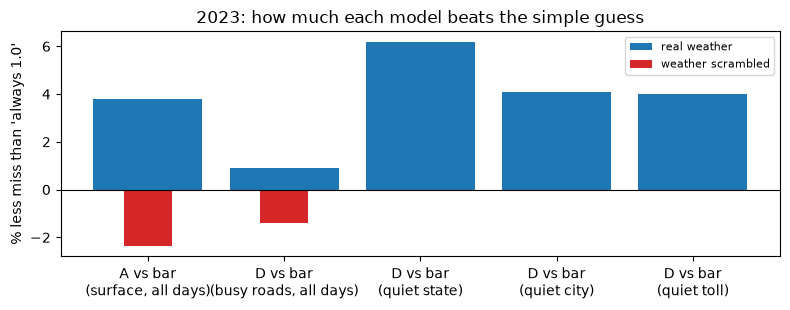

In [16]:
# ---- Results so far (2023, the practice year) ----
results_2023 = pd.DataFrame(RESULTS)
cols = ["test", "question", "pass_line", "value", "passed"]
print("RESULTS, 2023 practice year (2024 not opened yet)")
print(results_2023[cols].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.2))
labels = ["A vs bar\n(surface, all days)", "D vs bar\n(busy roads, all days)", "D vs bar\n(quiet state)",
          "D vs bar\n(quiet city)", "D vs bar\n(quiet toll)"]
real = [gain_a_real, d_busy_real] + [next(r["gain_%"] for r in RESULTS if r["test"] == f"5c. Quiet {l} roads")
                                     for l in ["state", "city", "toll"]]
ax.bar(labels, real, color="#1f77b4", label="real weather")
ax.bar(labels[:2], [gain_a_scr, gain_d_scr], color="#d62728", width=0.35, label="weather scrambled")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("% less miss than 'always 1.0'")
ax.set_title("2023: how much each model beats the simple guess")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Step 12. Real 2023 scores for the app

Model D's 2023 predictions for every road with a map shape, in the app's format, with "what really happened" as a
coarse level for the 5 busiest roads only.
They come from the practice model (trained on 2021 to 2022), so they are honest out-of-sample predictions.

### First, the alert rule (chosen on 2023)

With one line for every road, a heavy-rain day flags almost every road, and a driver would be pinged everywhere.
The useful message on those days is *which roads are worst today*. So we compare alert rules on 2023 (the practice
year, where choices are allowed). "Right" and "caught" are measured on the busy roads, where a bad day can be judged;
the last column covers every road:
* **global line:** one cut-off for every road, set at the top 10% of training predictions (the plan's first guess);
* **global line + worst part of today:** also among the worst 15% or 25% of roads that day;
* **today only:** the worst 10% of roads each day, as long as the prediction is at least 1.10.

*Added Nov 15, before 2024 was opened:* the shipped alert's flagged road-days split into rain days and dry days. The
line-plus-15% rule also fired on 114 dry days of 2023, because the model's prediction moves with temperature,
humidity, season and holidays, not only with rain, and those dry-day flags ran only +8.6% above normal. **Decision
(Nov 15, before 2024 was opened):** the app alerts only on days with rain or ice. The rule table shows
both versions; Test 6 still reports the plan's first-guess rule.

In [17]:
w23d = wx.loc[sorted(rte["date"].unique())]
r23 = rte[rte["unit"].isin(APP_POS)].copy()
rules = {
    "global line (plan's first guess)": shipped_mask(r23, "D", ALERT_THRESHOLD, 1.0),
    "global line + worst 25% today": shipped_mask(r23, "D", ALERT_THRESHOLD, 0.25),
    "global line + worst 15% today": shipped_mask(r23, "D", ALERT_THRESHOLD, 0.15),
    "worst 10% today, at least 1.10": shipped_mask(r23, "D", 1.10, 0.10),
    "every rain day (simple rule)": (r23["rained"] == 1).to_numpy(),
}
# The shipped rule since Nov 15 (chosen on 2023, before 2024 was opened): the line plus the worst 15% of roads that day,
# but only on days with rain or ice, so the app never chimes on a clear day.
weather_rows = ((r23["rained"] == 1) | (r23["ice"] == 1)).to_numpy()
rules[f"global line + worst {ALERT_TOP_SHARE:.0%} today, rain or ice days only"] = (
    rules[f"global line + worst {ALERT_TOP_SHARE:.0%} today"] & weather_rows)
SHIPPED_RULE = f"global line + worst {ALERT_TOP_SHARE:.0%} today" + (", rain or ice days only" if ALERT_WEATHER_ONLY else "")
busy_mask = r23["unit"].isin(busy_units).to_numpy()
bad_all = (r23["score"] > r23["unit"].map(bad_line)).to_numpy()
rain_day_flags = r23.groupby("date")["rained"].first()
rule_rows = []
for name, m in rules.items():
    per_day = pd.Series(m).groupby(r23["date"].to_numpy()).sum()
    extra_pct = 100 * (r23.loc[m, "crashes"].sum() - r23.loc[m, "normal"].sum()) / r23.loc[m, "normal"].sum()
    hr = hit_rates(m[busy_mask], bad_all[busy_mask])
    rule_rows.append({"rule": name, "roads flagged on a typical rain day": int(per_day[rain_day_flags.to_numpy() == 1].median()),
                      "most in one day": int(per_day.max()), "busy roads: right %": hr["right_%"],
                      "busy roads: bad days caught %": hr["bad_days_caught_%"],
                      "crashes vs normal on flagged road-days": round(extra_pct, 1)})
rule_table = pd.DataFrame(rule_rows).set_index("rule")
print(rule_table.to_string())
chosen = rule_table.loc[SHIPPED_RULE]
rain_rule = rule_table.loc["every rain day (simple rule)"]
print(f"\nShipped rule: global line ({ALERT_THRESHOLD:.2f}) + worst {ALERT_TOP_SHARE:.0%} of roads that day"
      f"{', only on days with rain or ice' if ALERT_WEATHER_ONLY else ''}. At most "
      f"{int(chosen['most in one day'])} roads in a day; right {chosen['busy roads: right %']}% of the time on busy roads "
      f"(every-rain-day rule: {rain_rule['busy roads: right %']}%); flagged road-days ran "
      f"{chosen['crashes vs normal on flagged road-days']:+.1f}% vs normal (every-rain-day rule: "
      f"{rain_rule['crashes vs normal on flagged road-days']:+.1f}%). Test 6 still reports the plan's first-guess rule.")
m_ship = rules[SHIPPED_RULE]
flag_s = r23[m_ship]
IMPACT_SHIPPED_2023 = {"flagged_road_days": int(len(flag_s)), "crashes": int(flag_s["crashes"].sum()),
                       "normal_days_would_bring": round(float(flag_s["normal"].sum())),
                       "extra_crashes": round(float(flag_s["crashes"].sum() - flag_s["normal"].sum())),
                       "extra_%": round(100 * (flag_s["crashes"].sum() / flag_s["normal"].sum() - 1), 1)}
IMPACT_SHIPPED_2023["all_2023_road_days_vs_normal_%"] = YEAR_DRIFT_2023
print("Impact of the shipped alert, 2023 (totals only):", IMPACT_SHIPPED_2023)

# For information (added Nov 15, before 2024 was opened): the shipped alert's flagged road-days, split by whether it
# rained (0.3 mm or more). With the rain-or-ice filter none fall on dry days. The last line shows the same rule without
# the filter: it also fired on dry days, because the model's prediction moves with temperature, humidity, season and
# holidays, not only rain, and those flags were much weaker.
SPLIT_2023 = {}
for lab, sel in [("rain days", flag_s["rained"] == 1), ("dry days", flag_s["rained"] == 0)]:
    f_ = flag_s[sel]
    SPLIT_2023[lab] = (int(len(f_)), round(100 * (f_["crashes"].sum() / f_["normal"].sum() - 1), 1) if len(f_) else None)
    print(f"  flagged on {lab}: {SPLIT_2023[lab][0]:,} road-days" + (f", {SPLIT_2023[lab][1]:+.1f}% vs normal" if len(f_) else ""))
m_any = rules[f"global line + worst {ALERT_TOP_SHARE:.0%} today"]
dry_any = r23[m_any & ((r23["rained"] == 0) & (r23["ice"] == 0)).to_numpy()]
DRY_FLAGS_UNFILTERED_2023 = {"flagged_road_days": int(len(dry_any)), "days": int(dry_any["date"].nunique()),
                             "extra_%": round(100 * (dry_any["crashes"].sum() / dry_any["normal"].sum() - 1), 1)}
print("  without the rain-or-ice filter, the same rule's flags on dry days:", DRY_FLAGS_UNFILTERED_2023)

                                                      roads flagged on a typical rain day  most in one day  busy roads: right %  busy roads: bad days caught %  crashes vs normal on flagged road-days
rule                                                                                                                                                                                                  
global line (plan's first guess)                                                      128              850                 21.9                           21.8                                    32.1
global line + worst 25% today                                                         128              212                 23.7                           19.7                                    36.7
global line + worst 15% today                                                         127              127                 25.0                           17.6                                    38.7
worst

### The 2023 file

In [18]:
d23 = rte[rte["unit"].isin(app_roads["unit"])].copy()
d23["id"] = d23["unit"].map(roads.set_index("unit")["id"])
pred_23 = d23.pivot(index="date", columns="id", values="D")[APP_IDS]
act_23 = d23[d23["id"].isin(HEADLINE_IDS)].pivot(index="date", columns="id", values="score")
assert pred_23.shape == (365, len(APP_IDS)) and pred_23.notna().all().all()
days_23 = write_scores_file(os.path.join(DATA_DIR, "scores_2023.json"), 2023, f"D ({D_KIND})", pred_23, act_23,
                            ALERT_THRESHOLD, made_up=False, top_share=ALERT_TOP_SHARE)
size_mb = os.path.getsize(os.path.join(DATA_DIR, "scores_2023.json")) / 1e6
alerts_per_day = pd.Series([len(d["alert"]) for d in days_23], index=pred_23.index)
print(f"Wrote data/scores_2023.json: {len(days_23)} days x {len(APP_IDS)} roads, {size_mb:.1f} MB")
print(f"Alerts per day: median {alerts_per_day.median():.0f}, on rain days median "
      f"{alerts_per_day[w23d['rained'] == 1].median():.0f}, max {alerts_per_day.max()}, days with none {int((alerts_per_day == 0).sum())}")
assert size_mb < 8 and alerts_per_day.max() <= int(ALERT_TOP_SHARE * len(APP_IDS))
dry_dates = set(w23d.index[w23d["rained"] == 0].strftime("%Y-%m-%d"))
dry_alert_days = [d for d in days_23 if d["alert"] and d["date"] in dry_dates]
print(f"Dry days with at least one road flagged: {len(dry_alert_days)} of {len(dry_dates)}; with no weather reason listed "
      f"in the file: {sum(1 for d in dry_alert_days if not d['reasons'])}")

# Three demo dates for the app: a first rain after a dry spell, a thunderstorm day, a quiet dry day.
# Picked from the weather and the model's own predictions only, never from crashes. The same rule picks 2024's.
by_id = app_roads.set_index("id")


def demo_days(w_year, pred_year, days_list):
    """The demo dates for one year, printed with each day's alerts, reasons and top three roads."""
    first_rain_days = w_year[(w_year["rain_mm"] >= 5) & (w_year["dry_days_before_rain"] >= 7)].index
    storm_days = w_year[(w_year["thunder"] == 1) & (w_year["rain_mm"] >= 12.7)].index
    dry_days = w_year[(w_year["rained"] == 0) & (w_year["fog"] == 0) & (w_year["holiday"] == 0)].index
    mean_pred = pred_year.mean(axis=1)
    first = mean_pred[first_rain_days].idxmax()
    picks = {"first rain after a dry spell": first,
             "thunderstorm with heavy rain": mean_pred[storm_days.difference([first])].idxmax(),
             "quiet dry day": mean_pred[dry_days].idxmin()}
    for label, day in picks.items():
        d = days_list[pred_year.index.get_loc(day)]
        top = sorted(range(len(APP_IDS)), key=lambda i: (-d["pred"][i], i))[:3]
        names = [f"{by_id.loc[APP_IDS[i], 'display_name']} {d['pred'][i]:.2f}" for i in top]
        print(f"  {label}: {day.date()}  alerts {len(d['alert'])}, reasons {d['reasons']}, top: {', '.join(names)}")
    return picks


DEMO_2023 = demo_days(w23d, pred_23, days_23)
ROUTES = write_routes(days_23, DEMO_2023["first rain after a dry spell"], DEMO_2023["quiet dry day"], "real 2023 scores")

Wrote data/scores_2023.json: 365 days x 850 roads, 1.7 MB
Alerts per day: median 0, on rain days median 127, max 127, days with none 310
Dry days with at least one road flagged: 0 of 294; with no weather reason listed in the file: 0
  first rain after a dry spell: 2023-12-15  alerts 127, reasons ['First rain after 14 dry days', 'Heavy rain (15 mm)', 'Fog'], top: US 175 2.09, US 75 2.09, US 81 2.07
  thunderstorm with heavy rain: 2023-10-25  alerts 127, reasons ['Heavy rain (64 mm)', 'Thunderstorms', 'Fog'], top: President George Bush Turnpike 3.34, Sam Rayburn Tollway 3.25, IH 635 toll lanes 3.19
  quiet dry day: 2023-08-25  alerts 0, reasons [], top: FM 5 1.01, US 75 1.01, FM 718 1.01
('route-1', '2023-12-15 (real 2023 scores); drives I-35E; passes flagged: FM 66, I-35E, US 77')
('route-2', '2023-12-15 (real 2023 scores); drives US 75; passes flagged: FM 455, SH 121, SH 5, Sam Rayburn Tollway, US 75')
('route-3', '2023-12-15 (real 2023 scores); drives I-30; passes flagged: I-30, I-635

## Step 13. The road-chemistry layer: a decision model that reasons about road surfaces

Models A to D learn only from numbers. This step adds outside knowledge. A **decision model** (Drex Max v1.1 from
Nace AI; Jev from TypeSafe is the backup, same request format) is an AI model that reads text and, instead of
writing sentences, picks a level and says how sure it is of each level. It runs only here, in the notebook: the app
never calls it. Each day it reads:

* a **background sheet** of about 1,200 words on how weather affects road surfaces (first rain after a dry spell, wet grip on
  concrete versus asphalt, heat and asphalt, seal-coat roads, ice, fog and storms, and how many people drive), built
  from government and university sources that were each re-checked by a second reader (`docs/chemistry_sheets/`);
* that day's weather and the 14 days before it, **with no date and no year** (season and two weeks of weather could
  still hint at an extreme event, but it is never told which day it is);

and scores each of 12 road types from "safer than normal" (0) to "much riskier" (4). It never sees a crash count
or a date. (Through the improvement loop below, a rewritten sheet can carry lessons drawn from 2021 crash records,
which are training data.)

Those scores become extra inputs to Model D. Model D, trained on real crashes, learns **how much to trust the
chemistry** and when. The combination is Model E.

**The improvement loop.** The sheet can be rewritten to fix the decision model's mistakes, but only in a way that
can't peek at the test years: an error report from **2021 alone** goes to a language model (Claude), which rewrites
the sheet; each version is then judged by training on 2021 and testing on **2022**. The version that does best on
2022 is used; 2023 stays untouched until the final check below. Every version is kept in `docs/chemistry_sheets/`.

Every answer is cached in `data/chemistry_cache.jsonl`, so once the layer has run, anyone can rerun this notebook
without an API key. With no cached answers and no key, this layer is skipped and Model D stays the model (as in the
current saved run).

In [19]:
import glob
import sys
sys.path.insert(0, os.path.abspath("."))
import chemistry_layer as chem

chem.load_env(".env")
SHEET_DIR = os.path.join("..", "docs", "chemistry_sheets")
CHEM_CACHE = os.path.join(DATA_DIR, "chemistry_cache.jsonl")


def read_sheet(path):
    with open(path) as fh:
        text = fh.read().split("---SOURCES---")[0].strip()
    assert not re.search(r"\b(19|20)\d\d\b", text), f"{path}: the sheet the model reads must not contain a year"
    return text


sheet_files = sorted([p for p in glob.glob(os.path.join(SHEET_DIR, "v*.md")) if re.fullmatch(r"v\d+\.md", os.path.basename(p))],
                     key=lambda p: int(re.search(r"v(\d+)\.md$", p).group(1)))
sheets = {os.path.basename(p)[:-3]: read_sheet(p) for p in sheet_files}
print("Sheet versions:", {k: f"{len(v.split())} words" for k, v in sheets.items()})

roads["road_type"] = [chem.road_type(l, s_, c, f) for l, s_, c, f in
                      zip(roads["layer"], roads["surface"], roads["road_class"], roads["func_sys"])]
assert roads["road_type"].isin(chem.ROAD_TYPES).all()
print("Roads per road type:", roads["road_type"].value_counts().to_dict())

all_chem_days = list(wx.index[(wx.index.year >= 2021) & (wx.index.year <= 2023)])   # 2024 waits for step 14
train_chem_days = [d for d in all_chem_days if d.year <= 2022]
provider = next((p for p, cfg in chem.PROVIDERS.items() if os.environ.get(cfg["key_env"])), "nace")
has_key = bool(os.environ.get(chem.PROVIDERS[provider]["key_env"]))
first_sheet = next(iter(sheets.values()), "(sheet pending)")
preview = chem.run(wx, all_chem_days, first_sheet, CHEM_CACHE, provider=provider, dry_run=True)
example_state = preview["example"]["state"]
assert not re.search(r"\b(19|20)\d\d\b", example_state), "a year leaked into what the decision model sees"
print(f"\nWhat the decision model sees for one day ({len(example_state):,} characters; the conditions part):\n")
print(example_state[example_state.index("CONDITIONS FOR THE DAY"):][:1500])

Sheet versions: {'v0': '1228 words'}
Roads per road type: {'city_street': 589, 'asphalt_fm': 63, 'concrete_highway': 32, 'asphalt_highway': 30, 'seal_coat_road': 29, 'aoc_highway': 28, 'concrete_freeway': 22, 'concrete_fm': 20, 'aoc_freeway': 17, 'asphalt_city_state': 11, 'toll_road': 8, 'asphalt_freeway': 6}
chemistry layer: nace/drex-max-v1.1, sheet d8b7526d4c95: 0 days cached, 1095 to score

What the decision model sees for one day (8,382 characters; the conditions part):

CONDITIONS FOR THE DAY BEING SCORED
Season: winter in Dallas-Fort Worth, Texas.
Public holiday today: yes.

TODAY:
- Rain: 0.3 mm (0.01 inches).
- High 40 F, low 35 F. Humidity 76 to 100 percent.
- Wind: average 14 mph, gusts to 31 mph.
- Also observed: fog.

RECENT HISTORY:
- Days since the last rain before today: 1.
- Rain over the previous 7 days: 51.4 mm.
- Days at 95 F or hotter in the previous 7 days: 0.
- Ice, sleet or freezing weather in the previous 3 days: no.
- Day by day, oldest first (rain mm / high F

In [20]:
def chem_table(answers):
    """Long table: one row per day and road type, with the score, confidence and chance of level 3 or 4."""
    rows = []
    for day, by_type in answers.items():
        for t, a in by_type.items():
            p = a.get("probabilities") or {}
            p = {str(k): v for k, v in p.items()}
            assert set(p) == {"0", "1", "2", "3", "4"}, f"unexpected probability keys {sorted(p)} on {day}"
            assert abs(sum(float(v) for v in p.values()) - 1) < 0.02, f"probabilities don't sum to 1 on {day}"
            assert 0 <= float(a.get("score")) <= 4 and 0 <= float(a.get("confidence")) <= 1, f"score or confidence out of range on {day}"
            rows.append({"date": pd.Timestamp(day), "road_type": t, "chem_score": a.get("score"),
                         "chem_conf": a.get("confidence"),
                         "chem_p_high": float(p.get("3", 0) or 0) + float(p.get("4", 0) or 0)})
    out = pd.DataFrame(rows)
    assert out[["chem_score", "chem_conf"]].notna().all().all(), "some answers came back empty"
    return out


def add_chem(frame, table):
    f = frame.copy()
    f["road_type"] = f["unit"].map(roads.set_index("unit")["road_type"])
    out = f.merge(table, on=["date", "road_type"], how="left")
    assert len(out) == len(frame)
    return out


CONDITIONS = {
    "dry day": lambda f: f["rained"] == 0,
    "light rain (under 5 mm)": lambda f: (f["rained"] == 1) & (f["rain_mm"] < 5),
    "heavy rain (12.7 mm or more)": lambda f: f["rain_mm"] >= 12.7,
    "first rain after 7+ dry days": lambda f: (f["rained"] == 1) & (f["dry_days_before_rain"] >= 7),
    "rain the day after rain": lambda f: (f["rained"] == 1) & (f["days_since_rain"] == 1),
    "summer rain after 3+ hot days": lambda f: (f["rained"] == 1) & f["date"].dt.month.between(5, 9) & (f["hot_days_last_7"] >= 3),
    "fog": lambda f: f["fog"] == 1,
    "thunderstorms": lambda f: f["thunder"] == 1,
    "ice, sleet or freezing": lambda f: f["ice"] == 1,
    "holiday": lambda f: f["holiday"] == 1,
}


def chem_report(frame):
    """How the chemistry scores line up with what happened, by road type and by weather condition."""
    by_type = []
    for t, g in frame.groupby("road_type"):
        daily = g.groupby("date").agg(c=("crashes", "sum"), n=("normal", "sum"), s=("chem_score", "first"))
        by_type.append({"road type": t, "days": len(daily), "mean score": round(daily["s"].mean(), 2),
                        "rank match (score vs what happened)": round(spearmanr(daily["s"], daily["c"] / daily["n"]).statistic, 3)})
    by_cond = []
    for name, cond in CONDITIONS.items():
        g = frame[cond(frame)]
        if len(g):
            by_cond.append({"condition": name, "days": g["date"].nunique(), "mean score (0-4)": round(g["chem_score"].mean(), 2),
                            "crashes vs normal (all roads)": f"{100 * (g['crashes'].sum() / g['normal'].sum() - 1):+.0f}%"})
    return pd.DataFrame(by_type).set_index("road type"), pd.DataFrame(by_cond).set_index("condition")


def inner_total(train_frame, val_frame, feats):
    """Train on one year, test on the next: busy-road miss plus quiet-road miss (summed per layer per day)."""
    m = FIT_D(train_frame, feats)
    v = val_frame.copy()
    v["P"] = m.predict(v[feats])
    b = v[v["unit"].isin(busy_units)]
    q = quiet_groups(v, "P")
    return miss(b["P"], b["score"]) + miss(q["pred"], q["score"])


FEAT_CHEM = ["chem_score", "chem_conf", "chem_p_high"]
FEAT_E = FEAT_D + FEAT_CHEM
# The sheet-picking fold is rebuilt from 2021 alone: normals, weekday factors and train_rate all come from 2021, so no
# 2022 crash numbers reach the training side or the error report. (Which roads are in, and busy or quiet, was chosen
# on 2021-2023 counts in step 3, the same for every sheet version.)
inner_scored = add_score(road_daily, train_years=(2021, 2021), end="2022-12-31", group_of=layer_of, quiet=quiet, main="fixed")
inner = with_baselines(inner_scored).merge(wx_model, left_on="date", right_index=True)
inner = add_road_features(inner[inner["date"].dt.year.isin([2021, 2022])].reset_index(drop=True))
y21, y22 = inner[inner["date"].dt.year == 2021], inner[inner["date"].dt.year == 2022]
assert (y21["train_rate"] == y21["unit"].map(road_daily[road_daily["date"].dt.year == 2021].groupby("unit")["crashes"].mean())).all()
inner_rows, version_answers = [{"version": "no chemistry (Model D)", "train 2021, test 2022": inner_total(y21, y22, FEAT_D)}], {}
for name, text in sheets.items():
    todo = chem.run(wx, train_chem_days, text, CHEM_CACHE, provider=provider, dry_run=True)["todo"]
    if todo and not has_key:
        print(f"{name}: {todo} training days not scored yet and no API key, skipped")
        continue
    answers = chem.run(wx, train_chem_days, text, CHEM_CACHE, provider=provider)
    version_answers[name] = answers
    tab = chem_table(answers)
    r21, r22 = add_chem(y21, tab), add_chem(y22, tab)
    inner_rows.append({"version": name, "train 2021, test 2022": inner_total(r21, r22, FEAT_E)})
    rep_type, rep_cond = chem_report(r21)        # the error report the rewriter sees: 2021 only
    with open(os.path.join(SHEET_DIR, f"{name}_report_2021.md"), "w") as fh:
        fh.write(f"# Error report for sheet {name}, from 2021 only\n\n## By road type\n\n```\n{rep_type.to_string()}\n```\n\n"
                 f"## By weather condition\n\n```\n{rep_cond.to_string()}\n```\n")
inner_table = pd.DataFrame(inner_rows).set_index("version").round(4)
print("\nPicking the sheet: train on 2021, test on 2022 (lower is better; 2023 not used):")
print(inner_table.to_string())
CHEM_READY = len(version_answers) > 0
if CHEM_READY:
    BEST_SHEET = inner_table.drop(index="no chemistry (Model D)")["train 2021, test 2022"].idxmin()
    print(f"Best sheet: {BEST_SHEET}")
    chem_answers = chem.run(wx, all_chem_days, sheets[BEST_SHEET], CHEM_CACHE, provider=provider)
else:
    print("\nChemistry layer not run yet (no API key and no cached answers). Model D stays the model.")

chemistry layer: nace/drex-max-v1.1, sheet d8b7526d4c95: 0 days cached, 730 to score
v0: 730 training days not scored yet and no API key, skipped

Picking the sheet: train on 2021, test on 2022 (lower is better; 2023 not used):
                        train 2021, test 2022
version                                      
no chemistry (Model D)                 1.0563

Chemistry layer not run yet (no API key and no cached answers). Model D stays the model.


### Model E against Model D on 2023

Pass line, written before any chemistry result was seen: **Model E replaces D only if its 2023 miss is lower
both overall (busy roads plus quiet roads summed per layer) and on rain days.** Test 13 reports whether the
rain-day gain is "real" (950 of 1,000 week redraws). If E isn't better, D stays and the write-up says so.

In [21]:
E_WINS = False
if CHEM_READY:
    ctab = chem_table(chem_answers)
    road_e = add_chem(road, ctab)
    assert road_e[FEAT_CHEM].notna().all().all()
    rep_type, rep_cond = chem_report(road_e[is_train(road_e)])
    print(f"Chemistry scores on their own, training years 2021-2022 (sheet {BEST_SHEET}):")
    print(rep_type.to_string(), "\n")
    print(rep_cond.to_string())

    etr, ete = road_e[is_train(road_e)], road_e[is_test(road_e)].copy()
    model_e = FIT_D(etr, FEAT_E)
    ete["E"] = model_e.predict(ete[FEAT_E])
    ete = ete.merge(rte[["unit", "date", "D"]], on=["unit", "date"], how="left")
    assert ete["D"].notna().all()

    def total_miss(frame, col, rain_only=False):
        f = frame[frame["rained"] == 1] if rain_only else frame
        b = f[f["unit"].isin(busy_units)]
        q = quiet_groups(f, col)
        return miss(b[col], b["score"]) + miss(q["pred"], q["score"])

    e_vs_d = pd.DataFrame({"D": [total_miss(ete, "D"), total_miss(ete, "D", True)],
                           "E": [total_miss(ete, "E"), total_miss(ete, "E", True)]}, index=["all days", "rain days"])
    print("\nModel E (D + chemistry) against Model D, 2023 total miss (busy + quiet summed; lower is better):")
    print(e_vs_d.round(4).to_string())
    rain_b = ete[(ete["rained"] == 1) & ete["unit"].isin(busy_units)]
    compare("13. Chemistry layer (busy roads)", "Does road-chemistry reasoning add to the crash-trained model?",
            "real gain over D on rain days (busy roads)", "D", "E", rain_b, "D", "E")
    for lyr in ["state", "toll", "city"]:
        qd, qe = quiet_groups(ete[ete["rained"] == 1], "D"), quiet_groups(ete[ete["rained"] == 1], "E")
        a_, b_ = qd[qd.layer == lyr].reset_index(drop=True), qe[qe.layer == lyr].reset_index(drop=True)
        ed, ee = np.abs(a_["pred"] - a_["score"]), np.abs(b_["pred"] - b_["score"])
        sh = week_redraw(ed.to_numpy(), ee.to_numpy(), a_["date"])
        g = 100 * (ed.mean() - ee.mean()) / ed.mean()
        RESULTS.append({"test": f"13. Chemistry layer (quiet {lyr})", "question": "Does chemistry help on quiet roads?",
                        "pass_line": "real gain over D on rain days, summed per layer", "year": 2023,
                        "value": f"D {ed.mean():.3f} -> E {ee.mean():.3f} ({g:+.1f}%), real in {sh * 1000:.0f}/1000",
                        "passed": bool(sh >= 0.95 and g > 0), "gain_%": round(g, 1), "redraw_share": sh})
    E_WINS = bool(e_vs_d.loc["all days", "E"] < e_vs_d.loc["all days", "D"]
                  and e_vs_d.loc["rain days", "E"] < e_vs_d.loc["rain days", "D"])
    print(f"\nModel E {'REPLACES' if E_WINS else 'does NOT replace'} Model D.")
    print(pd.DataFrame(RESULTS)[["test", "value", "passed"]].tail(4).to_string(index=False))

## Step 14. The final exam: 2024, opened once

Everything above was chosen on 2023. Now every setting is frozen: the normals, the penalty strengths, boosting vs
forest, the bar, the chemistry sheet (if used) and the alert rule (its line is set the same way, at the top 10% of the
retrained model's training predictions, so its value can change). The models are retrained on 2021 to
2023 and scored on **2024**, a year no model or choice above has used, and the main tests run again with the same
pass lines (Tests 7 and 9 in a shorter form: Model A on the surface groups and Model D on the busy roads only; the
no-ice-days-or-holidays versions of Tests 2 and 5 are not rerun).

The whole exam is one function, `final_exam(test_year)`. Before 2024 was opened it was run once with 2023 as the
stand-in test year (training on 2021 to 2022), to prove the code reproduces the practice results. It runs on 2024
only when `notebook/OPEN_2024.flag` exists, which a team member creates by hand after reading the 2023 results and the audit.
**No model changes after this step.**

Test 10 (did we tune too hard on 2023?) passes if Model A's gain over the bar on 2024 points the same way and is at
least half of its 2023 gain. The other models' 2024 results print in one table, to read against the 2023 results
above.

*Added Nov 15, before 2024 was opened (information only):* the exam also reports the three simple guesses on the
test year (persistence included), the rain-only guess, D against the bar road by road, the two comparison rankings,
the every-rain-day rule's impact, the shipped rule's hit rates, and its flagged road-days on rain and dry days. The
dry run checks that each one equals its 2023 practice value.

In [22]:
def compare_rows(out, year, test, question, pass_line, base, new, d, base_name, new_name, informational=False):
    e_b, e_n = np.abs(d[base] - d["score"]), np.abs(d[new] - d["score"])
    share = week_redraw(e_b.to_numpy(), e_n.to_numpy(), d["date"])
    g = 100 * (e_b.mean() - e_n.mean()) / e_b.mean()
    out.append({"test": test, "question": question, "pass_line": pass_line, "year": year, "gain_%": round(g, 1),
                "redraw_share": round(share, 3),
                "value": f"{base_name} {e_b.mean():.3f} -> {new_name} {e_n.mean():.3f} ({g:+.1f}%), real in {share * 1000:.0f}/1000",
                "passed": None if informational else bool(share >= 0.95 and g > 0)})
    return g


def final_exam(test_year, write_files=False):
    """Retrain every model with the settings frozen on 2023 on the years before test_year, score test_year, rerun the
    main tests. test_year=2023 is the stand-in dry run; 2024 is the real exam."""
    train_years = (2021, test_year - 1)
    res = []
    rs = add_score(road_daily, train_years=train_years, end=f"{test_year}-12-31", group_of=layer_of, quiet=quiet, main="fixed")
    ss = add_score(surface_daily, train_years=train_years, end=f"{test_year}-12-31")
    for name_, d_ in [("road", rs), ("surface", ss)]:
        live_ = d_[d_["date"].dt.year >= 2021]
        assert (live_["normal"] > 0).all() and live_["normal"].notna().all(), name_
    sf = with_baselines(ss).merge(wx_model, left_on="date", right_index=True)
    sf = sf[sf["date"].dt.year >= 2021].reset_index(drop=True)
    rf = with_baselines(rs).merge(wx_model, left_on="date", right_index=True)
    rf = add_road_features(rf[rf["date"].dt.year >= 2021].reset_index(drop=True))
    rf[BAR_COL] = rf[BAR_COL].fillna(1.0) if BAR_COL in rf else 1.0
    is_tr = lambda d_: d_["date"].dt.year.between(*train_years)
    is_te = lambda d_: d_["date"].dt.year == test_year
    s_tr, s_te = sf[is_tr(sf)], sf[is_te(sf)].copy()
    r_tr, r_te = rf[is_tr(rf)], rf[is_te(rf)].copy()

    # The models, refit with frozen settings
    s_te["A"] = fit_ridge(s_tr, FEAT_A, alpha_a).predict(s_te[FEAT_A])
    s_te["B"] = fit_ridge(s_tr, FEAT_B, alpha_b).predict(s_te[FEAT_B])
    s_te["C"] = np.nan
    for srf, a_ in alpha_c.items():
        sel_ = s_te["unit"] == srf
        s_te.loc[sel_, "C"] = fit_ridge(s_tr[s_tr["unit"] == srf], FEAT_B, a_).predict(s_te.loc[sel_, FEAT_B])
    d_final = FIT_D(r_tr, FEAT_D)
    r_te["D"] = d_final.predict(r_te[FEAT_D])
    r_te["D_no_build"] = FIT_D(r_tr, FEAT_NO_BUILD).predict(r_te[FEAT_NO_BUILD])
    final_col, final_model, final_feats = "D", d_final, FEAT_D
    if E_WINS:
        ans_ = chem.run(wx, list(wx.index[wx.index.year.isin(range(2021, test_year + 1))]), sheets[BEST_SHEET],
                        CHEM_CACHE, provider=provider)
        rfe = add_chem(rf, chem_table(ans_))
        e_final = FIT_D(rfe[is_tr(rfe)], FEAT_E)
        r_te = r_te.merge(rfe[is_te(rfe)][["unit", "date"] + FEAT_CHEM], on=["unit", "date"], how="left")
        r_te["E"] = e_final.predict(r_te[FEAT_E])
        final_col, final_model, final_feats = "E", e_final, FEAT_E
        rf = rfe

    # Test 1 again, for information: the three simple guesses on the test year (the bar itself stays frozen)
    bb1_ = r_te[r_te["unit"].isin(busy_units)]
    guesses_ = {(w_, b_): round(miss(d_[b_], d_["score"]), 3) for w_, d_ in [("surface groups", s_te), ("busy roads", bb1_)]
                for b_ in BASELINES}
    res.append({"test": "1. The simple guesses", "year": test_year, "passed": None, "pass_line": "none (the bar stays frozen)",
                "value": "; ".join(f"{w_}, {b_.replace('_', ' ')}: {v_}" for (w_, b_), v_ in guesses_.items())})

    # The tests, same pass lines as 2023
    rain_s = s_te[s_te["rained"] == 1]
    gA = compare_rows(res, test_year, "2. Model A", "Does today's weather beat the bar?", "real gain on all days", BAR_COL, "A", s_te, "bar", "A")
    compare_rows(res, test_year, "3. Model B", "Does weather history help?", "real gain over A on rain days", "A", "B", rain_s, "A", "B")
    compare_rows(res, test_year, "4. Model C", "Does surface help?", "real gain over B on rain days", "B", "C", rain_s, "B", "C")
    ra_ = s_tr.groupby(["unit", "rained"])["score"].mean()
    s_te["rain_only"] = [ra_[(u_, r_)] for u_, r_ in zip(s_te["unit"], s_te["rained"])]
    compare_rows(res, test_year, "2. Rain-only guess (extra)", "Does a one-line rain rule beat every day is normal?",
                 "for information (not a pass line)", BAR_COL, "rain_only", s_te, "bar", "rain-only", informational=True)
    compare_rows(res, test_year, "2. Model A vs the rain-only guess (extra)", "Do Model A's 31 same-day weather columns beat the one-line rain rule?",
                 "for information (not a pass line)", "rain_only", "A", s_te, "rain-only", "A", informational=True)
    bs_ = r_te[r_te["unit"].isin(busy_state)]
    compare_rows(res, test_year, "5. Model D", "Does road build help, road by road?",
                 "real gain over the same model without road build, 35 busy stretches, all days", "D_no_build", "D", bs_,
                 "D without road build", "D")
    pr_ = r_te[r_te["unit"].isin(top10)].groupby("unit").apply(
        lambda g_: pd.Series({"bar": miss(g_[BAR_COL], g_["score"]), "m": miss(g_[final_col], g_["score"])}), include_groups=False)
    w_ = int((pr_["m"] < pr_["bar"]).sum())
    res.append({"test": "5. Model D (10 busiest)", "year": test_year, "value": f"{final_col} beats the bar on {w_} of 10",
                "passed": w_ >= 7, "pass_line": "beats the bar on 7 of the 10 busiest roads"})
    rd_ = r_te[r_te["unit"].isin(busy_state) & (r_te["rained"] == 1)]
    agg_ = lambda x: x.groupby("unit").apply(lambda g_: pd.Series({"p": np.average(g_[final_col], weights=g_["normal"]),
                                                                   "a": g_["crashes"].sum() / g_["normal"].sum()}), include_groups=False)
    draws_ = rank_redraws(rd_, final_col, np.random.default_rng(SEED))
    full_ = agg_(rd_)
    rho_ = spearmanr(full_["p"], full_["a"]).statistic
    sh_ = float((np.array(draws_) > 0).mean())
    res.append({"test": "5b. Ranking", "year": test_year, "value": f"rank match {rho_:+.2f}, above zero in {sh_ * 1000:.0f}/1000",
                "passed": sh_ >= 0.95, "pass_line": "rank match above zero in 950 of 1,000"})
    hist_ = r_tr[r_tr["unit"].isin(busy_state) & (r_tr["rained"] == 1)].groupby("unit").apply(
        lambda g_: g_["crashes"].sum() / g_["normal"].sum(), include_groups=False)
    rd_ = rd_.assign(hist_rain=rd_["unit"].map(hist_))
    for label_, col_ in [("the same model without road build", "D_no_build"), ("last years' rain-day ranking", "hist_rain")]:
        other_ = rank_redraws(rd_, col_, np.random.default_rng(SEED))
        res.append({"test": f"5b. Ranking vs {label_} (extra)", "year": test_year, "passed": None,
                    "pass_line": "for information (not a pass line)",
                    "value": f"{label_}: rank match {rank_full(rd_, col_):+.2f}; {final_col} higher in {(draws_ > other_).mean() * 1000:.0f}/1000"})
    compare_rows(res, test_year, "5. D vs the bar, busy roads (extra)", "How much does D beat every day is normal, road by road?",
                 "for information (not a pass line)", BAR_COL, final_col, r_te[r_te["unit"].isin(busy_units)], "bar",
                 final_col, informational=True)
    for lyr in ["state", "toll", "city"]:
        qb_, qm_ = quiet_groups(r_te, BAR_COL), quiet_groups(r_te, final_col)
        a_ = qb_[qb_.layer == lyr].reset_index(drop=True).rename(columns={"pred": "bar_pred"})
        a_["m_pred"] = qm_[qm_.layer == lyr]["pred"].to_numpy()
        compare_rows(res, test_year, f"5c. Quiet {lyr} roads", "Does it work on quiet roads?",
                     "real gain over the bar, summed per layer per day", "bar_pred", "m_pred", a_, "bar", final_col)

    # Test 6 (first-guess line, from this exam's own training predictions), the shipped alert and the impact
    line_ = float(np.quantile(final_model.predict(r_tr[final_feats]), 0.9))
    bad_ = r_tr[r_tr["unit"].isin(busy_units)].groupby("unit")["score"].quantile(0.9)
    bb_ = r_te[r_te["unit"].isin(busy_units)].copy()
    bb_["bad"] = bb_["score"] > bb_["unit"].map(bad_)
    fg_ = pd.Series(shipped_mask(r_te, final_col, line_, 1.0), index=r_te.index)
    m6, r6 = hit_rates(fg_.loc[bb_.index], bb_["bad"]), hit_rates(bb_["rained"] == 1, bb_["bad"])
    res.append({"test": "6. Alert", "year": test_year, "pass_line": "right more often than every rain day, catching as many",
                "value": f"model right {m6['right_%']}% / catches {m6['bad_days_caught_%']}% vs rain rule {r6['right_%']}% / {r6['bad_days_caught_%']}%",
                "passed": bool(m6["right_%"] > r6["right_%"] and m6["bad_days_caught_%"] >= r6["bad_days_caught_%"])})
    ship_ = shipped_mask(r_te, final_col, line_, ALERT_TOP_SHARE, weather_only=ALERT_WEATHER_ONLY)
    fl_ = r_te[ship_]
    drift_ = 100 * (r_te["crashes"].sum() / r_te["normal"].sum() - 1)
    impact_ = {"flagged_road_days": int(len(fl_)), "crashes": int(fl_["crashes"].sum()),
               "normal_days_would_bring": round(float(fl_["normal"].sum())),
               "extra_%": round(100 * (fl_["crashes"].sum() / fl_["normal"].sum() - 1), 1),
               "all_road_days_vs_normal_%": round(drift_, 1), "alert_line": round(line_, 2)}
    # For information: the every-rain-day rule on the same roads (the app's 850), the shipped rule's hit rates on the
    # busy roads, and the shipped alert's flagged road-days split into rain days and dry days
    app_ = r_te[r_te["unit"].isin(APP_POS)]
    rr_ = app_[app_["rained"] == 1]
    impact_["every_rain_day_%"] = round(100 * (rr_["crashes"].sum() / rr_["normal"].sum() - 1), 1)
    hs_ = hit_rates(pd.Series(ship_, index=r_te.index).loc[bb_.index], bb_["bad"])
    impact_["shipped_right_%"], impact_["shipped_caught_%"] = hs_["right_%"], hs_["bad_days_caught_%"]
    for lab_, wet_ in [("rain days", 1), ("dry days", 0)]:
        f_ = fl_[fl_["rained"] == wet_]
        impact_[f"flagged_on_{lab_.replace(' ', '_')}"] = int(len(f_))
        impact_[f"{lab_.replace(' ', '_')}_extra_%"] = (round(100 * (f_["crashes"].sum() / f_["normal"].sum() - 1), 1)
                                                         if len(f_) else None)

    # Test 7 and Test 9
    vsb = {"A": 100 * (miss(s_te[BAR_COL], s_te["score"]) - miss(s_te["A"], s_te["score"])) / miss(s_te[BAR_COL], s_te["score"]),
           final_col + " busy": 100 * (miss(bb_[BAR_COL], bb_["score"]) - miss(bb_[final_col], bb_["score"])) / miss(bb_[BAR_COL], bb_["score"])}
    res.append({"test": "7. Too good", "year": test_year, "value": f"largest gain over the bar {max(vsb.values()):.1f}%",
                "passed": max(vsb.values()) < 50, "pass_line": "no miss drops by half or more"})
    days_ = wx_model.index[wx_model.index.year.isin(range(2021, test_year + 1))]
    shuf_ = pd.Series(np.random.default_rng(SEED).permutation(days_), index=days_)

    def scr(frame):
        f_ = frame.drop(columns=WEATHER_COLS).copy()
        f_["_wx_date"] = f_["date"].map(shuf_)
        return f_.merge(wx_model[WEATHER_COLS], left_on="_wx_date", right_index=True)

    ss_, rs_ = scr(sf), scr(rf.drop(columns=[c for c in FEAT_CHEM if c in rf], errors="ignore"))
    ss_te = ss_[is_te(ss_)].copy()
    ss_te["A"] = fit_ridge(ss_[is_tr(ss_)], FEAT_A, alpha_a).predict(ss_te[FEAT_A])
    rs_te = rs_[is_te(rs_)].copy()
    rs_te["D"] = FIT_D(rs_[is_tr(rs_)], FEAT_D).predict(rs_te[FEAT_D])
    rs_b = rs_te[rs_te["unit"].isin(busy_units)]
    ga_ = 100 * (miss(ss_te[BAR_COL], ss_te["score"]) - miss(ss_te["A"], ss_te["score"])) / miss(ss_te[BAR_COL], ss_te["score"])
    gd_ = 100 * (miss(rs_b[BAR_COL], rs_b["score"]) - miss(rs_b["D"], rs_b["score"])) / miss(rs_b[BAR_COL], rs_b["score"])
    res.append({"test": "9. Scrambled weather", "year": test_year, "value": f"A {ga_:+.1f}%, D busy {gd_:+.1f}% (scrambled)",
                "passed": max(ga_, gd_) <= 2.0, "pass_line": "gain falls to about zero (at or below +2%)"})

    # Test 10: did we tune too hard on 2023?
    gA23 = next(r["gain_%"] for r in RESULTS if r["test"] == "2. Model A")
    res.append({"test": "10. Practice against real (Model A)", "year": test_year,
                "value": f"2023 gain {gA23:+.1f}%, {test_year} gain {gA:+.1f}%",
                "passed": bool(gA > 0 and gA >= 0.5 * gA23), "pass_line": "same direction and at least half of 2023's gain"})

    claims_ = pd.DataFrame(check_claims(list(range(2021, test_year + 1)), sf, rf))
    claims_alone = pd.DataFrame(check_claims([test_year], sf, rf))
    out = {"results": pd.DataFrame(res), "impact": impact_, "claims_all": claims_, "claims_alone": claims_alone,
           "final_col": final_col, "line": line_, "r_te": r_te, "guesses": guesses_}
    if write_files:
        dte = r_te[r_te["unit"].isin(app_roads["unit"])].copy()
        dte["id"] = dte["unit"].map(roads.set_index("unit")["id"])
        pred_ = dte.pivot(index="date", columns="id", values=final_col)[APP_IDS]
        act_ = dte[dte["id"].isin(HEADLINE_IDS)].pivot(index="date", columns="id", values="score")
        days_list = write_scores_file(os.path.join(DATA_DIR, f"scores_{test_year}.json"), test_year,
                                      f"{final_col} ({D_KIND})", pred_, act_, line_, made_up=False, top_share=ALERT_TOP_SHARE)
        out["days_list"], out["pred"] = days_list, pred_
    return out


dry = final_exam(2023)
print("Dry run of the final exam with 2023 as the stand-in test year (should match the practice results above):")
print(dry["results"][["test", "value", "passed"]].to_string(index=False))
practice = {r["test"]: r["value"] for r in RESULTS}
for t in ["2. Model A", "3. Model B", "4. Model C", "5. Model D", "5b. Ranking", "2. Rain-only guess (extra)",
          "2. Model A vs the rain-only guess (extra)", "5. D vs the bar, busy roads (extra)",
          "5b. Ranking vs the same model without road build (extra)", "5b. Ranking vs last years' rain-day ranking (extra)"]:
    assert dry["results"].set_index("test").loc[t, "value"] == practice[t], (t, dry["results"].set_index("test").loc[t, "value"], practice[t])
print("Dry-run impact (shipped alert):", dry["impact"])
# The information-only additions reproduce their 2023 practice values too
bt_ = bar_table.set_index(["where", "guess"])["miss"]
assert all(v == round(bt_[k], 3) for k, v in dry["guesses"].items()), dry["guesses"]
assert dry["impact"]["every_rain_day_%"] == rain_rule["crashes vs normal on flagged road-days"]
assert (dry["impact"]["shipped_right_%"], dry["impact"]["shipped_caught_%"]) == (chosen["busy roads: right %"], chosen["busy roads: bad days caught %"])
assert (dry["impact"]["flagged_on_rain_days"], dry["impact"]["rain_days_extra_%"]) == SPLIT_2023["rain days"]
assert (dry["impact"]["flagged_on_dry_days"], dry["impact"]["dry_days_extra_%"]) == SPLIT_2023["dry days"]


def demo_report(w_year, pred_year, days_list):
    """A year's demo dates, and which demo drives in routes.gpx pass the roads flagged on its rain day."""
    picks = demo_days(w_year, pred_year, days_list)
    rain = picks["first rain after a dry spell"]
    print(f"Which demo drives in routes.gpx pass roads flagged on {rain.date()}:")
    for name, pts in ROUTES:
        near = flagged_near(pts, rain, days_list)
        print(f"  drive along {name}: {', '.join(near) if near else 'none'}")
    return picks


OPEN_2024 = os.path.exists("OPEN_2024.flag")
if not OPEN_2024:
    print("\n2024 is still locked. It opens only after the 2023 review and the audit (notebook/OPEN_2024.flag).")
    print("\nDry run of the 2024 demo-date step, on 2023 (the app's demo drives were built on these dates):")
    demo_report(w23d, pred_23, days_23)
else:
    final = final_exam(2024, write_files=True)
    print("THE FINAL EXAM, 2024 (trained on 2021 to 2023, every setting frozen):")
    print(final["results"][["test", "value", "passed"]].to_string(index=False))
    print("\nImpact of the shipped alert, 2024:", final["impact"])
    print("\nThe three claims, 2021 to 2024:\n", final["claims_all"][["claim", "gap", "share", "verdict"]].to_string(index=False))
    print("\nThe three claims, 2024 alone:\n", final["claims_alone"][["claim", "gap", "share", "verdict"]].to_string(index=False))
    print("\nDemo dates for the app in 2024 (same rule as 2023):")
    DEMO_2024 = demo_report(wx.loc[final["pred"].index], final["pred"], final["days_list"])

Dry run of the final exam with 2023 as the stand-in test year (should match the practice results above):
                                                    test                                                                                                                                                                                                                          value passed
                                   1. The simple guesses surface groups, persistence: 0.329; surface groups, same weekday last week: 0.328; surface groups, always one: 0.237; busy roads, persistence: 0.787; busy roads, same weekday last week: 0.776; busy roads, always one: 0.579   None
                                              2. Model A                                                                                                                                                                                 bar 0.237 -> A 0.228 (+3.8%), real in 997/1000   True
                                  

THE FINAL EXAM, 2024 (trained on 2021 to 2023, every setting frozen):
                                                    test                                                                                                                                                                                                                          value passed
                                   1. The simple guesses surface groups, persistence: 0.325; surface groups, same weekday last week: 0.325; surface groups, always one: 0.235; busy roads, persistence: 0.779; busy roads, same weekday last week: 0.765; busy roads, always one: 0.579   None
                                              2. Model A                                                                                                                                                                                 bar 0.235 -> A 0.225 (+4.3%), real in 972/1000   True
                                              3. Model B             

## Step 15. Where it fails

The days the model got most wrong on the 38 busy roads: predicted against what really happened, both as the busy
roads' combined score for the day (a ratio, never a count). Until 2024 is opened this shows the 2023 practice
year; afterwards it shows 2024, and the write-up explains at least one miss.

In [23]:
def where_it_fails(test_frame, col, n=5):
    b = test_frame[test_frame["unit"].isin(busy_units)]
    day = b.groupby("date").apply(lambda g: pd.Series({"predicted": np.average(g[col], weights=g["normal"]),
                                                       "really happened": g["crashes"].sum() / g["normal"].sum()}),
                                  include_groups=False)
    day["miss"] = day["predicted"] - day["really happened"]
    worst = day.loc[day["miss"].abs().sort_values(ascending=False).index[:n]].round(2)
    w_ = wx.loc[worst.index]
    worst["rain mm"] = w_["rain_mm"].round(1)
    worst["days since rain"] = w_["days_since_rain"].astype(int)
    worst["high F"] = (w_["high_c"] * 9 / 5 + 32).round().astype(int)
    worst["weather that day (the app's reasons)"] = [", ".join(day_reasons(w_.loc[d])) or "nothing unusual" for d in worst.index]
    worst["direction"] = np.where(worst["miss"] > 0, "predicted too high", "predicted too low")
    return worst


fail_source = final if OPEN_2024 else dry
fail_year = 2024 if OPEN_2024 else 2023
worst_days = where_it_fails(fail_source["r_te"], fail_source["final_col"])
print(f"The {len(worst_days)} worst days on the busy roads, {fail_year}:")
print(worst_days.to_string())

The 5 worst days on the busy roads, 2024:
            predicted  really happened  miss  rain mm  days since rain  high F    weather that day (the app's reasons)           direction
date                                                                                                                                      
2024-05-12       1.46             2.18 -0.71     19.8                1      68  Heavy rain (20 mm), Thunderstorms, Fog   predicted too low
2024-12-08       1.19             1.83 -0.64      2.0                1      58                      Rain (2.0 mm), Fog   predicted too low
2024-06-02       1.43             0.87  0.56     16.0                1      88  Heavy rain (16 mm), Thunderstorms, Fog  predicted too high
2024-01-17       0.66             1.22 -0.56      0.0                2      44                         nothing unusual   predicted too low
2024-05-30       1.59             1.08  0.51     32.5                2      77  Heavy rain (32 mm), Thunderstorms, Fog  pred

## Step 16. Figures for the write-up and the video

Eight figures, saved to `docs/figures/`. All from 2021 to 2023, except the road shapes, which use 2020 to 2023 crash
positions (2024 is never drawn before step 14 runs). Every crash number is a ratio to normal or a total over thousands
of road-days (fig6 adds the coarse "what really happened" level for the five busiest roads), never a single road's
daily crash count. A ninth,
`fig9_final_exam_2024.png`, puts the 2024 final exam next to the 2023 practice year; it is drawn only once 2024 is
open (until then the same code runs on the 2023 stand-in and nothing is saved).
Colors: blue, orange and gray tell categories apart; danger scores run blue (safer than normal) through gray
(normal) to red (riskier). Light background, thin marks, labels on the bars.

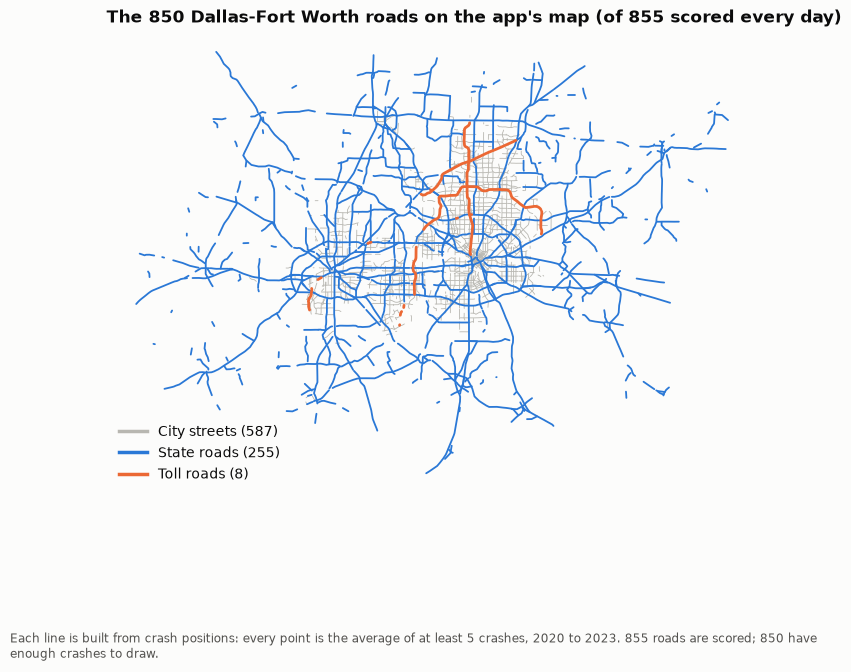

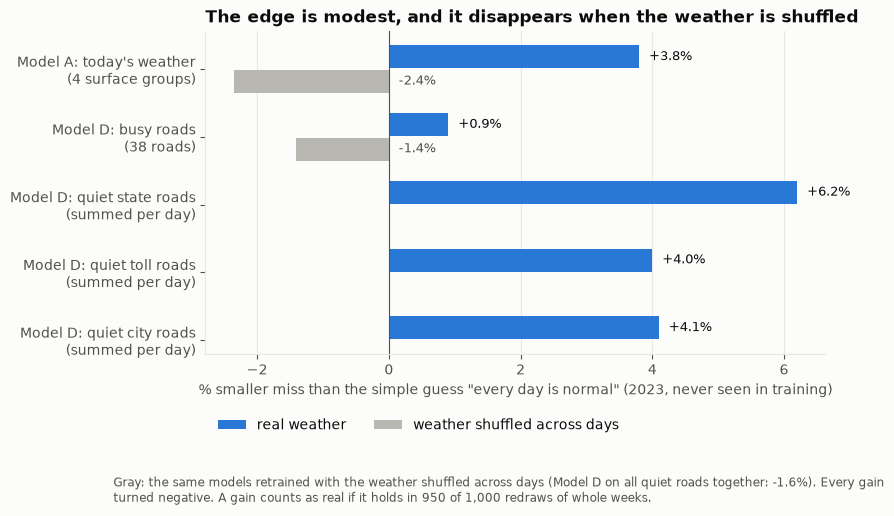

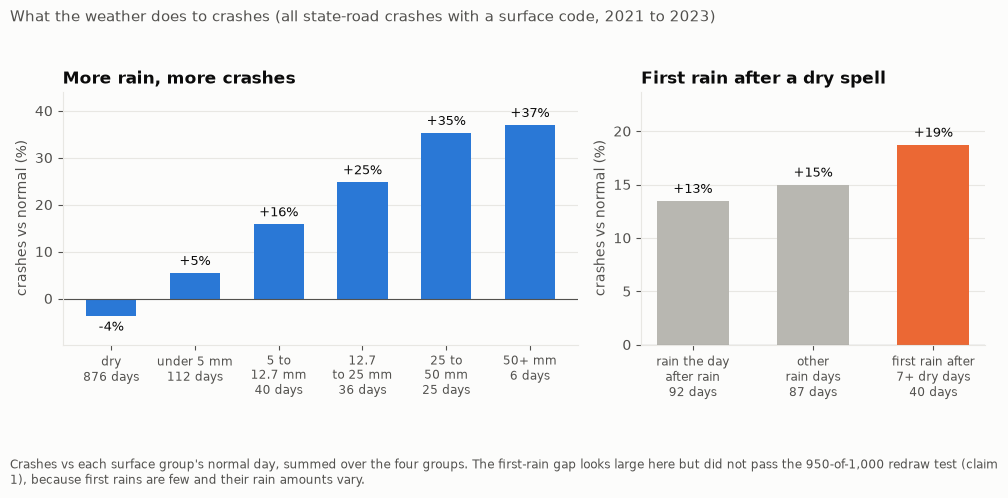

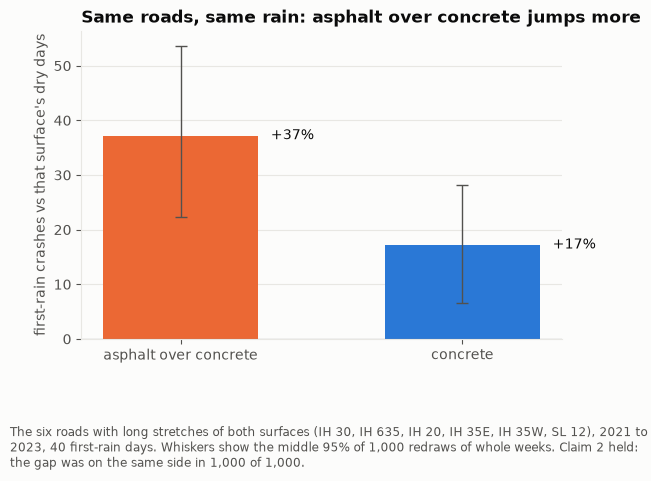

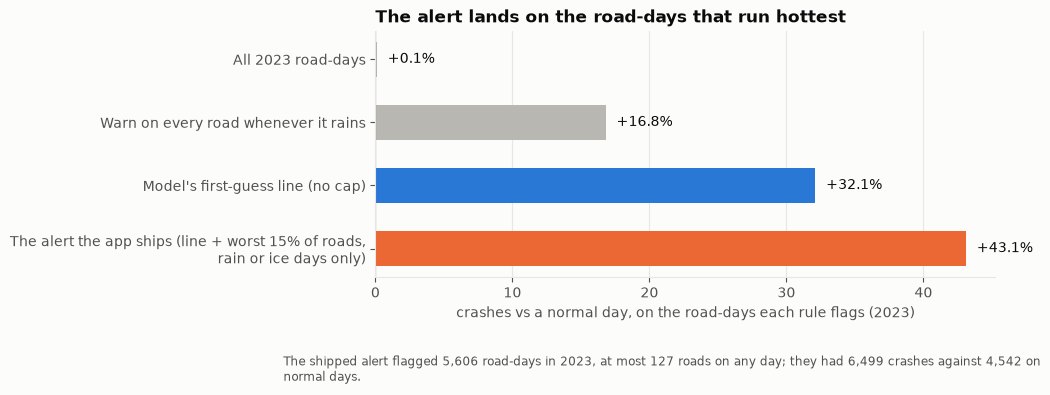

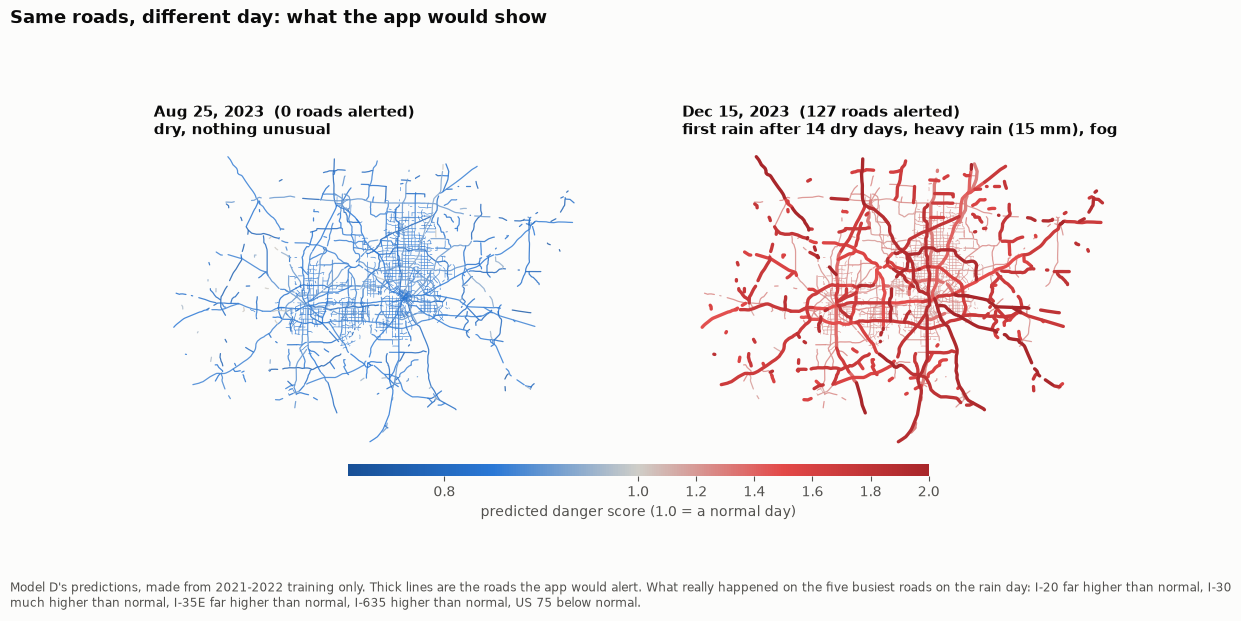

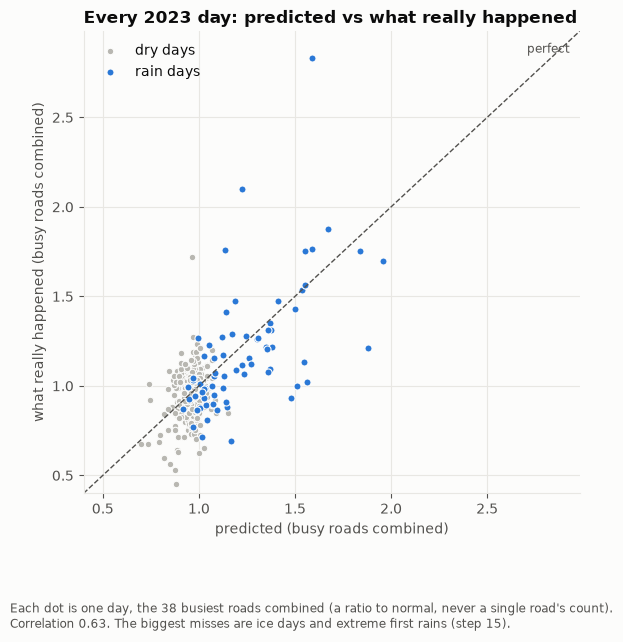

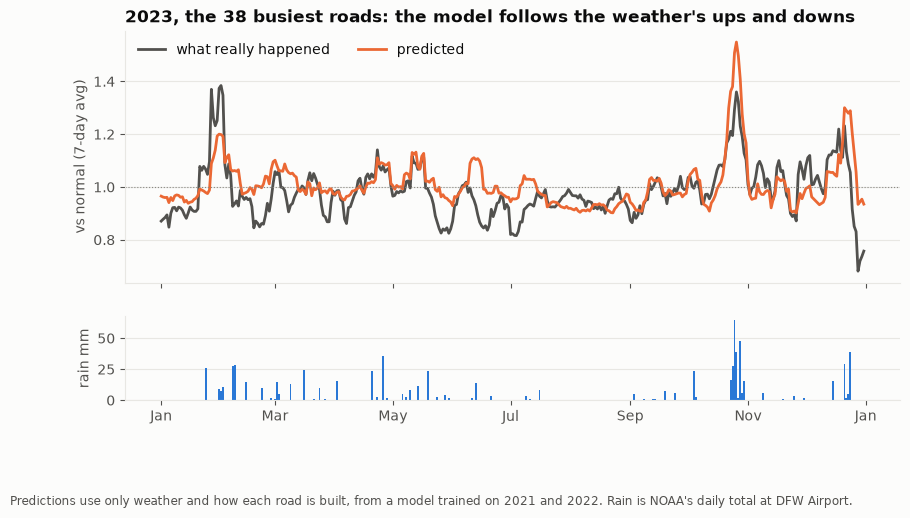

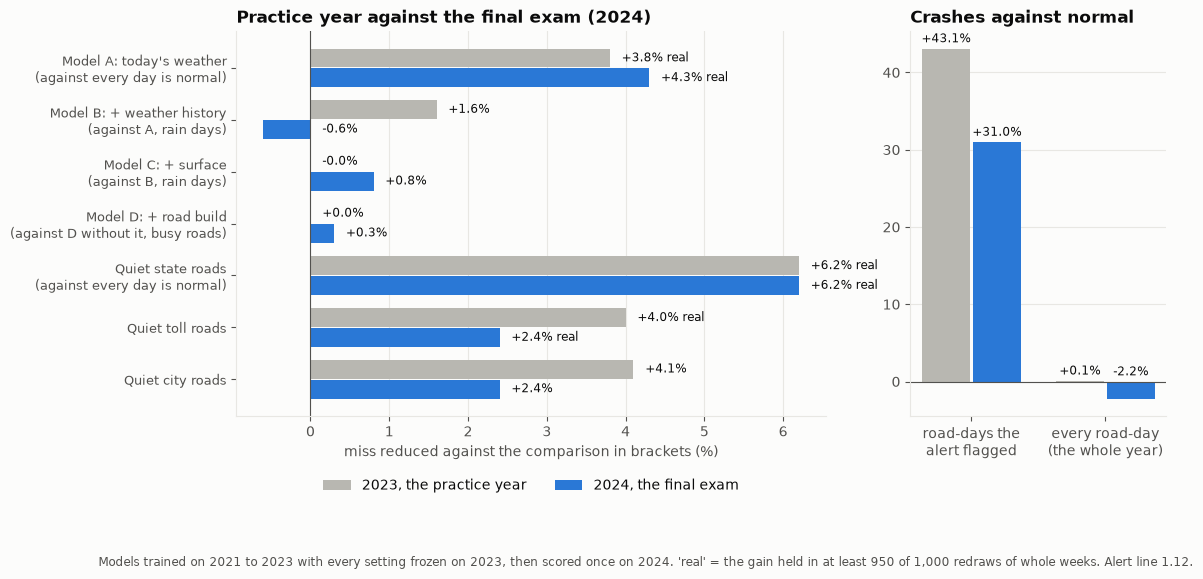

Saved figures: fig1_roads_map.png, fig2_beats_simple_guess.png, fig3_weather_effect.png, fig4_surface_claim.png, fig5_alert_impact.png, fig6_demo_day_map.png, fig7_predicted_vs_actual.png, fig8_through_the_year.png, fig9_final_exam_2024.png


In [24]:
import matplotlib as mpl
import matplotlib.dates  # noqa: F401  (month labels on the time axis)
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

FIG_DIR = os.path.join("..", "docs", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
INK = {"surface": "#fcfcfb", "text": "#0b0b0b", "text2": "#52514e", "muted": "#8a8984", "grid": "#e8e7e3",
       "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "red": "#e34948", "gray": "#b8b7b1"}
mpl.rcParams.update({"figure.facecolor": INK["surface"], "axes.facecolor": INK["surface"], "savefig.facecolor": INK["surface"],
                     "axes.edgecolor": INK["grid"], "axes.labelcolor": INK["text2"], "xtick.color": INK["text2"],
                     "ytick.color": INK["text2"], "text.color": INK["text"], "axes.grid": False, "font.size": 10,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False})
DANGER_CMAP = LinearSegmentedColormap.from_list("danger", ["#184f95", INK["blue"], "#cfcec8", INK["red"], "#a8262a"])
FIGS = {}


def finish(fig, name, subtitle=None, below=0.42):
    if subtitle:
        y = -below / fig.get_size_inches()[1]         # `below` inches under the bottom edge, whatever the height
        fig.text(0.01, y, subtitle, color=INK["text2"], fontsize=8.5, ha="left", va="top", wrap=True)
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    FIGS[name] = path
    plt.show()


def ygrid(ax):
    ax.grid(axis="y", color=INK["grid"], lw=0.8)
    ax.set_axisbelow(True)


def xgrid(ax):
    ax.grid(axis="x", color=INK["grid"], lw=0.8)
    ax.set_axisbelow(True)


# --- Figure 1: the 850 roads on the map, by layer ---
fig, ax = plt.subplots(figsize=(8.4, 6.6))
layer_style = {"city": (INK["gray"], 0.6, "City streets"), "state": (INK["blue"], 1.3, "State roads"),
               "toll": (INK["orange"], 2.0, "Toll roads")}
for lyr in ["city", "state", "toll"]:
    color, lw, label = layer_style[lyr]
    for unit in app_roads.loc[app_roads.layer == lyr, "unit"]:
        for ln in shapes[unit]:
            xs, ys = zip(*ln)
            ax.plot(xs, ys, color=color, lw=lw, solid_capstyle="round")
    ax.plot([], [], color=color, lw=2.5, label=f"{label} ({(app_roads.layer == lyr).sum()})")
ax.set_aspect(1 / np.cos(np.deg2rad(32.8)))
ax.set_xticks([]), ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_visible(False)
ax.legend(loc="lower left", frameon=False)
ax.set_title(f"The {len(app_roads)} Dallas-Fort Worth roads on the app's map (of {len(roads)} scored every day)")
finish(fig, "fig1_roads_map.png", "Each line is built from crash positions: every point is the average of at least 5 crashes, "
       "2020 to 2023. 855 roads are scored; 850 have enough crashes to draw.")

# --- Figure 2: how much each model beats "every day is normal", real vs scrambled weather ---
rows2 = [("Model A: today's weather\n(4 surface groups)", gain_a_real, gain_a_scr),
         ("Model D: busy roads\n(38 roads)", d_busy_real, gain_d_scr)] + \
        [(f"Model D: quiet {l} roads\n(summed per day)", next(r["gain_%"] for r in RESULTS if r["test"] == f"5c. Quiet {l} roads"), None)
         for l in ["state", "toll", "city"]]
fig, ax = plt.subplots(figsize=(8, 4.2))
ypos = np.arange(len(rows2))[::-1]
ax.barh(ypos + 0.18, [r[1] for r in rows2], height=0.34, color=INK["blue"], label="real weather")
scr_vals = [r[2] if r[2] is not None else np.nan for r in rows2]
ax.barh(ypos - 0.18, scr_vals, height=0.34, color=INK["gray"], label="weather shuffled across days")
for y, (lab, real, scr) in zip(ypos, rows2):
    ax.text(real + 0.15, y + 0.18, f"{real:+.1f}%", va="center", fontsize=9, color=INK["text"])
    if scr is not None:
        ax.text(max(scr, 0) + 0.15, y - 0.18, f"{scr:+.1f}%", va="center", fontsize=9, color=INK["text2"])
ax.set_yticks(ypos, [r[0] for r in rows2])
ax.axvline(0, color=INK["text2"], lw=0.8)
xgrid(ax)
ax.set_xlabel("% smaller miss than the simple guess \"every day is normal\" (2023, never seen in training)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.16), ncol=2, frameon=False)
ax.set_title("The edge is modest, and it disappears when the weather is shuffled")
finish(fig, "fig2_beats_simple_guess.png", f"Gray: the same models retrained with the weather shuffled across days (Model D on "
       f"all quiet roads together: {gain_dq_scr:+.1f}%). Every gain turned negative. A gain counts as real if it holds in 950 "
       "of 1,000 redraws of whole weeks.", below=0.75)

# --- Figure 3: what the weather does, all surfaced crashes, 2021-2023 ---
s3 = surf.copy()
bins = [-0.01, 0.29, 5, 12.7, 25, 50, 1e9]
labels3 = ["dry", "under 5", "5 to\n12.7", "12.7\nto 25", "25 to\n50", "50+"]
s3["rain_bucket"] = pd.cut(s3["rain_mm"], bins=bins, labels=labels3)
by_rain = s3.groupby("rain_bucket", observed=True).agg(c=("crashes", "sum"), n=("normal", "sum"), days=("date", "nunique"))
by_rain["pct"] = 100 * (by_rain["c"] / by_rain["n"] - 1)
first3 = s3[(s3["rained"] == 1) & (s3["dry_days_before_rain"] >= 7)]
after3 = s3[(s3["rained"] == 1) & (s3["days_since_rain"] == 1)]
other3 = s3[(s3["rained"] == 1) & (s3["days_since_rain"] > 1) & (s3["dry_days_before_rain"] < 7)]
seq = [("rain the day\nafter rain", after3), ("other\nrain days", other3), ("first rain after\n7+ dry days", first3)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
a1.bar(range(len(by_rain)), by_rain["pct"], color=INK["blue"], width=0.6)
for i, v in enumerate(by_rain["pct"]):
    a1.text(i, v + 1 if v >= 0 else v - 1, f"{v:+.0f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
a1.set_xticks(range(len(by_rain)), [(f"{l} mm" if l != "dry" else l) + f"\n{d} days" for l, d in zip(labels3, by_rain["days"])],
              fontsize=8.5)
a1.set_ylim(min(by_rain["pct"].min() - 6, -8), by_rain["pct"].max() + 7)
a1.axhline(0, color=INK["text2"], lw=0.8)
ygrid(a1)
a1.set_ylabel("crashes vs normal (%)")
a1.set_title("More rain, more crashes")
vals = [100 * (g["crashes"].sum() / g["normal"].sum() - 1) for _, g in seq]
a2.bar(range(3), vals, color=[INK["gray"], INK["gray"], INK["orange"]], width=0.6)
for i, v in enumerate(vals):
    a2.text(i, v + 0.8, f"{v:+.0f}%", ha="center", fontsize=9)
a2.set_xticks(range(3), [l + f"\n{g['date'].nunique()} days" for l, g in seq], fontsize=8.5)
a2.set_ylim(0, max(vals) + 5)
a2.axhline(0, color=INK["text2"], lw=0.8)
a2.set_ylabel("crashes vs normal (%)")
ygrid(a2)
a2.set_title("First rain after a dry spell")
fig.suptitle("What the weather does to crashes (all state-road crashes with a surface code, 2021 to 2023)",
             x=0.01, y=1.04, ha="left", fontsize=11, color=INK["text2"])
fig.tight_layout()
finish(fig, "fig3_weather_effect.png", "Crashes vs each surface group's normal day, summed over the four groups. The first-rain "
       "gap looks large here but did not pass the 950-of-1,000 redraw test (claim 1), because first rains are few and their "
       "rain amounts vary.")

# --- Figure 4: claim 2, the first-rain jump on the six two-surface roads ---
six4 = ["IH 30", "IH 635", "IH 20", "IH 35E", "IH 35W", "SL 12"]
r4 = road[road["date"].dt.year.isin([2021, 2022, 2023])]
rn4, rs4 = r4["unit"].map(info["road_name"]), r4["unit"].map(info["surface"])
fr4 = (r4["rained"] == 1) & (r4["dry_days_before_rain"] >= 7) & rn4.isin(six4)
dry4 = (r4["rained"] == 0) & rn4.isin(six4)
jumps, errs = [], []
for srf in ["asphalt_over_concrete", "concrete"]:
    m_ = rs4 == srf
    full_, _, _, _, draws_ = redraw_stat(r4, {"f": fr4 & m_, "d": dry4 & m_}, lambda x: ratio(x, "f") - ratio(x, "d"), return_draws=True)
    jumps.append(100 * full_)
    errs.append([100 * (full_ - np.percentile(draws_, 2.5)), 100 * (np.percentile(draws_, 97.5) - full_)])
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.bar([0, 1], jumps, yerr=np.array(errs).T, color=[INK["orange"], INK["blue"]], width=0.55,
       error_kw={"ecolor": INK["text2"], "elinewidth": 1, "capsize": 4})
for i, v in enumerate(jumps):
    ax.text(i + 0.32, v, f"{v:+.0f}%", va="center", fontsize=10)
ax.set_xticks([0, 1], ["asphalt over concrete", "concrete"])
ax.axhline(0, color=INK["text2"], lw=0.8)
ygrid(ax)
ax.set_ylabel("first-rain crashes vs that surface's dry days")
ax.set_title("Same roads, same rain: asphalt over concrete jumps more")
finish(fig, "fig4_surface_claim.png", "The six roads with long stretches of both surfaces (IH 30, IH 635, IH 20, IH 35E, IH 35W, "
       "SL 12), 2021 to 2023, 40 first-rain days. Whiskers show the middle 95% of 1,000 redraws of whole weeks. Claim 2 held: the gap was on "
       "the same side in 1,000 of 1,000.")

# --- Figure 5: is the alert worth having? crashes vs normal on the road-days each rule flags, 2023 ---
rows5 = [("All 2023 road-days", YEAR_DRIFT_2023, INK["gray"]),
         ("Warn on every road whenever it rains", float(rule_table.loc["every rain day (simple rule)", "crashes vs normal on flagged road-days"]), INK["gray"]),
         ("Model's first-guess line (no cap)", float(rule_table.loc["global line (plan's first guess)", "crashes vs normal on flagged road-days"]), INK["blue"]),
         (f"The alert the app ships (line + worst {ALERT_TOP_SHARE:.0%} of roads,\nrain or ice days only)" if ALERT_WEATHER_ONLY
          else f"The alert the app ships (line + worst {ALERT_TOP_SHARE:.0%} of roads that day)", IMPACT_SHIPPED_2023["extra_%"], INK["orange"])]
fig, ax = plt.subplots(figsize=(8, 3.2))
yy = np.arange(len(rows5))[::-1]
ax.barh(yy, [r[1] for r in rows5], color=[r[2] for r in rows5], height=0.55)
for y, (lab, v, _) in zip(yy, rows5):
    ax.text(max(v, 0) + 0.8, y, f"{v:+.1f}%", va="center", fontsize=10)
ax.set_yticks(yy, [r[0] for r in rows5])
ax.axvline(0, color=INK["text2"], lw=0.8)
xgrid(ax)
ax.set_xlabel("crashes vs a normal day, on the road-days each rule flags (2023)")
ax.set_title("The alert lands on the road-days that run hottest")
finish(fig, "fig5_alert_impact.png", f"The shipped alert flagged {IMPACT_SHIPPED_2023['flagged_road_days']:,} road-days in 2023, "
       f"at most {int(chosen['most in one day'])} roads on any day; they had {IMPACT_SHIPPED_2023['crashes']:,} crashes against "
       f"{IMPACT_SHIPPED_2023['normal_days_would_bring']:,} on normal days.")

# --- Figure 6: same roads, a dry day next to the demo rain day ---
demo_day = DEMO_2023["first rain after a dry spell"]
dry_demo = DEMO_2023["quiet dry day"]
norm6 = TwoSlopeNorm(vmin=0.7, vcenter=1.0, vmax=2.0)
fig, axes6 = plt.subplots(1, 2, figsize=(12.5, 5.4))
for ax, day in zip(axes6, [dry_demo, demo_day]):
    dd = days_23[pred_23.index.get_loc(day)]
    alerted = {APP_UNITS[i] for i in dd["alert"]}
    for u in sorted(APP_UNITS, key=lambda u: (u in alerted, dd["pred"][APP_POS[u]])):
        color = DANGER_CMAP(norm6(dd["pred"][APP_POS[u]]))
        lw = 2.4 if u in alerted else (0.5 if layer_of[u] == "city" else 0.9)
        for ln in shapes[u]:
            xs, ys = zip(*ln)
            ax.plot(xs, ys, color=color, lw=lw, alpha=1.0 if u in alerted else 0.85, solid_capstyle="round")
    ax.set_aspect(1 / np.cos(np.deg2rad(32.8)))
    ax.set_xticks([]), ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    what = ", ".join(dd["reasons"]).lower() or "dry, nothing unusual"
    ax.set_title(f"{day:%b %-d, %Y}  ({len(alerted)} roads alerted)\n{what}", fontsize=10.5)
dd = days_23[pred_23.index.get_loc(demo_day)]
sm = mpl.cm.ScalarMappable(norm=norm6, cmap=DANGER_CMAP)
cb = fig.colorbar(sm, ax=axes6, orientation="horizontal", fraction=0.035, pad=0.02, aspect=50, shrink=0.6)
cb.set_label("predicted danger score (1.0 = a normal day)", color=INK["text2"])
cb.outline.set_visible(False)
fig.suptitle("Same roads, different day: what the app would show", x=0.01, ha="left", fontsize=13, fontweight="bold")
finish(fig, "fig6_demo_day_map.png", "Model D's predictions, made from 2021-2022 training only. Thick lines are the roads the app "
       "would alert. What really happened on the five busiest roads on the rain day: "
       + ", ".join(f"{by_id.loc[k, 'display_name']} {LEVEL_NAMES[v]}" for k, v in dd["actual_level"].items()) + ".")

# --- Figure 7: predicted against what really happened, every 2023 day (38 busy roads summed) ---
b7 = rte[rte["unit"].isin(busy_units)]
day7 = b7.groupby("date").apply(lambda g: pd.Series({"p": np.average(g["D"], weights=g["normal"]),
                                                     "a": g["crashes"].sum() / g["normal"].sum()}), include_groups=False)
rain7 = wx.loc[day7.index, "rained"] == 1
fig, ax = plt.subplots(figsize=(6.4, 6))
ax.scatter(day7.loc[~rain7, "p"], day7.loc[~rain7, "a"], s=22, color=INK["gray"], edgecolor=INK["surface"], lw=0.8, label="dry days")
ax.scatter(day7.loc[rain7, "p"], day7.loc[rain7, "a"], s=26, color=INK["blue"], edgecolor=INK["surface"], lw=0.8, label="rain days")
lim = [0.4, max(day7["a"].max(), day7["p"].max()) + 0.15]
ax.plot(lim, lim, color=INK["text2"], lw=1, ls="--")
ax.text(lim[1] - 0.05, lim[1] - 0.12, "perfect", ha="right", fontsize=8.5, color=INK["text2"])
for d_ in worst_days.index[:3] if fail_year == 2023 else []:
    ax.annotate(f"{d_:%b %-d}", (day7.loc[d_, "p"], day7.loc[d_, "a"]), xytext=(6, 4), textcoords="offset points", fontsize=8.5)
ax.set_xlim(lim), ax.set_ylim(lim)
ygrid(ax), xgrid(ax)
ax.set_xlabel("predicted (busy roads combined)")
ax.set_ylabel("what really happened (busy roads combined)")
ax.legend(loc="upper left", frameon=False)
corr7 = np.corrcoef(day7["p"], day7["a"])[0, 1]
ax.set_title("Every 2023 day: predicted vs what really happened")
finish(fig, "fig7_predicted_vs_actual.png", f"Each dot is one day, the 38 busiest roads combined (a ratio to normal, never a "
       f"single road's count). Correlation {corr7:.2f}. The biggest misses are ice days and extreme first rains (step 15).")

# --- Figure 8: through the year, predicted and real (7-day average), with rain underneath ---
roll = day7.rolling(7, center=True, min_periods=4).mean()
fig, (t1, t2) = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
t1.plot(roll.index, roll["a"], color=INK["text2"], lw=2, label="what really happened")
t1.plot(roll.index, roll["p"], color=INK["orange"], lw=2, label="predicted")
t1.axhline(1.0, color=INK["muted"], lw=0.8, ls=":")
ygrid(t1)
t1.set_ylabel("vs normal (7-day avg)")
t1.legend(loc="upper left", frameon=False, ncol=2)
t1.set_title("2023, the 38 busiest roads: the model follows the weather's ups and downs")
rain8 = wx.loc[roll.index, "rain_mm"]
t2.bar(rain8.index, rain8, color=INK["blue"], width=1.0)
t2.set_ylabel("rain mm")
t2.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b"))
ygrid(t2)
finish(fig, "fig8_through_the_year.png", "Predictions use only weather and how each road is built, from a model trained on 2021 "
       "and 2022. Rain is NOAA's daily total at DFW Airport.")

# --- Figure 9: the practice year next to the final exam (drawn once 2024 is open) ---
FINAL_ROWS = [("Model A: today's weather\n(against every day is normal)", "2. Model A"),
              ("Model B: + weather history\n(against A, rain days)", "3. Model B"),
              ("Model C: + surface\n(against B, rain days)", "4. Model C"),
              ("Model D: + road build\n(against D without it, busy roads)", "5. Model D"),
              ("Quiet state roads\n(against every day is normal)", "5c. Quiet state roads"),
              ("Quiet toll roads", "5c. Quiet toll roads"),
              ("Quiet city roads", "5c. Quiet city roads")]


def fig_final_exam(exam, year):
    """Each model's gain in 2023 (practice) next to `year` (the exam), and the shipped alert's impact in both."""
    prac = {r["test"]: r for r in RESULTS}
    fin = {r["test"]: r for r in exam["results"].to_dict("records")}
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2.3, 1]})
    yy = np.arange(len(FINAL_ROWS))[::-1]
    for off, src, color, lab in [(0.19, prac, INK["gray"], "2023, the practice year"),
                                 (-0.19, fin, INK["blue"], f"{year}, the final exam")]:
        vals = [float(src[t]["gain_%"]) for _, t in FINAL_ROWS]
        ax.barh(yy + off, vals, height=0.36, color=color, label=lab)
        for y, (_, t), v in zip(yy, FINAL_ROWS, vals):
            ax.text(max(v, 0) + 0.15, y + off, f"{v:+.1f}%" + (" real" if src[t]["passed"] == True else ""),  # noqa: E712 (numpy or Python bool; NaN/None -> no)
                    va="center", fontsize=8.5, color=INK["text"])
    ax.set_yticks(yy, [r[0] for r in FINAL_ROWS], fontsize=9)
    ax.axvline(0, color=INK["text2"], lw=0.8)
    xgrid(ax)
    ax.set_xlabel("miss reduced against the comparison in brackets (%)")
    ax.set_title(f"Practice year against the final exam ({year})")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
    imp_p = [IMPACT_SHIPPED_2023["extra_%"], IMPACT_SHIPPED_2023["all_2023_road_days_vs_normal_%"]]
    imp_f = [exam["impact"]["extra_%"], exam["impact"]["all_road_days_vs_normal_%"]]
    x = np.arange(2)
    for off, vals, color in [(-0.19, imp_p, INK["gray"]), (0.19, imp_f, INK["blue"])]:
        ax2.bar(x + off, vals, width=0.36, color=color)
        for xi, v in zip(x, vals):
            ax2.text(xi + off, max(v, 0) + 0.8, f"{float(v):+.1f}%", ha="center", fontsize=8.5, color=INK["text"])
    ax2.set_xticks(x, ["road-days the\nalert flagged", "every road-day\n(the whole year)"])
    ax2.axhline(0, color=INK["text2"], lw=0.8)
    ygrid(ax2)
    ax2.set_title("Crashes against normal")
    note = (f"Models trained on 2021 to {year - 1} with every setting frozen on 2023, then scored once on {year}. "
            f"'real' = the gain held in at least 950 of 1,000 redraws of whole weeks. Alert line {exam['impact']['alert_line']}.")
    return fig, note


if OPEN_2024:
    fig, note9 = fig_final_exam(final, 2024)
    finish(fig, "fig9_final_exam_2024.png", note9, below=0.85)
else:
    fig, _ = fig_final_exam(dry, 2023)          # dry run on the 2023 stand-in: built, checked, not saved
    plt.close(fig)
    print("fig9 (practice against the 2024 final exam) is drawn once 2024 is open; its code ran on the 2023 stand-in.")

print("Saved figures:", ", ".join(sorted(FIGS)))